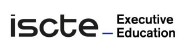

#0. Enquadramento

Este notebook tem como objetivo explorar e modelar o histórico de ordens de trabalho dos equipamentos da cidade de Cincinnati, de forma a identificar padrões de manutenção e desenvolver modelos preditivos que apoiem a gestão dos ativos.

O trabalho iniciou-se com a preparação e tratamento dos dados, corrigindo problemas de qualidade, inconsistências nos formatos, valores omissos e outliers. Posteriormente, foram criadas novas variáveis relacionadas com o histórico de manutenção, custos, idade dos equipamentos, frequência de intervenções e tempos de indisponibilidade, permitindo enriquecer a informação disponível para análise.

Em simultâneo foi realizada uma Análise Exploratória dos Dados (EDA) com o objetivo de compreender a distribuição das variáveis, identificar padrões de utilização e manutenção dos equipamentos e avaliar possíveis relações entre características operacionais, custos e falhas.

Com base nos dados preparados, o projeto pretende desenvolver e comparar diferentes algoritmos de Machine Learning para responder a dois problemas principais: estimar o downtime associado a uma ordem de trabalho e prever a probabilidade de um equipamento regressar à oficina nos 30 dias seguintes a uma intervenção. A avaliação dos modelos permitirá identificar a solução com melhor desempenho preditivo e maior potencial de aplicação prática.

Através desta abordagem pretende-se disponibilizar informação que suporte decisões de manutenção mais informadas, contribuindo para a redução de períodos de indisponibilidade, otimização de recursos e melhor gestão dos custos de manutenção.

# 1. Bibliotecas

Inicialmente procedeu-se à importação de bibliotecas

In [1]:
import joblib
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import (
    RandomizedSearchCV,
    TimeSeriesSplit
)

from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier
)

from xgboost import (
    XGBRegressor,
    XGBClassifier
)

from lightgbm import (
    LGBMRegressor,
    LGBMClassifier
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)

# 2. Funções

Desenvolveram-se funções que permitissem simplificar a aplicação de modelos e tornar o modelo final mais leve

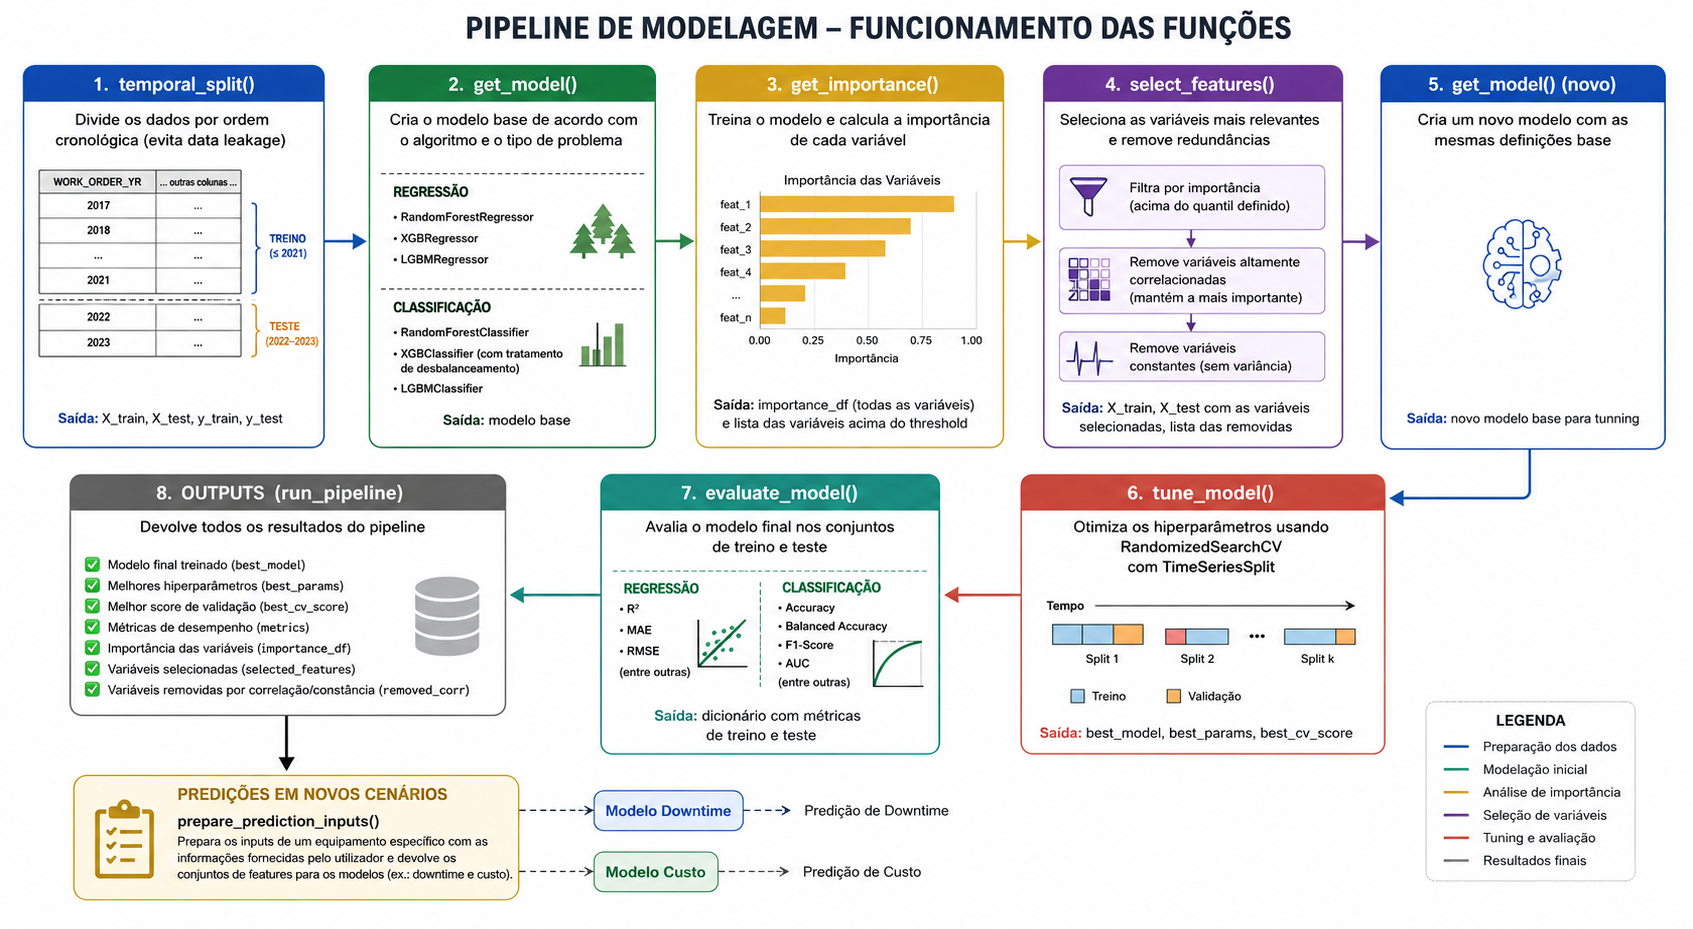

Temporal_Split

Esta função pretende possibilitar as diferentes combinações temporais para modelação, tendo em consideraçõ diferentes possibilidades de targets

In [2]:
def temporal_split(
    df,
    target,
    train_end=2021,
    test_end=2023
):

    TARGETS = [

        "DOWNTIME_CLASS",
        "TARGET_CALCULATED_TOTAL",
        "TARGET_REPAIR_30D",
        "TARGET_DOWNTIME_LOG",
        "TARGET_DOWNTIME_CALC"

    ]

    X = df.drop(
    columns=TARGETS + [
        "UNIQUE_WORK_ORDER_NO",
        "EQ_EQUIP_NO"
    ]
)

    y = df[target]

    train_mask = (
        df["WORK_ORDER_YR"] <= train_end
    )

    test_mask = (
        (df["WORK_ORDER_YR"] > train_end) &
        (df["WORK_ORDER_YR"] <= test_end)
    )

    return (

        X[train_mask],
        X[test_mask],

        y[train_mask],
        y[test_mask]

    )

Get_Model

A função get_model() centraliza a criação dos modelos de Machine Learning utilizados no projeto, permitindo selecionar automaticamente o algoritmo e a respetiva configuração consoante o problema seja de regressão ou classificação. Adicionalmente, incorpora mecanismos para lidar com classes desbalanceadas nos modelos de classificação.

In [3]:
def get_model(

    model_name,

    target_type,

    y_train=None

):

    # =====================================================
    # REGRESSION
    # =====================================================

    if target_type == "regression":

        # =================================================
        # RANDOM FOREST
        # =================================================

        if model_name == "rf":

            return RandomForestRegressor(

                n_estimators=100,

                random_state=42,

                n_jobs=-1

            )

        # =================================================
        # XGBOOST
        # =================================================

        elif model_name == "xgb":

            return XGBRegressor(

                n_estimators=100,

                random_state=42,

                n_jobs=-1

            )

        # =================================================
        # LIGHTGBM
        # =================================================

        elif model_name == "lgbm":

            return LGBMRegressor(

                n_estimators=100,

                random_state=42,

                n_jobs=-1

            )

    # =====================================================
    # CLASSIFICATION
    # =====================================================

    else:

        # =================================================
        # RANDOM FOREST
        # =================================================

        if model_name == "rf":

            return RandomForestClassifier(

                n_estimators=100,

                random_state=42,

                n_jobs=-1,

                class_weight="balanced"

            )

        # =================================================
        # XGBOOST
        # =================================================

        elif model_name == "xgb":

            params = {

                "n_estimators": 100,

                "random_state": 42,

                "n_jobs": -1,

                "eval_metric": "logloss"

            }

            # =============================================
            # APENAS PARA TARGET BINÁRIO
            # =============================================

            if y_train is not None and y_train.nunique() == 2:

                counter = Counter(y_train)

                majority = max(counter.values())

                minority = min(counter.values())

                params["scale_pos_weight"] = (

                    majority / minority

                )

            return XGBClassifier(**params)

        # =================================================
        # LIGHTGBM
        # =================================================

        elif model_name == "lgbm":

            return LGBMClassifier(

                n_estimators=100,

                random_state=42,

                n_jobs=-1,

                class_weight="balanced"

            )

Get_Importance

A função get_importance() treina o modelo, calcula a importância de cada variável explicativa e seleciona automaticamente as variáveis mais relevantes com base num limiar mínimo de importância definido pelo utilizador. Esta abordagem permite reduzir a dimensionalidade dos dados e focar a modelação nas características com maior capacidade preditiva.

In [4]:
def get_importance(
    model,
    X_train,
    y_train,
    threshold=0.01
):

    model.fit(
        X_train,
        y_train
    )

    importance_df = pd.DataFrame({

        "feature": X_train.columns,

        "importance": model.feature_importances_

    })

    importance_df = importance_df.sort_values(
        by="importance",
        ascending=False
    )

    selected = importance_df[
        importance_df["importance"] >= threshold
    ]["feature"].tolist()

    return importance_df, selected

Select_Features

A função select_features() realiza uma seleção automática de variáveis com base na sua importância preditiva e no grau de correlação entre elas. São mantidas apenas as variáveis mais relevantes, removendo características altamente correlacionadas e variáveis constantes, de forma a reduzir a dimensionalidade e melhorar a robustez dos modelos de Machine Learning.

In [5]:
def select_features(

    X,

    importance_df,

    importance_threshold_quantile=0.75,

    corr_threshold=0.90

):

    import numpy as np

    # =====================================================
    # IMPORTANCE THRESHOLD
    # =====================================================

    threshold_value = importance_df["importance"].quantile(

        importance_threshold_quantile

    )

    selected = importance_df[

        importance_df["importance"] >= threshold_value

    ]["feature"].tolist()

    X = X[selected]

    # =====================================================
    # REMOVER ONE-HOT DA CORRELAÇÃO
    # =====================================================

    binary_cols = [

        c for c in X.columns

        if X[c].nunique() <= 2
    ]

    numeric_cols = [

        c for c in X.columns

        if c not in binary_cols
    ]

    X_numeric = X[numeric_cols]

    # =====================================================
    # CORRELAÇÃO
    # =====================================================

    corr_matrix = X_numeric.corr().abs()

    upper = corr_matrix.where(

        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)

    )

    importance_dict = dict(

        zip(
            importance_df["feature"],
            importance_df["importance"]
        )

    )

    to_drop = []

    for col in upper.columns:

        high_corr = upper[col][

            upper[col] > corr_threshold

        ]

        for row in high_corr.index:

            importance_col = importance_dict.get(col, 0)

            importance_row = importance_dict.get(row, 0)

            # remove menos importante

            if importance_col < importance_row:

                to_drop.append(col)

            else:

                to_drop.append(row)

    to_drop = list(set(to_drop))

    X = X.drop(

        columns=to_drop,

        errors="ignore"

    )

    # =====================================================
    # REMOVE CONSTANT FEATURES
    # =====================================================

    constant_cols = [

        c for c in X.columns

        if X[c].nunique() <= 1
    ]

    X = X.drop(

        columns=constant_cols,

        errors="ignore"

    )

    # =====================================================
    # OUTPUT
    # =====================================================

    final_features = X.columns.tolist()

    return (

        X,

        final_features,

        to_drop + constant_cols

    )

Tune_Model

A função tune_model() realiza a otimização automática dos hiperparâmetros dos modelos através de RandomizedSearchCV, utilizando validação cruzada temporal (TimeSeriesSplit). O objetivo é identificar a combinação de parâmetros que maximiza o desempenho preditivo do modelo, devolvendo a melhor configuração encontrada e a respetiva métrica de avaliação.

In [6]:
def tune_model(

    model,

    X_train,

    y_train,

    target_type,

    n_iter=10,

    cv=3

):

    # =====================================================
    # TIME SERIES CV
    # =====================================================

    tscv = TimeSeriesSplit(

        n_splits=cv

    )

    # =====================================================
    # PARAM GRID
    # =====================================================

    param_grid = {

        "n_estimators": [80, 100, 200, 300],

        "learning_rate": [0.03, 0.05],

        "max_depth": [3, 5],

        "subsample": [0.8],

        "num_leaves": [15, 31]

    }

    # =====================================================
    # APENAS TARGET BINÁRIO
    # =====================================================

    if (

        target_type == "classification" and
        y_train.nunique() == 2

    ):

        param_grid["scale_pos_weight"] = [

            1, 2, 5, 10

        ]

    # =====================================================
    # REMOVER PARAMS INVÁLIDOS
    # =====================================================

    valid_params = model.get_params().keys()

    param_grid = {

        k: v for k, v in param_grid.items()

        if k in valid_params

    }

    # =====================================================
    # SCORING
    # =====================================================

    if target_type == "regression":

        scoring = "r2"

    else:

        scoring = "f1_weighted"

    # =====================================================
    # RANDOM SEARCH
    # =====================================================

    search = RandomizedSearchCV(

        estimator=model,

        param_distributions=param_grid,

        n_iter=n_iter,

        cv=tscv,

        scoring=scoring,

        n_jobs=-1,

        random_state=42,

        verbose=1,

        error_score="raise"

    )

    # =====================================================
    # FIT
    # =====================================================

    search.fit(

        X_train,

        y_train

    )

    # =====================================================
    # OUTPUT
    # =====================================================

    best_model = search.best_estimator_

    best_params = search.best_params_

    best_score = search.best_score_

    print("\nBEST PARAMS:")
    print(best_params)

    print("\nBEST CV SCORE:")
    print(round(best_score, 4))

    return best_model, best_params, best_score

Evaluate_Model

A função evaluate_model() avalia o desempenho dos modelos através de métricas específicas para regressão ou classificação. São calculadas métricas nos conjuntos de treino e teste, permitindo medir a capacidade preditiva do modelo e detetar potenciais problemas de generalização, como overfitting ou underfitting.

In [7]:
def evaluate_model(

    model,

    X_train,
    X_test,

    y_train,
    y_test,

    target_type

):

  # =====================================================
    # PREDICTIONS
    # =====================================================

    train_pred = model.predict(X_train)

    test_pred = model.predict(X_test)

    if target_type == "regression":

        results = {

            "train_r2": r2_score(
                y_train,
                train_pred
            ),

            "test_r2": r2_score(
                y_test,
                test_pred
            ),

            "train_mae": mean_absolute_error(
                y_train,
                train_pred
            ),

            "test_mae": mean_absolute_error(
                y_test,
                test_pred
            ),

            "train_rmse": np.sqrt(
                mean_squared_error(
                    y_train,
                    train_pred
                )
            ),

            "test_rmse": np.sqrt(
                mean_squared_error(
                    y_test,
                    test_pred
                )
            )

        }

    else:

        train_proba = model.predict_proba(X_train)

        test_proba = model.predict_proba(X_test)

        n_classes = len(np.unique(y_train))

        try:

            if n_classes == 2:

                train_auc = roc_auc_score(
                    y_train,
                    train_proba[:,1]
                )

                test_auc = roc_auc_score(
                    y_test,
                    test_proba[:,1]
                )

            else:

                train_auc = roc_auc_score(
                    y_train,
                    train_proba,
                    multi_class="ovr",
                    average="weighted"
                )

                test_auc = roc_auc_score(
                    y_test,
                    test_proba,
                    multi_class="ovr",
                    average="weighted"
                )

        except:

            train_auc = np.nan
            test_auc = np.nan

        results = {

            "train_accuracy": accuracy_score(
                y_train,
                train_pred
            ),

            "test_accuracy": accuracy_score(
                y_test,
                test_pred
            ),

            "train_balanced_accuracy": balanced_accuracy_score(
                y_train,
                train_pred
            ),

            "test_balanced_accuracy": balanced_accuracy_score(
                y_test,
                test_pred
            ),

            "train_f1": f1_score(
                y_train,
                train_pred,
                average="weighted"
            ),

            "test_f1": f1_score(
                y_test,
                test_pred,
                average="weighted"
            ),

            "train_auc": train_auc,

            "test_auc": test_auc

        }

    print("\nRESULTS")

    for k, v in results.items():

        print(f"{k}: {round(v,4)}")

    return results

Run_Pipeline

A função run_pipeline() integra todas as etapas do processo de Machine Learning num único fluxo automatizado: divisão temporal dos dados, cálculo da importância das variáveis, seleção de atributos, otimização de hiperparâmetros, treino do modelo final e avaliação do desempenho. O objetivo é garantir um processo consistente, reproduzível e comparável entre diferentes algoritmos e variáveis-alvo.

In [8]:
def run_pipeline(

    df,

    target,

    target_type,

    model_name,

    importance_threshold=0.75,

    corr_threshold=0.90,

    n_iter=10,

    cv=3,

    log_target=False

):



    # =====================================================
    # COPY DF
    # =====================================================

    df = df.copy()

    # =====================================================
    # LOG TRANSFORM TARGET
    # =====================================================

    if log_target:

        df[target] = np.log1p(

            df[target]

        )

    # =====================================================
    # SPLIT TEMPORAL
    # =====================================================

    X_train, X_test, y_train, y_test = temporal_split(

        df=df,

        target=target

    )

    # =====================================================
    # BASELINE MODEL
    # =====================================================

    baseline_model = get_model(

        model_name=model_name,

        target_type=target_type,

        y_train=y_train

    )

    # =====================================================
    # FEATURE IMPORTANCE
    # =====================================================

    importance_df, _ = get_importance(

        baseline_model,

        X_train,

        y_train,

        threshold=0

    )

    # =====================================================
    # FEATURE SELECTION
    # =====================================================

    X_train, final_features, removed_corr = select_features(

        X_train,

        importance_df,

        importance_threshold_quantile=importance_threshold,

        corr_threshold=corr_threshold

    )

    X_test = X_test[final_features]

    # =====================================================
    # NOVO MODELO
    # =====================================================

    tuned_base_model = get_model(

        model_name=model_name,

        target_type=target_type,

        y_train=y_train

    )

    # =====================================================
    # HYPERPARAMETER TUNING
    # =====================================================

    best_model, best_params, best_cv_score = tune_model(

        model=tuned_base_model,

        X_train=X_train,

        y_train=y_train,

        target_type=target_type,

        n_iter=n_iter,

        cv=cv

    )

    # =====================================================
    # FIT FINAL MODEL
    # =====================================================

    best_model.fit(

        X_train,

        y_train

    )

    # =====================================================
    # EVALUATION
    # =====================================================

    metrics = evaluate_model(

        best_model,

        X_train,
        X_test,

        y_train,
        y_test,

        target_type

    )

    # =====================================================
    # OUTPUT
    # =====================================================

    return {

        "target": target,

        "model_name": model_name,

        "target_type": target_type,

        "best_model": best_model,

        "best_params": best_params,

        "best_cv_score": best_cv_score,

        "metrics": metrics,

        "importance_df": importance_df,

        "selected_features": final_features,

        "removed_corr": removed_corr

    }

Prepare_Prediction_Inputs

A função prepare_prediction_inputs() prepara os dados necessários para a realização de previsões num equipamento específico. A partir do histórico mais recente do ativo e dos parâmetros introduzidos pelo utilizador, são gerados os conjuntos de variáveis utilizados pelos modelos de previsão de downtime e de custos.

In [9]:
def prepare_prediction_inputs(

    df,
    equip_no,

    priority_code,
    job_type_repair,
    work_order_year,
    create_month

):

    # =====================================================
    # ÚLTIMA OT DO EQUIPAMENTO
    # =====================================================

    row = (

        df[df["EQ_EQUIP_NO"] == equip_no]

        .head(1)

        .copy()

    )

    # =====================================================
    # INPUTS UTILIZADOR
    # =====================================================

    row["PRI_PRIORITY_CODE"] = priority_code

    row["JOB_TYPE_REPAIR"] = job_type_repair

    row["WORK_ORDER_YR"] = work_order_year

    row["CREATE_MONTH"] = create_month

    # =====================================================
    # FEATURES MODELOS
    # =====================================================

    X_downtime = row[downtime_features]

    X_cost = row[cost_features]

    return X_downtime, X_cost

# 3. Carregamento dos Dados

Durante o carregamento dos dados, foram identificadas inconsistências no ficheiro CSV, nomeadamente erros de formatação, tendo sido retificados.

In [10]:
#Carregamento do ficheiro

df = pd.read_csv(
    "dataset.csv",
    encoding="latin1",
    decimal=",",
    thousands="\xa0",
    engine="python"
)

In [11]:
# Remover caracteres estranhos em todas as colunas texto

for col in df.select_dtypes(include="object").columns:

    df[col] = (
        df[col]
        .astype(str)
        .str.replace("Â", "", regex=False)
        .str.replace("\xa0", "", regex=False)
        .str.strip()
    )

In [12]:
#Configuração de floats para duas casas décimais

pd.set_option(
    "display.float_format",
    "{:.2f}".format
)

In [13]:
#Conversão de falsos NANs

df = df.replace([
    "nan",
    "NaN",
    "NULL",
    "null",
    "",
    " "
], np.nan)

In [14]:
#Primeira análise ao dataset

pd.set_option('display.max_columns', None)
df.head(5)

,UNIQUE_WORK_ORDER_NO,CREATE_DATE,LOC_WORK_ORDER_LOC,LOC_WORK_ORDER_LOC_NAME,WORK_ORDER_YR,WORK_ORDER_NO,JOB_TYPE,EQ_EQUIP_NO,WORK_ORDER_STATUS,METER_1_READING,DATETIME_OUT_SERVICE,DATETIME_IN_SERVICE,DATETIME_OPEN,DATETIME_FIRST_LABOR,DATETIME_FINISHED,DATETIME_CLOSED,DATETIME_UNIT_IN,DATETIME_DUE,DATETIME_PM_SCHED,QTY_EST_HOURS,DOWNTIME_HRS_USER,DOWNTIME_HRS_SHOP,WARRANTY,REAS_REAS_FOR_REPAIR,REAS_FOR_REPAIR_DESC,PRI_PRIORITY_CODE,REF_WORK_ORDER_NO,DEPT_EQUIP_DEPT,DEPT_EQUIP_DEPT_NAME,METER_1_LIFE_TOTAL,EQ_PARENT_EQUIP_NO,DELAY_HOURS,LABOR_HOURS,LABOR_COST,PARTS_COST,COMML_COST,TOTAL_COST
0,2023-3001-1390,2023 Aug 07 12:00:00 AM,3001,WATER WORKS/PROPANE,2023,1390,REPAIR,60959,OPEN,43291,2023 Aug 07 12:00:00 AM,NaN,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,NaN,NaN,2023 Aug 07 12:00:00 AM,2023 Aug 10 12:00:00 AM,NaN,0.00,0,0,NO,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,43291,60959,0,2.18,239.8,0,0,239.8
1,2023-4145-273,2023 Aug 07 12:00:00 AM,4145,"NEW EQUIP SHOP - ""J"" ONLY",2023,273,REPAIR,21951,OPEN,528,2023 Aug 07 12:00:00 AM,NaN,2023 Aug 07 12:00:00 AM,2023 Aug 08 12:00:00 AM,NaN,NaN,2023 Aug 07 12:00:00 AM,2023 Aug 10 12:00:00 AM,NaN,0.00,0,0,NO,J,PIS-GENERAL (TARGET),3,NaN,0200,PARK DEPARTMENT,528,21951,0,0.5,55,0,0,55
2,2023-2205-312,2023 Aug 07 12:00:00 AM,2205,POLICE DISTRICT 5,2023,312,REPAIR,21306,WORK FINISHED,15942,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,NaN,2023 Aug 07 12:00:00 AM,2023 Aug 10 12:00:00 AM,NaN,0.00,0.05,0.05,YES,N,NORMAL WEAR (TARGET),3,NaN,0222,POLICE,15942,21306,0,1,110,0,0,110
3,2023-4131-718,2023 Aug 07 12:00:00 AM,4131,TIRE SHOP,2023,718,REPAIR,92830,CLOSED,398,2023 Aug 07 12:00:00 AM,2023 Aug 08 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 08 12:00:00 AM,2023 Aug 08 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 10 12:00:00 AM,NaN,0.00,23.18,23.18,NO,N,NORMAL WEAR (TARGET),3,NaN,0253,NEIGHBORHOOD OPERATIONS,398,92830,0,2,220,200.48,4,424.48
4,2023-3001-1389,2023 Aug 07 12:00:00 AM,3001,WATER WORKS/PROPANE,2023,1389,REPAIR,10797,WORK FINISHED,41248,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,2023 Aug 07 12:00:00 AM,NaN,2023 Aug 07 12:00:00 AM,2023 Aug 10 12:00:00 AM,NaN,0.00,0.03,0.03,NO,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,41248,10797,0,0.75,82.5,5.97,0,88.47


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332420 entries, 0 to 332419
Data columns (total 37 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   UNIQUE_WORK_ORDER_NO     332420 non-null  object 
 1   CREATE_DATE              332420 non-null  object 
 2   LOC_WORK_ORDER_LOC       332420 non-null  int64  
 3   LOC_WORK_ORDER_LOC_NAME  332420 non-null  object 
 4   WORK_ORDER_YR            332420 non-null  object 
 5   WORK_ORDER_NO            332420 non-null  object 
 6   JOB_TYPE                 332420 non-null  object 
 7   EQ_EQUIP_NO              332420 non-null  object 
 8   WORK_ORDER_STATUS        332420 non-null  object 
 9   METER_1_READING          332420 non-null  object 
 10  DATETIME_OUT_SERVICE     332414 non-null  object 
 11  DATETIME_IN_SERVICE      331002 non-null  object 
 12  DATETIME_OPEN            332409 non-null  object 
 13  DATETIME_FIRST_LABOR     318184 non-null  object 
 14  DATE

# 4  Tratamento de dados + EDA

À medida que os dados eram tratados e preparados para modelação, foi realizada uma análise exploratória contínua, permitindo compreender a sua estrutura, identificar problemas de qualidade e obter os primeiros insights sobre as variáveis disponíveis. O objetivo passou por analisar e tratar em simultâneo cada variável tornando o Notebook mais leve.

## 4.1 Tratamento Inicial

Tratamento de datas

In [16]:
date_cols = [
    "CREATE_DATE",
    "DATETIME_OUT_SERVICE",
    "DATETIME_IN_SERVICE",
    "DATETIME_OPEN",
    "DATETIME_FIRST_LABOR",
    "DATETIME_FINISHED",
    "DATETIME_CLOSED",
    "DATETIME_UNIT_IN",
    "DATETIME_DUE",
    "DATETIME_PM_SCHED"
]

for col in date_cols:
    df[col] = pd.to_datetime(
        df[col],
        format="%Y %b %d %I:%M:%S %p",
        errors="coerce"
    )

Tratamento de valores numéricos

In [17]:
num_cols = [
    "METER_1_READING",
    "METER_1_LIFE_TOTAL",
    "QTY_EST_HOURS",
    "DOWNTIME_HRS_USER",
    "DOWNTIME_HRS_SHOP",
    "DELAY_HOURS",
    "LABOR_HOURS",
    "LABOR_COST",
    "PARTS_COST",
    "COMML_COST",
    "TOTAL_COST"
]

for col in num_cols:

    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

Confirmação das correções

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 332420 entries, 0 to 332419
Data columns (total 37 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   UNIQUE_WORK_ORDER_NO     332420 non-null  object        
 1   CREATE_DATE              332420 non-null  datetime64[ns]
 2   LOC_WORK_ORDER_LOC       332420 non-null  int64         
 3   LOC_WORK_ORDER_LOC_NAME  332420 non-null  object        
 4   WORK_ORDER_YR            332420 non-null  object        
 5   WORK_ORDER_NO            332420 non-null  object        
 6   JOB_TYPE                 332420 non-null  object        
 7   EQ_EQUIP_NO              332420 non-null  object        
 8   WORK_ORDER_STATUS        332420 non-null  object        
 9   METER_1_READING          332420 non-null  int64         
 10  DATETIME_OUT_SERVICE     332414 non-null  datetime64[ns]
 11  DATETIME_IN_SERVICE      331002 non-null  datetime64[ns]
 12  DATETIME_OPEN   

remover OT's abertas

In [19]:
df = df[df["WORK_ORDER_STATUS"] != "OPEN"]

Contagem de Missing Values

In [20]:
missing = df.isnull().sum().sort_values(ascending=False)

missing_percentage = (
    (df.isnull().sum() / len(df)) * 100
).sort_values(ascending=False)

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": missing_percentage
})

missing_df

,Missing Values,Percentage
REF_WORK_ORDER_NO,330737,99.91
DATETIME_PM_SCHED,253574,76.60
REAS_FOR_REPAIR_DESC,32177,9.72
REAS_REAS_FOR_REPAIR,32177,9.72
DATETIME_FIRST_LABOR,13882,4.19
DATETIME_CLOSED,709,0.21
DATETIME_IN_SERVICE,229,0.07
DATETIME_OPEN,11,0.00
DATETIME_DUE,6,0.00
DATETIME_OUT_SERVICE,6,0.00


Distribuição de Variáveis Numéricas

In [21]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns

df[num_cols].describe()

,LOC_WORK_ORDER_LOC,METER_1_READING,QTY_EST_HOURS,DOWNTIME_HRS_USER,DOWNTIME_HRS_SHOP,PRI_PRIORITY_CODE,METER_1_LIFE_TOTAL,DELAY_HOURS,LABOR_HOURS,LABOR_COST,PARTS_COST,COMML_COST,TOTAL_COST
count,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00
mean,3420.02,51949.67,0.41,222.95,167.21,2.98,54002.12,18.82,3.39,271.49,280.31,8.59,560.39
std,855.86,45122.47,1.93,954.03,695.69,0.20,64368.09,244.55,10.37,842.55,1113.44,426.94,1731.79
min,2201.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,-22.60,-2034.00,-6228.98,-16342.29,-6748.44
25%,2301.00,11750.00,0.00,0.33,0.38,3.00,12356.75,0.00,0.70,50.40,2.44,0.00,85.27
50%,3902.00,45266.00,0.00,18.37,12.64,3.00,45735.50,0.00,1.40,107.10,40.75,0.00,182.06
75%,4110.00,81613.25,0.00,113.42,75.45,3.00,81960.00,0.00,3.00,233.10,185.62,0.00,446.24
max,9001.00,999999.00,505.00,47435.28,41023.09,4.00,5145382.00,21383.52,1154.40,81537.51,82512.63,141728.75,143137.01


Criação do dataset Master e do Dataset DF

O dataset Master será tratado estritamente na medida no necessário para efeitos de desenvolvimento do dashboard e assim conter atributos mais orientados ao utilizador, o dataset df será tratado na integra para efeitos de modelação dos dados.

O que une estes datasets são os nºs únicos de OT's

In [22]:
master_df = df.copy()

In [23]:
master_df.head(2)

,UNIQUE_WORK_ORDER_NO,CREATE_DATE,LOC_WORK_ORDER_LOC,LOC_WORK_ORDER_LOC_NAME,WORK_ORDER_YR,WORK_ORDER_NO,JOB_TYPE,EQ_EQUIP_NO,WORK_ORDER_STATUS,METER_1_READING,DATETIME_OUT_SERVICE,DATETIME_IN_SERVICE,DATETIME_OPEN,DATETIME_FIRST_LABOR,DATETIME_FINISHED,DATETIME_CLOSED,DATETIME_UNIT_IN,DATETIME_DUE,DATETIME_PM_SCHED,QTY_EST_HOURS,DOWNTIME_HRS_USER,DOWNTIME_HRS_SHOP,WARRANTY,REAS_REAS_FOR_REPAIR,REAS_FOR_REPAIR_DESC,PRI_PRIORITY_CODE,REF_WORK_ORDER_NO,DEPT_EQUIP_DEPT,DEPT_EQUIP_DEPT_NAME,METER_1_LIFE_TOTAL,EQ_PARENT_EQUIP_NO,DELAY_HOURS,LABOR_HOURS,LABOR_COST,PARTS_COST,COMML_COST,TOTAL_COST
2,2023-2205-312,2023-08-07,2205,POLICE DISTRICT 5,2023,312,REPAIR,21306,WORK FINISHED,15942,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,NaT,2023-08-07,2023-08-10,NaT,0.00,0.05,0.05,YES,N,NORMAL WEAR (TARGET),3,NaN,0222,POLICE,15942,21306,0.00,1.00,110.00,0.00,0.00,110.00
3,2023-4131-718,2023-08-07,4131,TIRE SHOP,2023,718,REPAIR,92830,CLOSED,398,2023-08-07,2023-08-08,2023-08-07,2023-08-07,2023-08-08,2023-08-08,2023-08-07,2023-08-10,NaT,0.00,23.18,23.18,NO,N,NORMAL WEAR (TARGET),3,NaN,0253,NEIGHBORHOOD OPERATIONS,398,92830,0.00,2.00,220.00,200.48,4.00,424.48


## 4.2 Create_Date e WORK_ORDER_YR

correção do ano da ordem de trabalho(OT)

In [24]:
df["WORK_ORDER_YR"] = df["WORK_ORDER_YR"].str.replace(r"\s+", "", regex=True)
df["WORK_ORDER_YR"] = df["WORK_ORDER_YR"].astype(int)

In [25]:
master_df["WORK_ORDER_YR"] = (
    master_df["WORK_ORDER_YR"]
    .str.replace(r"\s+", "", regex=True)
    .astype(int)
)

In [26]:
df["WORK_ORDER_YR"].unique()

array([2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014, 2013,
       2012, 2011, 2010, 2009, 2008, 2007])

A variável Create_Date permite a criação de duas novas variáveis o mês e o dia da semana, permitindo descobrir tendencias, posteriormente esta variável é removida

In [27]:
df["CREATE_MONTH"] = df["CREATE_DATE"].dt.month

In [28]:
df["CREATE_MONTH"].unique()

array([ 8,  7,  6,  5,  4,  3,  2,  1, 12, 11, 10,  9], dtype=int32)

In [29]:
df["CREATE_DAYOFWEEK"] = df["CREATE_DATE"].dt.dayofweek

In [30]:
df["CREATE_DAYOFWEEK"].unique()

array([0, 4, 2, 1, 3, 6, 5], dtype=int32)

Verificação de nulos

In [31]:
df[[
    "CREATE_MONTH",
    "CREATE_DAYOFWEEK",
    "WORK_ORDER_YR"
]].isnull().sum()

,0
CREATE_MONTH,0
CREATE_DAYOFWEEK,0
WORK_ORDER_YR,0


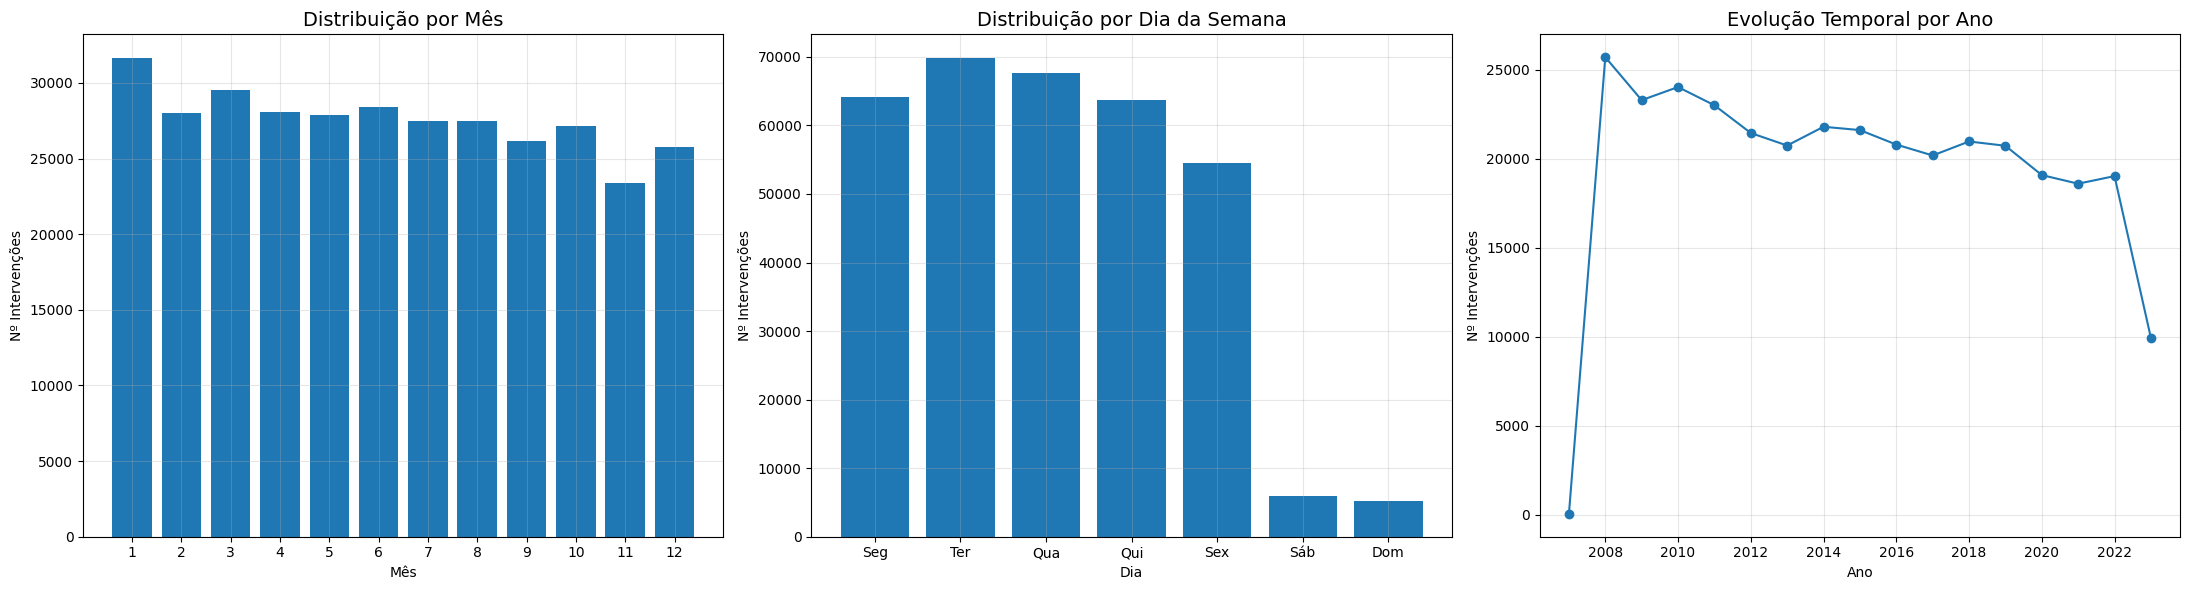

In [32]:
# -------------------------
# Contagens
# -------------------------

month_counts = (
    df["CREATE_MONTH"]
    .value_counts()
    .sort_index()
)

weekday_counts = (
    df["CREATE_DAYOFWEEK"]
    .value_counts()
    .sort_index()
)

year_counts = (
    df["WORK_ORDER_YR"]
    .value_counts()
    .sort_index()
)

# -------------------------
# Criar figura
# -------------------------

fig, axes = plt.subplots(1, 3, figsize=(22,6))

# =====================================================
# 1. MÊS
# =====================================================

axes[0].bar(
    month_counts.index,
    month_counts.values
)

axes[0].set_title(
    "Distribuição por Mês",
    fontsize=14
)

axes[0].set_xlabel("Mês")
axes[0].set_ylabel("Nº Intervenções")
axes[0].set_xticks(range(1,13))
axes[0].grid(alpha=0.3)

# =====================================================
# 2. DIA DA SEMANA
# =====================================================

axes[1].bar(
    weekday_counts.index,
    weekday_counts.values
)

dias = [
    "Seg",
    "Ter",
    "Qua",
    "Qui",
    "Sex",
    "Sáb",
    "Dom"
]

axes[1].set_title(
    "Distribuição por Dia da Semana",
    fontsize=14
)

axes[1].set_xlabel("Dia")
axes[1].set_ylabel("Nº Intervenções")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(dias)
axes[1].grid(alpha=0.3)

# =====================================================
# 3. ANO
# =====================================================

axes[2].plot(
    year_counts.index,
    year_counts.values,
    marker='o'
)

axes[2].set_title(
    "Evolução Temporal por Ano",
    fontsize=14
)

axes[2].set_xlabel("Ano")
axes[2].set_ylabel("Nº Intervenções")
axes[2].grid(alpha=0.3)

# -------------------------
# Layout
# -------------------------

plt.tight_layout()

plt.show()

## 4.3 LOC_WORK_ORDER_LOC e LOC_WORK_ORDER_LOC_NAME

Estas duas variáveis são referentes às localizações das oficinas muitas das vezes inseridas no departamento que opera o equipamento

verificação de nulos

In [33]:
df["LOC_WORK_ORDER_LOC_NAME"].isnull().sum()

np.int64(0)

Localização das oficinas

In [34]:
df["LOC_WORK_ORDER_LOC_NAME"].nunique()

30

In [35]:
df["LOC_WORK_ORDER_LOC_NAME"].value_counts().head(30)

,count
LOC_WORK_ORDER_LOC_NAME,
LIGHT CAR SHOP,61710
SPECIALIZED EQUIPMENT,43025
WEST FORK,32256
WATER WORKS/PROPANE,25524
MSD-GALBRAITH,22410
TIRE SHOP,17871
MSD-GEST,16679
FIRE SHOP,16042
POLICE DISTRICT 1,13145


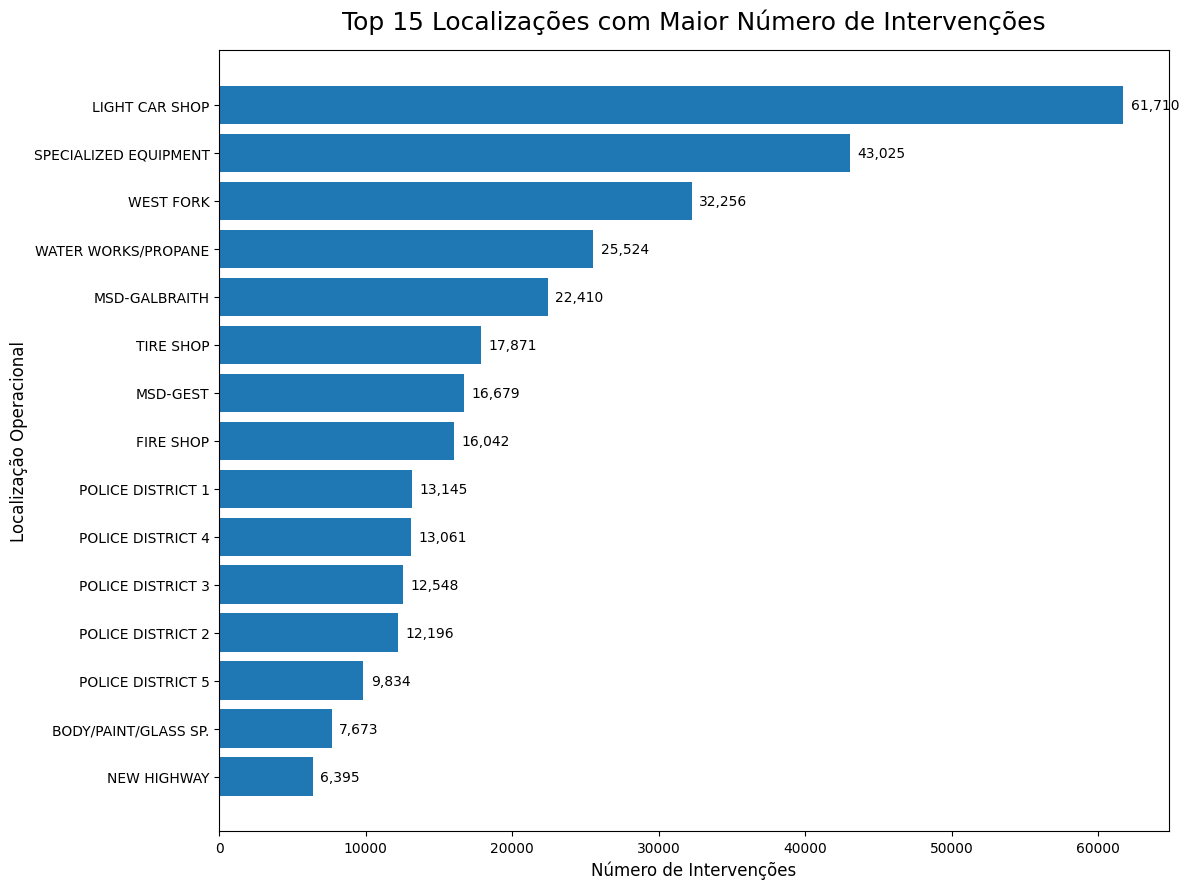

In [36]:
# Top 15 localizações
top_locations = (
    df["LOC_WORK_ORDER_LOC_NAME"]
    .value_counts()
    .head(15)
    .sort_values()
)

# Criar figura
plt.figure(figsize=(12,9))

# Barras horizontais
bars = plt.barh(
    top_locations.index,
    top_locations.values
)

# Título
plt.title(
    "Top 15 Localizações com Maior Número de Intervenções",
    fontsize=18,
    pad=15
)

# Labels
plt.xlabel(
    "Número de Intervenções",
    fontsize=12
)

plt.ylabel(
    "Localização Operacional",
    fontsize=12
)


# Adicionar valores nas barras
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 500,
        bar.get_y() + bar.get_height()/2,
        f"{int(width):,}",
        va='center'
    )

# Melhorar layout
plt.tight_layout()

# Mostrar
plt.show()

Concentrar as localizações acima do top 9 no grupo other, o objetivo era reduzir outliers

In [37]:
# Obter top 9 localizações
top_9_locations = (
    df["LOC_WORK_ORDER_LOC_NAME"]
    .value_counts()
    .head(9)
    .index
)

# Substituir restantes categorias por "OTHER"
df["LOC_WORK_ORDER_LOC_NAME"] = df[
    "LOC_WORK_ORDER_LOC_NAME"
].apply(
    lambda x: x if x in top_9_locations else "OTHER"
)

In [38]:
df["LOC_WORK_ORDER_LOC_NAME"].value_counts()

,count
LOC_WORK_ORDER_LOC_NAME,
OTHER,82378
LIGHT CAR SHOP,61710
SPECIALIZED EQUIPMENT,43025
WEST FORK,32256
WATER WORKS/PROPANE,25524
MSD-GALBRAITH,22410
TIRE SHOP,17871
MSD-GEST,16679
FIRE SHOP,16042


## 4.4 JOB_TYPE

Esta variável estabelece aqueles que são trabalhos de reparação e manutenções planeadas

Verificação de nulos

In [39]:
df["JOB_TYPE"].isnull().sum()

np.int64(0)

Contagem de OT's por tipologia

In [40]:
df["JOB_TYPE"].value_counts()

,count
JOB_TYPE,
REPAIR,253600
PM,77440


Representação gráfica da contagem

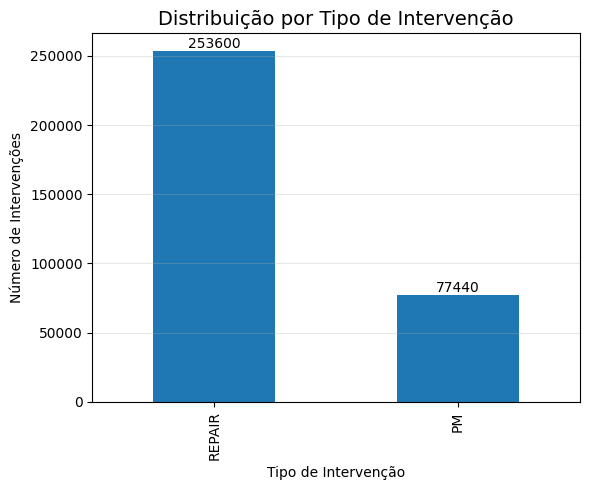

In [41]:
ax = df["JOB_TYPE"].value_counts().plot(
    kind="bar",
    figsize=(6,5)
)

plt.title(
    "Distribuição por Tipo de Intervenção",
    fontsize=14
)

plt.xlabel("Tipo de Intervenção")
plt.ylabel("Número de Intervenções")

plt.grid(axis="y", alpha=0.3)

# Adicionar valores nas barras
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

## 4.5 EQ_EQUIP_NO

 Esta variável representa o código do equipamento

Verificação de nulos

In [42]:
df["EQ_EQUIP_NO"].isnull().sum()

np.int64(0)

Contagem de equipamentos integrados no mapa de OT's

In [43]:
df["EQ_EQUIP_NO"].nunique()

8246

Análise aos equipamentos com mais reparações

In [44]:
df["EQ_EQUIP_NO"].value_counts().head(10)

,count
EQ_EQUIP_NO,
X0400,1235
X0222,759
X0252,676
X0271,627
S61557,494
S81556,494
S71565,491
S71564,491
DE71560,484


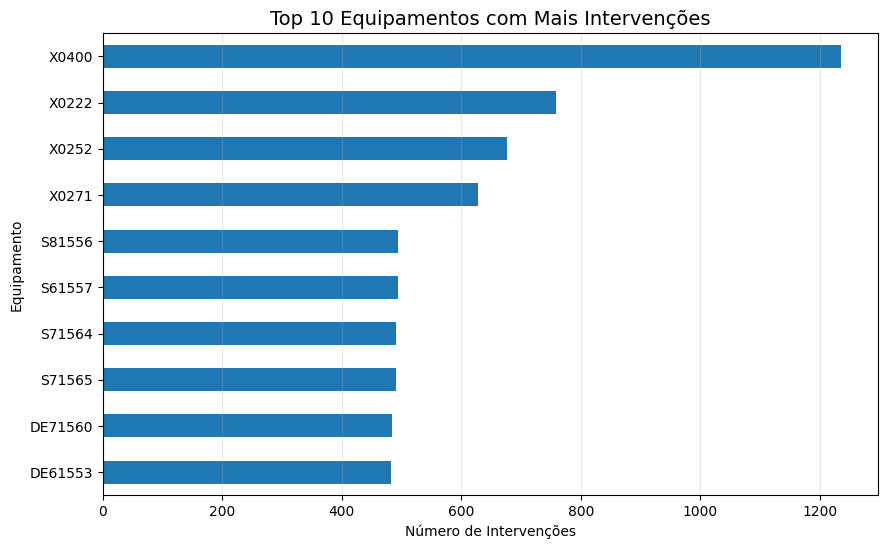

In [45]:
top_equipment = (
    df["EQ_EQUIP_NO"]
    .value_counts()
    .head(10)
    .sort_values()
)

top_equipment.plot(
    kind="barh",
    figsize=(10,6)
)

plt.title(
    "Top 10 Equipamentos com Mais Intervenções",
    fontsize=14
)

plt.xlabel("Número de Intervenções")
plt.ylabel("Equipamento")

plt.grid(axis="x", alpha=0.3)

plt.show()

::Aqui uma vez que modelos como Random Forest não conseguem efetuar processamento sobre letras, atribui-se a cada equipamento um ID numérico permitindo conservar este dado numa nova variável (é exportado automaticamente um ficheiro excel com esses ID's)

In [46]:
# Criar encoder
le = LabelEncoder()

# Criar coluna numérica
df["EQ_EQUIP_ID"] = le.fit_transform(
    df["EQ_EQUIP_NO"]
)

# Criar tabela de correspondência
mapping = pd.DataFrame({
    "EQ_EQUIP_NO": le.classes_,
    "EQ_EQUIP_ID": range(len(le.classes_))
})

# Exportar para Excel
mapping.to_excel(
    "equipment_mapping.xlsx",
    index=False
)

print("Ficheiro criado com sucesso!")

Ficheiro criado com sucesso!


## 4.6 METER_1_READING

Esta variável representa as leituras de conta KM's, é um indicador de utilização de equipamento

In [47]:
df["METER_1_READING"].describe()

,METER_1_READING
count,331040.00
mean,51949.67
std,45122.47
min,0.00
25%,11750.00
50%,45266.00
75%,81613.25
max,999999.00


Verificação de registos sem contagem representando 6,36% do Dataset

In [48]:
(
    (df["METER_1_READING"] == 0)
    .mean() * 100
).round(2)

np.float64(6.36)

Aplicação da Mediana para os casos omissos

In [49]:
median_value = df.loc[
    df["METER_1_READING"] > 0,
    "METER_1_READING"
].median()

df["METER_1_READING"] = (
    df["METER_1_READING"]
    .replace(0, median_value)
)

Representação Gráfica da última contagem de cada equipamento, existe uma forte prevalencia de viaturas com 500000KM's indicando que existe um desgaste elevado.

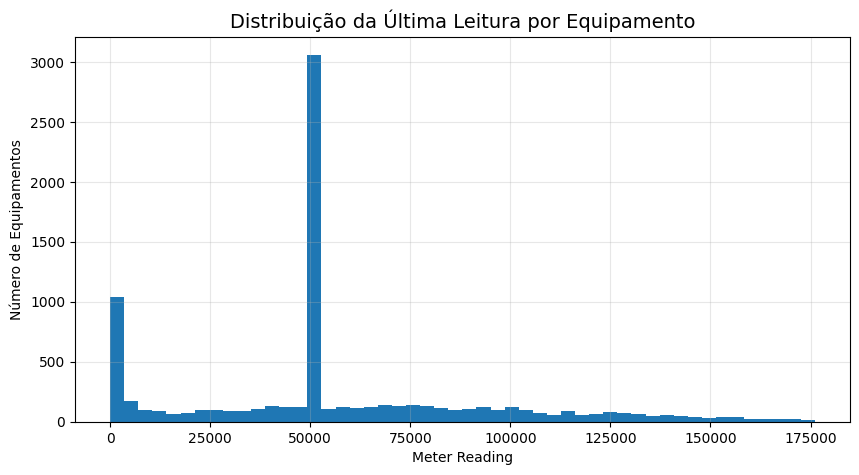

In [50]:
# =====================================================
# Última leitura por equipamento
# =====================================================

latest_meter = (
    df
    .sort_values("CREATE_DATE")
    .groupby("EQ_EQUIP_NO")
    .tail(1)
)

# =====================================================
# Histograma da última leitura
# =====================================================

limit = latest_meter["METER_1_READING"].quantile(0.99)

latest_meter[
    latest_meter["METER_1_READING"] <= limit
]["METER_1_READING"].hist(
    bins=50,
    figsize=(10,5)
)

plt.title(
    "Distribuição da Última Leitura por Equipamento",
    fontsize=14
)

plt.xlabel("Meter Reading")
plt.ylabel("Número de Equipamentos")

plt.grid(alpha=0.3)

plt.show()


Criação da variável HAS_METER_READING para distinguir as viaturas que possuem zero no contador das que já possuem valores usperiroes a zero


In [51]:
df["HAS_METER_READING"] = (
    df["METER_1_READING"] > 0
).astype(int)

## 4.7 Variáveis Operacionais de reparação:
    "DATETIME_OUT_SERVICE",
    "DATETIME_IN_SERVICE",
    "DATETIME_OPEN",
    "DATETIME_FIRST_LABOR",
    "DATETIME_FINISHED",
    "DATETIME_CLOSED",
    "DATETIME_UNIT_IN",
    "DATETIME_DUE",
    "DATETIME_PM_SCHED"

são variáveis que não serão consideradas para modelação no entanto auxiliam na criação do dashboard

Verificação de nulos

In [52]:
date_cols = [
    "DATETIME_OUT_SERVICE",
    "DATETIME_IN_SERVICE",
    "DATETIME_OPEN",
    "DATETIME_FIRST_LABOR",
    "DATETIME_FINISHED",
    "DATETIME_CLOSED",
    "DATETIME_UNIT_IN",
    "DATETIME_DUE",
    "DATETIME_PM_SCHED"
]

# Contar NaNs apenas nas colunas temporais
df[date_cols].isnull().sum().sort_values(ascending=False)

,0
DATETIME_PM_SCHED,253574
DATETIME_FIRST_LABOR,13882
DATETIME_CLOSED,709
DATETIME_IN_SERVICE,229
DATETIME_OPEN,11
DATETIME_OUT_SERVICE,6
DATETIME_FINISHED,6
DATETIME_UNIT_IN,6
DATETIME_DUE,6


Aplicação de uma sequência lógica para valores que estejam inconsistentes para preencher casos omissos

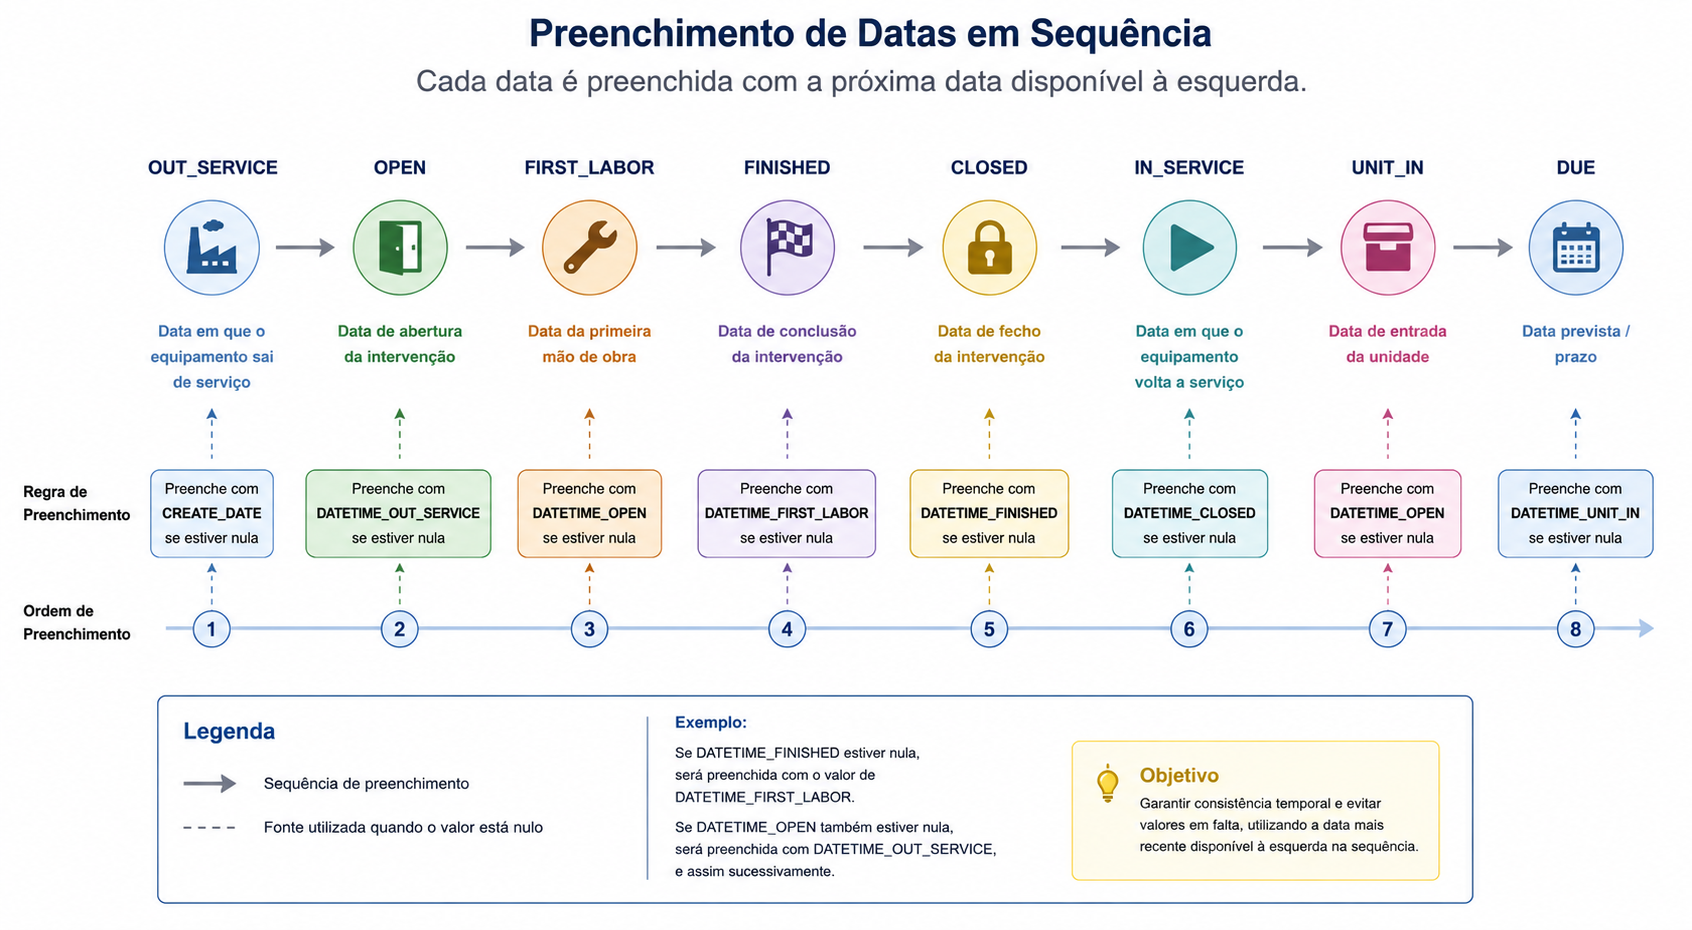

In [53]:
# OUT_SERVICE
df["DATETIME_OUT_SERVICE"] = (
    df["DATETIME_OUT_SERVICE"]
    .fillna(df["CREATE_DATE"])
)

# OPEN
df["DATETIME_OPEN"] = (
    df["DATETIME_OPEN"]
    .fillna(df["DATETIME_OUT_SERVICE"])
)

# FIRST_LABOR
df["DATETIME_FIRST_LABOR"] = (
    df["DATETIME_FIRST_LABOR"]
    .fillna(df["DATETIME_OPEN"])
)

# FINISHED
df["DATETIME_FINISHED"] = (
    df["DATETIME_FINISHED"]
    .fillna(df["DATETIME_FIRST_LABOR"])
)

# CLOSED
df["DATETIME_CLOSED"] = (
    df["DATETIME_CLOSED"]
    .fillna(df["DATETIME_FINISHED"])
)

# IN_SERVICE
df["DATETIME_IN_SERVICE"] = (
    df["DATETIME_IN_SERVICE"]
    .fillna(df["DATETIME_CLOSED"])
)

# UNIT_IN
df["DATETIME_UNIT_IN"] = (
    df["DATETIME_UNIT_IN"]
    .fillna(df["DATETIME_OPEN"])
)

# DUE
df["DATETIME_DUE"] = (
    df["DATETIME_DUE"]
    .fillna(df["DATETIME_UNIT_IN"])
)

Nova verificação

In [54]:
date_cols = [
    "DATETIME_OUT_SERVICE",
    "DATETIME_IN_SERVICE",
    "DATETIME_OPEN",
    "DATETIME_FIRST_LABOR",
    "DATETIME_FINISHED",
    "DATETIME_CLOSED",
    "DATETIME_UNIT_IN",
    "DATETIME_DUE",
    "DATETIME_PM_SCHED"
]

# Contar NaNs apenas nas colunas temporais
df[date_cols].isnull().sum().sort_values(ascending=False)

,0
DATETIME_PM_SCHED,253574
DATETIME_OUT_SERVICE,0
DATETIME_IN_SERVICE,0
DATETIME_FIRST_LABOR,0
DATETIME_OPEN,0
DATETIME_FINISHED,0
DATETIME_CLOSED,0
DATETIME_UNIT_IN,0
DATETIME_DUE,0


In [55]:
# =========================================================
# IMPUTAÇÃO LÓGICA DE DATAS NO MASTER DATASET
# =========================================================

master_df["DATETIME_OPEN"] = (
    master_df["DATETIME_OPEN"]
    .fillna(master_df["CREATE_DATE"])
)

master_df["DATETIME_OUT_SERVICE"] = (
    master_df["DATETIME_OUT_SERVICE"]
    .fillna(master_df["DATETIME_OPEN"])
)

master_df["DATETIME_FIRST_LABOR"] = (
    master_df["DATETIME_FIRST_LABOR"]
    .fillna(master_df["DATETIME_OPEN"])
)

master_df["DATETIME_FINISHED"] = (
    master_df["DATETIME_FINISHED"]
    .fillna(master_df["DATETIME_FIRST_LABOR"])
)

master_df["DATETIME_CLOSED"] = (
    master_df["DATETIME_CLOSED"]
    .fillna(master_df["DATETIME_FINISHED"])
)

master_df["DATETIME_IN_SERVICE"] = (
    master_df["DATETIME_IN_SERVICE"]
    .fillna(master_df["DATETIME_CLOSED"])
)

master_df["DATETIME_UNIT_IN"] = (
    master_df["DATETIME_UNIT_IN"]
    .fillna(master_df["DATETIME_IN_SERVICE"])
)

master_df["DATETIME_DUE"] = (
    master_df["DATETIME_DUE"]
    .fillna(master_df["DATETIME_OPEN"])
)


In [56]:
# =========================================================
# VERIFICAÇÃO FINAL DE NULOS NAS DATAS OPERACIONAIS
# =========================================================

date_cols = [
    "DATETIME_OPEN",
    "DATETIME_OUT_SERVICE",
    "DATETIME_FIRST_LABOR",
    "DATETIME_FINISHED",
    "DATETIME_CLOSED",
    "DATETIME_IN_SERVICE",
    "DATETIME_UNIT_IN",
    "DATETIME_DUE"
]

master_df[date_cols].isnull().sum()

,0
DATETIME_OPEN,0
DATETIME_OUT_SERVICE,0
DATETIME_FIRST_LABOR,0
DATETIME_FINISHED,0
DATETIME_CLOSED,0
DATETIME_IN_SERVICE,0
DATETIME_UNIT_IN,0
DATETIME_DUE,0


Garantir sequência temporal lógica no restante dataset

In [57]:
# OPEN >= OUT_SERVICE
df.loc[
    df["DATETIME_OPEN"] < df["DATETIME_OUT_SERVICE"],
    "DATETIME_OPEN"
] = df["DATETIME_OUT_SERVICE"]

# FIRST_LABOR >= OPEN
df.loc[
    df["DATETIME_FIRST_LABOR"] < df["DATETIME_OPEN"],
    "DATETIME_FIRST_LABOR"
] = df["DATETIME_OPEN"]

# FINISHED >= FIRST_LABOR
df.loc[
    df["DATETIME_FINISHED"] < df["DATETIME_FIRST_LABOR"],
    "DATETIME_FINISHED"
] = df["DATETIME_FIRST_LABOR"]

# CLOSED >= FINISHED
df.loc[
    df["DATETIME_CLOSED"] < df["DATETIME_FINISHED"],
    "DATETIME_CLOSED"
] = df["DATETIME_FINISHED"]

# IN_SERVICE >= CLOSED
df.loc[
    df["DATETIME_IN_SERVICE"] < df["DATETIME_CLOSED"],
    "DATETIME_IN_SERVICE"
] = df["DATETIME_CLOSED"]

In [58]:
# =========================================================
# CORREÇÃO DE INCONSISTÊNCIAS TEMPORAIS
# MASTER DATASET
# =========================================================

# OPEN >= OUT_SERVICE
master_df.loc[
    master_df["DATETIME_OPEN"] < master_df["DATETIME_OUT_SERVICE"],
    "DATETIME_OPEN"
] = master_df["DATETIME_OUT_SERVICE"]

# FIRST_LABOR >= OPEN
master_df.loc[
    master_df["DATETIME_FIRST_LABOR"] < master_df["DATETIME_OPEN"],
    "DATETIME_FIRST_LABOR"
] = master_df["DATETIME_OPEN"]

# FINISHED >= FIRST_LABOR
master_df.loc[
    master_df["DATETIME_FINISHED"] < master_df["DATETIME_FIRST_LABOR"],
    "DATETIME_FINISHED"
] = master_df["DATETIME_FIRST_LABOR"]

# CLOSED >= FINISHED
master_df.loc[
    master_df["DATETIME_CLOSED"] < master_df["DATETIME_FINISHED"],
    "DATETIME_CLOSED"
] = master_df["DATETIME_FINISHED"]

# IN_SERVICE >= CLOSED
master_df.loc[
    master_df["DATETIME_IN_SERVICE"] < master_df["DATETIME_CLOSED"],
    "DATETIME_IN_SERVICE"
] = master_df["DATETIME_CLOSED"]

Criação de novas variáveis e conversão em horas o objetivo é determinar diferentes formas de downtime

In [59]:
df["WAIT_TIME_HOURS"] = (
    (
        df["DATETIME_FIRST_LABOR"] -
        df["DATETIME_OPEN"]
    ).dt.total_seconds() / 3600
)

In [60]:
df["REPAIR_DURATION_HOURS"] = (
    (
        df["DATETIME_FINISHED"] -
        df["DATETIME_FIRST_LABOR"]
    ).dt.total_seconds() / 3600
)

In [61]:
df["CLOSE_DURATION_HOURS"] = (
    (
        df["DATETIME_CLOSED"] -
        df["DATETIME_OPEN"]
    ).dt.total_seconds() / 3600
)

In [62]:
df["DELAY_TO_DUE_HOURS"] = (
    (
        df["DATETIME_FINISHED"] -
        df["DATETIME_DUE"]
    ).dt.total_seconds() / 3600
)

In [63]:
master_df["WAIT_TIME_HOURS"] = (
    (
        master_df["DATETIME_FIRST_LABOR"] -
        master_df["DATETIME_OPEN"]
    ).dt.total_seconds() / 3600
)

In [64]:
master_df["CLOSE_DURATION_HOURS"] = (
    (
        master_df["DATETIME_CLOSED"] -
        master_df["DATETIME_OPEN"]
    ).dt.total_seconds() / 3600
)

Criação de variável a indicar se existe manutenção programada

In [65]:
df["HAS_PM_SCHEDULE"] = (
    df["DATETIME_PM_SCHED"]
    .notnull()
    .astype(int)
)

Verificação da distribuição destas variáveis

In [66]:
new_time_features = [
    "WAIT_TIME_HOURS",
    "REPAIR_DURATION_HOURS",
    "CLOSE_DURATION_HOURS",
    "DELAY_TO_DUE_HOURS",
    "HAS_PM_SCHEDULE"
]

df[new_time_features].describe()

,WAIT_TIME_HOURS,REPAIR_DURATION_HOURS,CLOSE_DURATION_HOURS,DELAY_TO_DUE_HOURS,HAS_PM_SCHEDULE
count,331040.00,331040.00,331040.00,331040.00,331040.00
mean,44.54,699.36,2251.69,681.88,0.23
std,322.31,2599.21,4347.72,2650.88,0.42
min,0.00,0.00,0.00,-648.00,0.00
25%,0.00,0.00,96.00,-72.00,0.00
50%,0.00,24.00,504.00,-24.00,0.00
75%,0.00,264.00,2136.00,264.00,0.00
max,28224.00,88200.00,88200.00,91656.00,1.00


In [67]:
for col in [
    "WAIT_TIME_HOURS",
    "REPAIR_DURATION_HOURS",
    "CLOSE_DURATION_HOURS",
    "DELAY_TO_DUE_HOURS"
]:

    print(f"\n{col}")

    print("Negativos:")
    print((df[col] < 0).sum())

    print("Maiores que 5000h:")
    print((df[col] > 5000).sum())


WAIT_TIME_HOURS
Negativos:
0
Maiores que 5000h:
251

REPAIR_DURATION_HOURS
Negativos:
0
Maiores que 5000h:
11934

CLOSE_DURATION_HOURS
Negativos:
0
Maiores que 5000h:
46485

DELAY_TO_DUE_HOURS
Negativos:
167000
Maiores que 5000h:
12264


In [68]:
for col in [
    "WAIT_TIME_HOURS",
    "CLOSE_DURATION_HOURS"
]:

    print(f"\n{col}")

    print("Negativos:")
    print((master_df[col] < 0).sum())

    print("Maiores que 5000h:")
    print((master_df[col] > 5000).sum())


WAIT_TIME_HOURS
Negativos:
0
Maiores que 5000h:
251

CLOSE_DURATION_HOURS
Negativos:
0
Maiores que 5000h:
46485


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 331040 entries, 2 to 332419
Data columns (total 46 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   UNIQUE_WORK_ORDER_NO     331040 non-null  object        
 1   CREATE_DATE              331040 non-null  datetime64[ns]
 2   LOC_WORK_ORDER_LOC       331040 non-null  int64         
 3   LOC_WORK_ORDER_LOC_NAME  331040 non-null  object        
 4   WORK_ORDER_YR            331040 non-null  int64         
 5   WORK_ORDER_NO            331040 non-null  object        
 6   JOB_TYPE                 331040 non-null  object        
 7   EQ_EQUIP_NO              331040 non-null  object        
 8   WORK_ORDER_STATUS        331040 non-null  object        
 9   METER_1_READING          331040 non-null  int64         
 10  DATETIME_OUT_SERVICE     331040 non-null  datetime64[ns]
 11  DATETIME_IN_SERVICE      331040 non-null  datetime64[ns]
 12  DATETIME_OPEN        

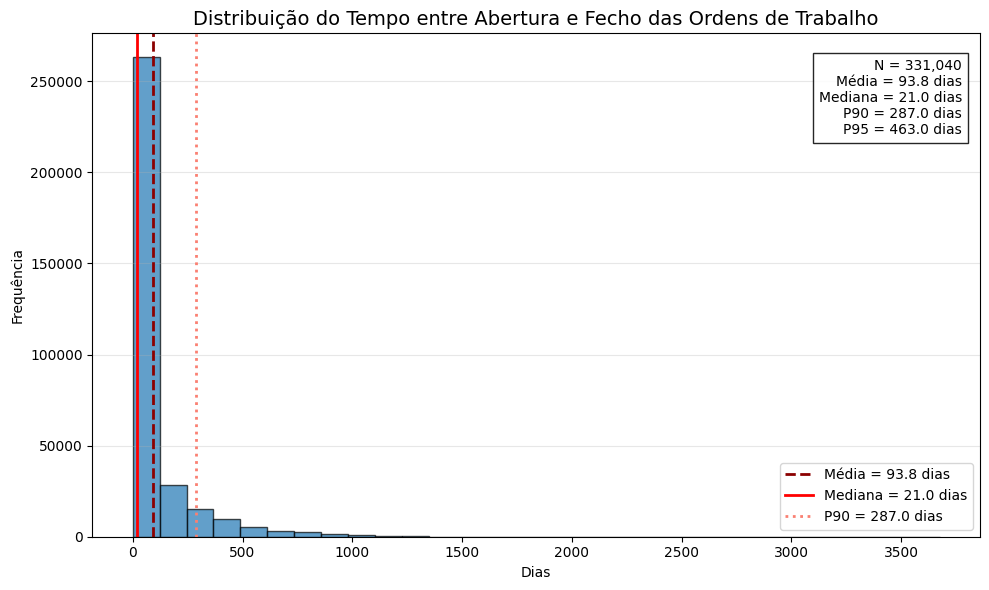

In [70]:
duration = (
    pd.to_datetime(df["DATETIME_CLOSED"]) -
    pd.to_datetime(df["DATETIME_OPEN"])
).dt.days

duration = duration.dropna()

# Estatísticas
mean_val = duration.mean()
median_val = duration.median()
p90 = duration.quantile(0.90)
p95 = duration.quantile(0.95)

plt.figure(figsize=(10, 6))

# Histograma
plt.hist(
    duration,
    bins=30,
    edgecolor="black",
    alpha=0.7
)

# Linhas de referência
plt.axvline(
    mean_val,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Média = {mean_val:.1f} dias"
)

plt.axvline(
    median_val,
    color="red",
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {median_val:.1f} dias"
)

plt.axvline(
    p90,
    color="salmon",
    linestyle=":",
    linewidth=2,
    label=f"P90 = {p90:.1f} dias"
)

# Caixa com estatísticas
stats_text = (
    f"N = {len(duration):,}\n"
    f"Média = {mean_val:.1f} dias\n"
    f"Mediana = {median_val:.1f} dias\n"
    f"P90 = {p90:.1f} dias\n"
    f"P95 = {p95:.1f} dias"
)

plt.text(
    0.98,
    0.95,
    stats_text,
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        alpha=0.85
    )
)

plt.title(
    "Distribuição do Tempo entre Abertura e Fecho das Ordens de Trabalho",
    fontsize=14
)

plt.xlabel("Dias")
plt.ylabel("Frequência")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()

plt.tight_layout()
plt.show()

In [71]:
date_cols = [
    "DATETIME_OUT_SERVICE",
    "DATETIME_OPEN",
    "DATETIME_FIRST_LABOR",
    "DATETIME_FINISHED",
    "DATETIME_CLOSED",
    "DATETIME_IN_SERVICE"
]

results = []

for i in range(len(date_cols) - 1):

    start_col = date_cols[i]
    end_col = date_cols[i + 1]

    diff_hours = (
        pd.to_datetime(df[end_col]) -
        pd.to_datetime(df[start_col])
    ).dt.total_seconds() / 3600

    results.append({
        "Etapa": f"{start_col} → {end_col}",
        "Média (h)": round(diff_hours.mean(), 2),
        "Mediana (h)": round(diff_hours.median(), 2),
        "P90 (h)": round(diff_hours.quantile(0.90), 2),
        "Máximo (h)": round(diff_hours.max(), 2)
    })

summary_df = pd.DataFrame(results)

summary_df

,Etapa,Média (h),Mediana (h),P90 (h),Máximo (h)
0,DATETIME_OUT_SERVICE → DATETIME_OPEN,10.05,0.00,0.00,89880.00
1,DATETIME_OPEN → DATETIME_FIRST_LABOR,44.54,0.00,72.00,28224.00
2,DATETIME_FIRST_LABOR → DATETIME_FINISHED,699.36,24.00,1440.00,88200.00
3,DATETIME_FINISHED → DATETIME_CLOSED,1507.79,96.00,4848.00,86304.00
4,DATETIME_CLOSED → DATETIME_IN_SERVICE,1.26,0.00,0.00,15888.00


## 4.8 Waranty

Verificação de valores omissos

In [72]:
df["WARRANTY"].isnull().sum()

np.int64(0)

Verificação de nulos

In [73]:
df["WARRANTY"].unique()

array(['YES', 'NO', 'UNKNOWN'], dtype=object)

Contagem de valores e conversão de UNNOWN para NO

In [74]:
df["WARRANTY"].value_counts()

,count
WARRANTY,
NO,277418
YES,53620
UNKNOWN,2


In [75]:
df["WARRANTY"] = (
    df["WARRANTY"]
    .replace("UNKNOWN", "NO")
)

In [76]:
master_df["WARRANTY"] = (
    master_df["WARRANTY"]
    .replace("UNKNOWN", "NO")
)

In [77]:
df["WARRANTY"] = (
    df["WARRANTY"]
    .map({
        "YES": 1,
        "NO": 0
    })
)

Representação gráficas de viaturas com garantia

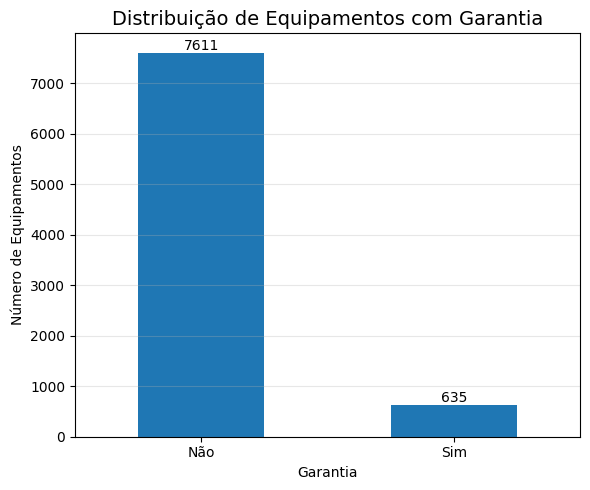

In [78]:
df_last = (
    df
    .sort_values("CREATE_DATE", ascending=False)
    .drop_duplicates(
        subset="EQ_EQUIP_NO",
        keep="first"
    )
)

warranty_labels = (
    df_last["WARRANTY"]
    .replace({
        0: "Não",
        1: "Sim"
    })
)

ax = warranty_labels.value_counts().plot(
    kind="bar",
    figsize=(6,5)
)

plt.title(
    "Distribuição de Equipamentos com Garantia",
    fontsize=14
)

plt.xlabel("Garantia")
plt.ylabel("Número de Equipamentos")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 4.9 REAS_REAS_FOR_REPAIR EREAS_FOR_REPAIR_DESC

Esta variável representa o motivo da intervenção

Verificação de nulos

In [79]:
df[[
    "REAS_REAS_FOR_REPAIR",
    "REAS_FOR_REPAIR_DESC"
]].isnull().sum()

,0
REAS_REAS_FOR_REPAIR,32177
REAS_FOR_REPAIR_DESC,32177


In [80]:
df[[ "REAS_REAS_FOR_REPAIR", "REAS_FOR_REPAIR_DESC" ]].drop_duplicates().head(25)


,REAS_REAS_FOR_REPAIR,REAS_FOR_REPAIR_DESC
2,N,NORMAL WEAR (TARGET)
50,R,ROAD CALL-TARGET
127,D,DAMAGE IN OPERATION (NON TARGE
153,A,ACCIDENT (NON TARGET)
210,F,ROAD CALL-NON TARGET
220,WOPS,WINTER OPS (NON TARGET)
267,Q,MANAGEMENT REQUEST-NON TARGET
272,O,USER CAUSED-NON TARGET
315,J,PIS-GENERAL (TARGET)
1118,W,WARRANTY (TARGET)


Criação do grupo UNKNOWN para os casos omissos

In [81]:
df["REAS_FOR_REPAIR_DESC"] = (
    df["REAS_FOR_REPAIR_DESC"]
    .fillna("UNKNOWN")
)

In [82]:
master_df["REAS_FOR_REPAIR_DESC"] = (
    master_df["REAS_FOR_REPAIR_DESC"]
    .fillna("UNKNOWN")
)

In [83]:
df["REAS_FOR_REPAIR_DESC"].value_counts()

,count
REAS_FOR_REPAIR_DESC,
NORMAL WEAR (TARGET),200182
DAMAGE IN OPERATION (NON TARGE,38480
UNKNOWN,32177
ROAD CALL-TARGET,13684
ROAD CALL-NON TARGET,10517
MANAGEMENT REQUEST-NON TARGET,10228
ACCIDENT (NON TARGET),8478
USER CAUSED-NON TARGET,4739
PIS-GENERAL (TARGET),3137


Criação do top 15 motivos para a reparação

In [84]:
# Obter top 14 categorias
top_14_reasons = (
    df["REAS_FOR_REPAIR_DESC"]
    .value_counts()
    .head(14)
    .index
)

# Substituir restantes categorias por OTHER
df["REAS_FOR_REPAIR_DESC"] = (
    df["REAS_FOR_REPAIR_DESC"]
    .apply(
        lambda x: x if x in top_14_reasons else "OTHER"
    )
)

In [85]:
df["REAS_FOR_REPAIR_DESC"].value_counts()

,count
REAS_FOR_REPAIR_DESC,
NORMAL WEAR (TARGET),200182
DAMAGE IN OPERATION (NON TARGE,38480
UNKNOWN,32177
ROAD CALL-TARGET,13684
ROAD CALL-NON TARGET,10517
MANAGEMENT REQUEST-NON TARGET,10228
ACCIDENT (NON TARGET),8478
USER CAUSED-NON TARGET,4739
PIS-GENERAL (TARGET),3137


## 4.10 PRI_PRIORITY_CODE




Nível de prioridade da reparação

Verificação de omissos

In [86]:
df["PRI_PRIORITY_CODE"].isnull().sum()

np.int64(0)

Escala de prioridade e respetiva contagem

In [87]:
df["PRI_PRIORITY_CODE"].unique()

array([3, 2, 1, 4])

In [88]:
df["PRI_PRIORITY_CODE"].value_counts().sort_index()

,count
PRI_PRIORITY_CODE,
1,2719
2,1768
3,325422
4,1131


Representação Gráfica

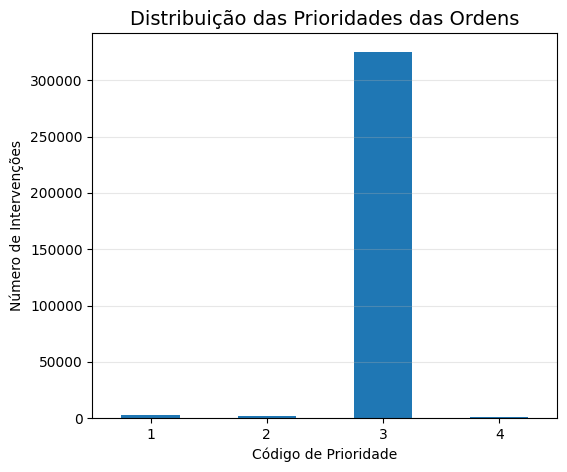

In [89]:
df["PRI_PRIORITY_CODE"] \
    .value_counts() \
    .sort_index() \
    .plot(
        kind="bar",
        figsize=(6,5)
)

plt.title(
    "Distribuição das Prioridades das Ordens",
    fontsize=14
)

plt.xlabel("Código de Prioridade")
plt.ylabel("Número de Intervenções")

plt.xticks(rotation=0)

plt.grid(axis="y", alpha=0.3)

plt.show()

## 4.11 REF_WORK_ORDER_NO



Esta variável define se existem ordens anteriores associadas

In [90]:
df["REF_WORK_ORDER_NO"] = (
    df["REF_WORK_ORDER_NO"]
    .replace("nan", np.nan)
)

df["HAS_REF_WORK_ORDER"] = (
    df["REF_WORK_ORDER_NO"]
    .notnull()
    .astype(int)
)

In [91]:
df["HAS_REF_WORK_ORDER"] = (
    df["REF_WORK_ORDER_NO"]
    .notnull()
    .astype(int)
)

Criou-se a variável HAS_REF_WORK_ORDER o objetivo é sinalizar

In [92]:
df["HAS_REF_WORK_ORDER"].value_counts()

,count
HAS_REF_WORK_ORDER,
0,330737
1,303


## 4.12 DEPT_EQUIP_DEPT E DEPT_EQUIP_DEPT_NAME


Estas variáveis identificam os departamentos que administram os equipamentos

In [93]:
df[[
    "DEPT_EQUIP_DEPT",
    "DEPT_EQUIP_DEPT_NAME"
]].drop_duplicates().head(30)

,DEPT_EQUIP_DEPT,DEPT_EQUIP_DEPT_NAME
2,0222,POLICE
3,0253,NEIGHBORHOOD OPERATIONS
4,0300,WATER WORKS
7,0271,FIRE DEPARTMENT RESPONSE
8,0252,TRAFFIC AND ROAD DIV
36,0400,M.S.D.
49,0225,POLICE INVESTIGATIONS BUREAU
61,0200,PARK DEPARTMENT
71,0190,RECREATION
99,0311,STORMWATER


Verificação de nulos

In [94]:
df[[
    "DEPT_EQUIP_DEPT",
    "DEPT_EQUIP_DEPT_NAME"
]].isnull().sum()

,0
DEPT_EQUIP_DEPT,0
DEPT_EQUIP_DEPT_NAME,0


Representação gráfica do top 10 departamentos com mais viaturas

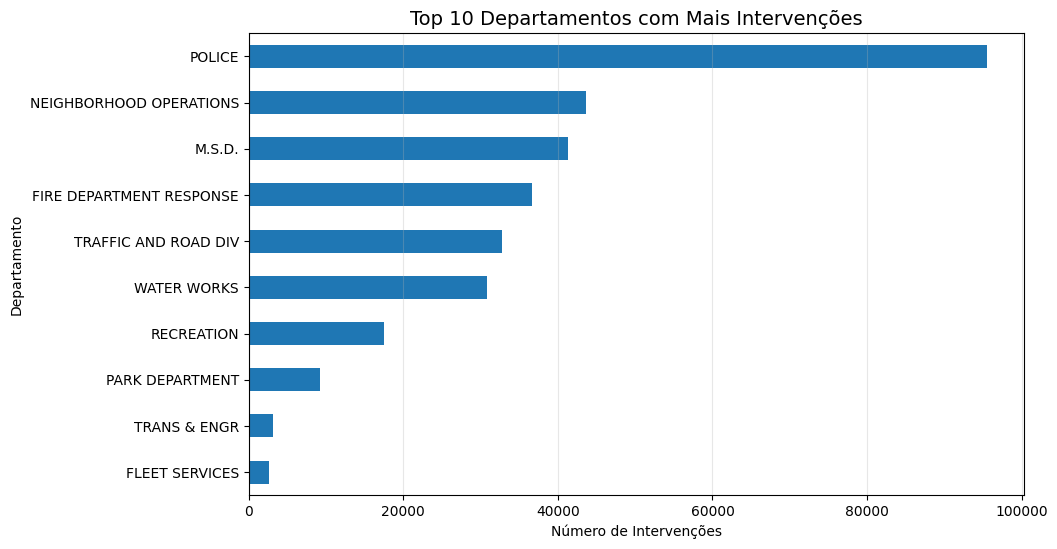

In [95]:
top_departments = (
    df["DEPT_EQUIP_DEPT_NAME"]
    .value_counts()
    .head(10)
    .sort_values()
)

top_departments.plot(
    kind="barh",
    figsize=(10,6)
)

plt.title(
    "Top 10 Departamentos com Mais Intervenções",
    fontsize=14
)

plt.xlabel("Número de Intervenções")
plt.ylabel("Departamento")

plt.grid(axis="x", alpha=0.3)

plt.show()

## 4.13 METER_1_LIFE_TOTAL

Esta variável indica a última leitura de contador após intervenção

Verificação de nulos

In [96]:
df["METER_1_LIFE_TOTAL"].isnull().sum()

np.int64(0)

Verificação da distribuição

In [97]:
df["METER_1_LIFE_TOTAL"].describe()

,METER_1_LIFE_TOTAL
count,331040.00
mean,54002.12
std,64368.09
min,0.00
25%,12356.75
50%,45735.50
75%,81960.00
max,5145382.00


Aplicação da mediana para os valores em falta

In [98]:
median_value = df.loc[
    df["METER_1_LIFE_TOTAL"] > 0,
    "METER_1_LIFE_TOTAL"
].median()

df["METER_1_LIFE_TOTAL"] = (
    df["METER_1_LIFE_TOTAL"]
    .replace(0, median_value)
)

Representação gráfica

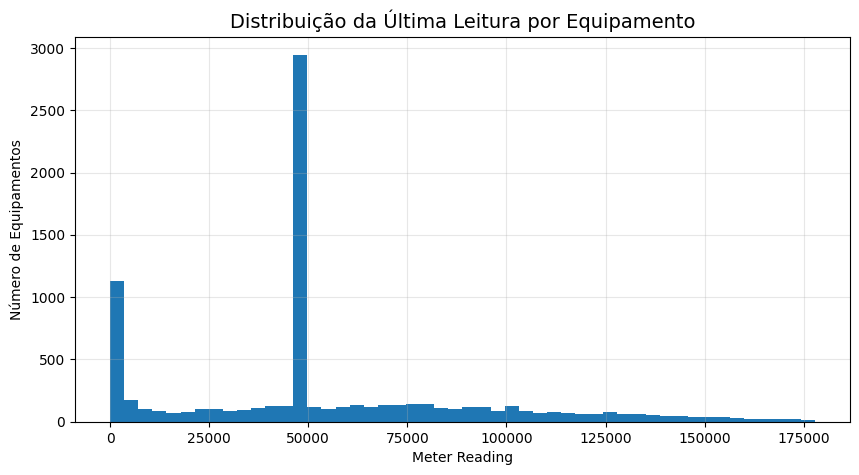

In [99]:
# =====================================================
# Última leitura por equipamento
# =====================================================

latest_meter = (
    df
    .sort_values("CREATE_DATE")
    .groupby("EQ_EQUIP_NO")
    .tail(1)
)

# =====================================================
# Histograma da última leitura
# =====================================================

limit = latest_meter["METER_1_LIFE_TOTAL"].quantile(0.99)

latest_meter[
    latest_meter["METER_1_LIFE_TOTAL"] <= limit
]["METER_1_LIFE_TOTAL"].hist(
    bins=50,
    figsize=(10,5)
)

plt.title(
    "Distribuição da Última Leitura por Equipamento",
    fontsize=14
)

plt.xlabel("Meter Reading")
plt.ylabel("Número de Equipamentos")

plt.grid(alpha=0.3)

plt.show()

Verificação da relação entre ambos os contadores

In [100]:
df[[
    "METER_1_READING",
    "METER_1_LIFE_TOTAL"
]].corr()

,METER_1_READING,METER_1_LIFE_TOTAL
METER_1_READING,1.00,0.72
METER_1_LIFE_TOTAL,0.72,1.00


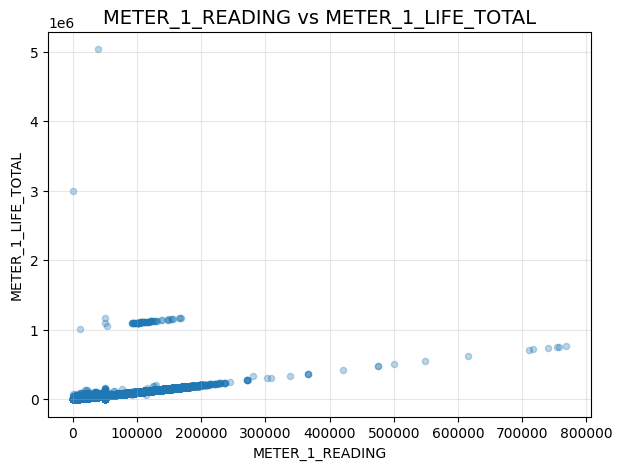

In [101]:
df.sample(50000).plot.scatter(
    x="METER_1_READING",
    y="METER_1_LIFE_TOTAL",
    figsize=(7,5),
    alpha=0.3
)

plt.title(
    "METER_1_READING vs METER_1_LIFE_TOTAL",
    fontsize=14
)

plt.grid(alpha=0.3)

plt.show()

## 4.14 EQ_PARENT_EQUIP_NO

Este código representa a tipologia mãe dos equipamentos

Verificação de nulos

In [102]:
df["EQ_PARENT_EQUIP_NO"].isnull().sum()

np.int64(0)

Verificação de valores únicos

In [103]:
df["EQ_PARENT_EQUIP_NO"].nunique()

7418

Contagens

In [104]:
df["EQ_PARENT_EQUIP_NO"].value_counts().head(20)

,count
EQ_PARENT_EQUIP_NO,
X0400,1235
X0222,759
X0252,676
S81556,494
61557,494
S71564,491
71565,491
DE71560,484
DE61553,482


Relação entre os identificadores de equipamento

In [105]:
(
    df["EQ_PARENT_EQUIP_NO"] ==
    df["EQ_EQUIP_NO"]
).mean()

np.float64(0.5676715804736587)

Criação da variável HAS_DIFERENT_PARENT quando o código de equipamento não é equivalente ao equipamento mãe

In [106]:
df["HAS_DIFFERENT_PARENT"] = (
    df["EQ_PARENT_EQUIP_NO"] !=
    df["EQ_EQUIP_NO"]
).astype(int)

In [107]:
parent_counts = (
    df.groupby("EQ_PARENT_EQUIP_NO")[
        "EQ_EQUIP_NO"
    ]
    .nunique()
)

df["N_EQUIP_PER_PARENT"] = (
    df["EQ_PARENT_EQUIP_NO"]
    .map(parent_counts)
)

Aplicação do mesmo dicionário criado para o código de equipamento

In [108]:
# Criar dicionário do mapeamento original
equip_map = (
    df[
        ["EQ_EQUIP_NO", "EQ_EQUIP_ID"]
    ]
    .drop_duplicates()
    .set_index("EQ_EQUIP_NO")["EQ_EQUIP_ID"]
    .to_dict()
)

# Aplicar ao parent equipment
df["EQ_PARENT_EQUIP_ID"] = (
    df["EQ_PARENT_EQUIP_NO"]
    .map(equip_map)
)

##4.15 DELAY_HOURS

Verificação da distribuição

In [109]:
df["DELAY_HOURS"].describe()

,DELAY_HOURS
count,331040.00
mean,18.82
std,244.55
min,0.00
25%,0.00
50%,0.00
75%,0.00
max,21383.52


Relação com a variável criada para as horas de atraso

In [110]:
df[[
    "DELAY_HOURS",
    "DELAY_TO_DUE_HOURS"
]].corr()

,DELAY_HOURS,DELAY_TO_DUE_HOURS
DELAY_HOURS,1.00,0.12
DELAY_TO_DUE_HOURS,0.12,1.00


verificação de nulos

In [111]:
df[
    "DELAY_HOURS"
].isnull().sum()

np.int64(0)

Criação da variável HAS_DELAY

In [112]:
df["HAS_DELAY"] = (
    df["DELAY_HOURS"] > 0
).astype(int)

##4.16 LABOR_HOURS

Distribuição da variável

In [113]:
df["LABOR_HOURS"].describe()

,LABOR_HOURS
count,331040.00
mean,3.39
std,10.37
min,-22.60
25%,0.70
50%,1.40
75%,3.00
max,1154.40


Fixação de valores negativo ao valor 0

In [114]:
df["LABOR_HOURS"] = (
    df["LABOR_HOURS"]
    .clip(lower=0)
)

Verificação de nulos

In [115]:
df["LABOR_HOURS"].isnull().sum()

np.int64(0)

Representação gráfica

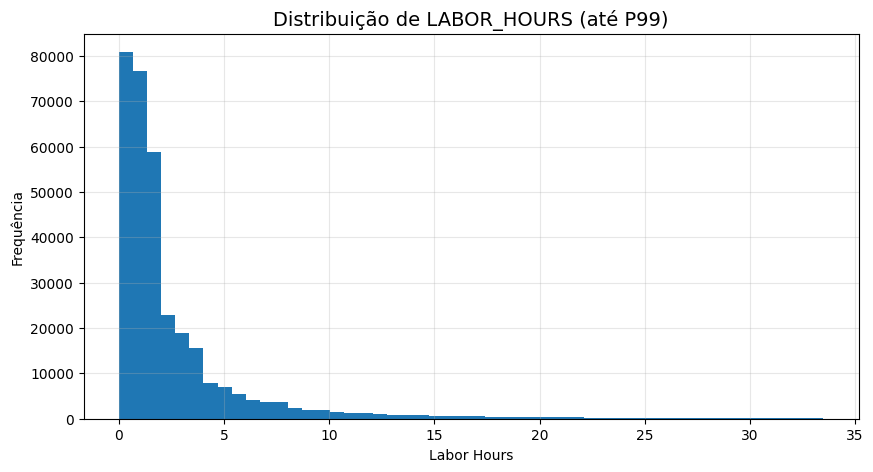

In [116]:
limit = df["LABOR_HOURS"].quantile(0.99)

df[
    df["LABOR_HOURS"] <= limit
]["LABOR_HOURS"].hist(
    bins=50,
    figsize=(10,5)
)

plt.title(
    "Distribuição de LABOR_HOURS (até P99)",
    fontsize=14
)

plt.xlabel("Labor Hours")
plt.ylabel("Frequência")

plt.grid(alpha=0.3)

plt.show()

##4.17 LABOR_COST

Verificação da distribuição

In [117]:
df["LABOR_COST"].describe()

,LABOR_COST
count,331040.00
mean,271.49
std,842.55
min,-2034.00
25%,50.40
50%,107.10
75%,233.10
max,81537.51


Verificação de nulos

In [118]:
df["LABOR_COST"].isnull().sum()

np.int64(0)

Verificaçãod e valores negativos, assumiu-se o pressuposto de que seriam acertos e serão mantidos

In [119]:
(df["LABOR_COST"] < 0).sum()

np.int64(37)

In [120]:
df[
    df["LABOR_COST"] < 0
][[
    "JOB_TYPE",
    "WORK_ORDER_STATUS",
    "LABOR_COST",
    "TOTAL_COST",
    "PARTS_COST",
    "LOC_WORK_ORDER_LOC_NAME"
]].head(20)

,JOB_TYPE,WORK_ORDER_STATUS,LABOR_COST,TOTAL_COST,PARTS_COST,LOC_WORK_ORDER_LOC_NAME
64613,REPAIR,CLOSED,-2034.00,-2034.00,0.00,LIGHT CAR SHOP
207139,REPAIR,CLOSED,-66.96,915.49,982.45,MSD-GALBRAITH
207166,REPAIR,CLOSED,-24.96,-24.96,0.00,MSD-GALBRAITH
209194,PM,CLOSED,-29.04,158.92,187.96,OTHER
209195,PM,CLOSED,-8.64,11.43,20.07,MSD-GALBRAITH
209244,PM,CLOSED,-5.00,-5.00,0.00,LIGHT CAR SHOP
217274,REPAIR,CLOSED,-17.64,-2.01,15.63,MSD-GALBRAITH
218198,REPAIR,CLOSED,-9.24,50.38,59.62,MSD-GALBRAITH
220603,PM,CLOSED,-19.55,-19.55,0.00,LIGHT CAR SHOP
220606,PM,CLOSED,-4.10,9.64,13.74,OTHER


Representação gráfica da relação entre custo e horas de trabalho

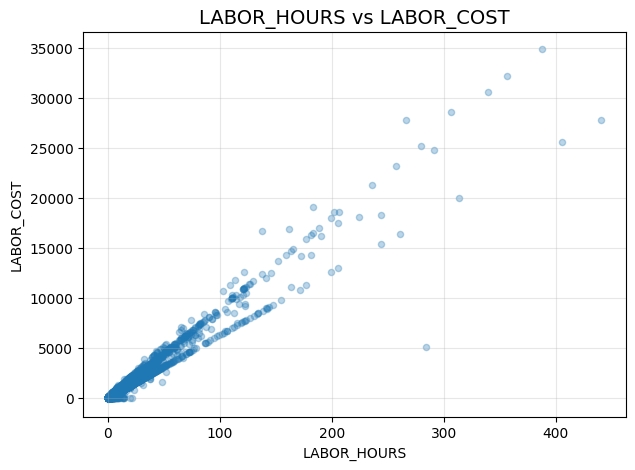

In [121]:
df.sample(50000).plot.scatter(
    x="LABOR_HOURS",
    y="LABOR_COST",
    figsize=(7,5),
    alpha=0.3
)

plt.title(
    "LABOR_HOURS vs LABOR_COST",
    fontsize=14
)

plt.grid(alpha=0.3)

plt.show()

Representação gráfica do custo das reparações

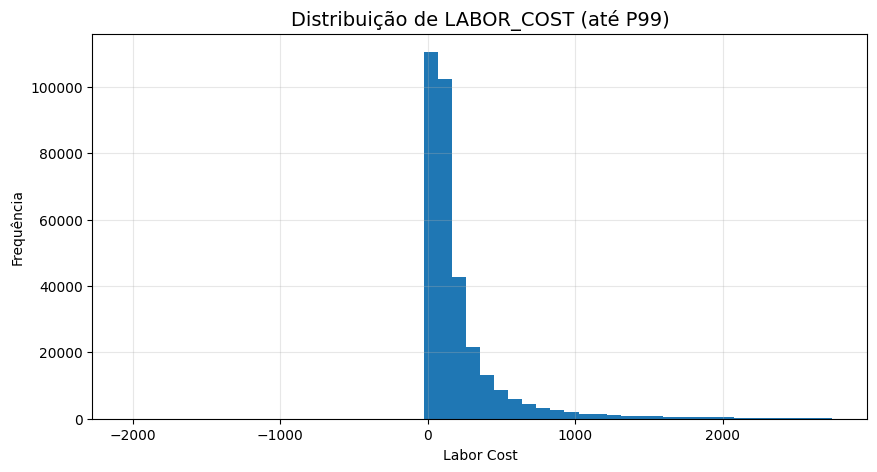

In [122]:
limit = df["LABOR_COST"].quantile(0.99)

df[
    df["LABOR_COST"] <= limit
]["LABOR_COST"].hist(
    bins=50,
    figsize=(10,5)
)

plt.title(
    "Distribuição de LABOR_COST (até P99)",
    fontsize=14
)

plt.xlabel("Labor Cost")
plt.ylabel("Frequência")

plt.grid(alpha=0.3)

plt.show()

##4.18 PARTS_COST

Verificação da Distribuição

In [123]:
df["PARTS_COST"].describe()

,PARTS_COST
count,331040.00
mean,280.31
std,1113.44
min,-6228.98
25%,2.44
50%,40.75
75%,185.62
max,82512.63


Verificação de nulos

In [124]:
df["PARTS_COST"].isnull().sum()

np.int64(0)

Verificação de valores negativos

In [125]:
(df["PARTS_COST"] < 0).sum()

np.int64(14)

Representação gráfica

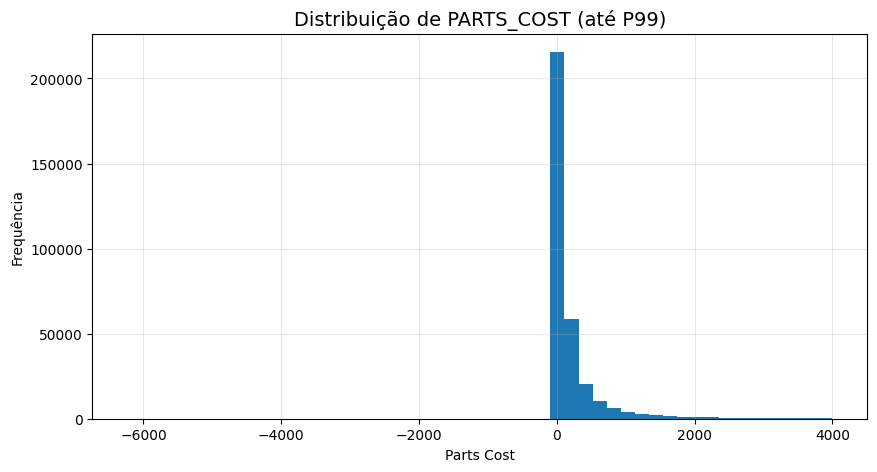

In [126]:
limit = df["PARTS_COST"].quantile(0.99)

df[
    df["PARTS_COST"] <= limit
]["PARTS_COST"].hist(
    bins=50,
    figsize=(10,5)
)

plt.title(
    "Distribuição de PARTS_COST (até P99)",
    fontsize=14
)

plt.xlabel("Parts Cost")
plt.ylabel("Frequência")

plt.grid(alpha=0.3)

plt.show()

Representação gráfica do custo de MOD e de Peças

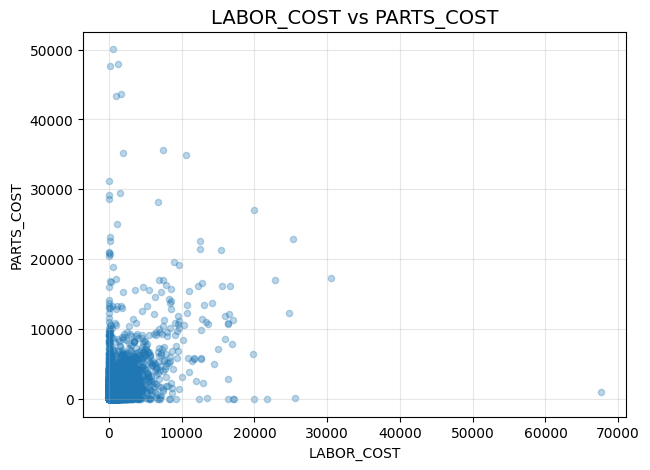

In [127]:
df.sample(50000).plot.scatter(
    x="LABOR_COST",
    y="PARTS_COST",
    figsize=(7,5),
    alpha=0.3
)

plt.title(
    "LABOR_COST vs PARTS_COST",
    fontsize=14
)

plt.grid(alpha=0.3)

plt.show()

##4.19 COMML_COST

Custo de externalização e serviços

Verificação da distribuição

In [128]:
df["COMML_COST"].describe()

,COMML_COST
count,331040.00
mean,8.59
std,426.94
min,-16342.29
25%,0.00
50%,0.00
75%,0.00
max,141728.75


Verificação de nulos

In [129]:
df["COMML_COST"].isnull().sum()

np.int64(0)

Verificação de valores negativos potenciais acertos (pressuposto)

In [130]:
(df["COMML_COST"] < 0).sum()

np.int64(2846)

In [131]:
df[
    df["COMML_COST"] < 0
][[
    "JOB_TYPE",
    "WORK_ORDER_STATUS",
    "COMML_COST",
    "TOTAL_COST",
    "LABOR_COST",
    "PARTS_COST"
]].head(20)

,JOB_TYPE,WORK_ORDER_STATUS,COMML_COST,TOTAL_COST,LABOR_COST,PARTS_COST
6168,REPAIR,CLOSED,-677.19,1681.08,894.40,1463.87
12736,REPAIR,CLOSED,-660.36,1228.61,748.80,1140.17
18304,REPAIR,CLOSED,-657.69,1401.09,852.80,1205.98
18875,REPAIR,CLOSED,-120.35,306.81,260.00,167.16
19202,REPAIR,CLOSED,-420.15,919.49,1139.00,200.64
19231,REPAIR,CLOSED,-662.64,2127.22,1215.00,1574.86
19342,REPAIR,CLOSED,-439.14,1121.85,1235.80,325.19
20328,REPAIR,CLOSED,-200.55,1074.38,1092.00,182.93
21199,REPAIR,CLOSED,-473.99,999.45,1278.00,195.44
21379,REPAIR,CLOSED,-205.70,737.63,650.80,292.53


verificação se os valores negativos resultaram da venda de equipamentos

In [132]:
# =====================================================
# EQUIPAMENTOS COM COMML_COST NEGATIVO
# =====================================================

neg_comml = df[
    df["COMML_COST"] < 0
].copy()

print(
    f"Total de registos com COMML_COST negativo: {len(neg_comml)}"
)

print(
    f"Total de equipamentos afetados: {neg_comml['EQ_EQUIP_NO'].nunique()}"
)

# =====================================================
# DATA DA INTERVENÇÃO COM COMML_COST NEGATIVO
# =====================================================

neg_comml = neg_comml[[
    "EQ_EQUIP_NO",
    "CREATE_DATE",
    "COMML_COST",
    "TOTAL_COST"
]].copy()

neg_comml = neg_comml.rename(
    columns={
        "CREATE_DATE": "NEGATIVE_DATE"
    }
)

# =====================================================
# ÚLTIMA INTERVENÇÃO DE CADA EQUIPAMENTO
# =====================================================

last_intervention = (

    df.sort_values("CREATE_DATE")

    .groupby("EQ_EQUIP_NO")

    .tail(1)

    [[
        "EQ_EQUIP_NO",
        "CREATE_DATE",
        "WORK_ORDER_STATUS"
    ]]

    .rename(
        columns={
            "CREATE_DATE": "LAST_DATE"
        }
    )

)

# =====================================================
# JUNTAR INFORMAÇÃO
# =====================================================

analysis = neg_comml.merge(

    last_intervention,

    on="EQ_EQUIP_NO",

    how="left"

)

# =====================================================
# EQUIPAMENTO VOLTOU A APARECER?
# =====================================================

analysis["RETURNED_AFTER_NEGATIVE"] = (

    analysis["LAST_DATE"] >
    analysis["NEGATIVE_DATE"]

)

# =====================================================
# RESUMO
# =====================================================

summary = (

    analysis["RETURNED_AFTER_NEGATIVE"]

    .value_counts()

    .rename(
        {
            True: "Voltou a ter intervenções",
            False: "Nunca mais apareceu"
        }
    )

)

print("\nResumo:")
print(summary)



Total de registos com COMML_COST negativo: 2846
Total de equipamentos afetados: 1203

Resumo:
RETURNED_AFTER_NEGATIVE
Voltou a ter intervenções    2827
Nunca mais apareceu            19
Name: count, dtype: int64


##4.20 TOTAL_COST

Verificação da distribuição

In [133]:
df["TOTAL_COST"].describe()

,TOTAL_COST
count,331040.00
mean,560.39
std,1731.79
min,-6748.44
25%,85.27
50%,182.06
75%,446.24
max,143137.01


Verificação de nulos

In [134]:
df["TOTAL_COST"].isnull().sum()

np.int64(0)

Verificação de valores negativos

In [135]:
(df["TOTAL_COST"] < 0).sum()

np.int64(48)

Verificação da consistência dos dados

In [136]:
# =====================================================
# Verificar se TOTAL_COST bate com a soma dos custos
# =====================================================

df["TARGET_CALCULATED_TOTAL"] = (
    df["LABOR_COST"] +
    df["PARTS_COST"] +
    df["COMML_COST"]
)

# =====================================================
# Diferença entre total real e calculado
# =====================================================

df["TOTAL_DIFF"] = (
    df["TOTAL_COST"] -
    df["TARGET_CALCULATED_TOTAL"]
)

# =====================================================
# Estatísticas da diferença
# =====================================================

df["TOTAL_DIFF"].describe()

,TOTAL_DIFF
count,331040.00
mean,0.00
std,0.00
min,-0.02
25%,0.00
50%,0.00
75%,0.00
max,0.02


In [137]:
df = df.drop(columns="TOTAL_DIFF")

/tmp/ipykernel_8913/630994799.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0,0].boxplot(


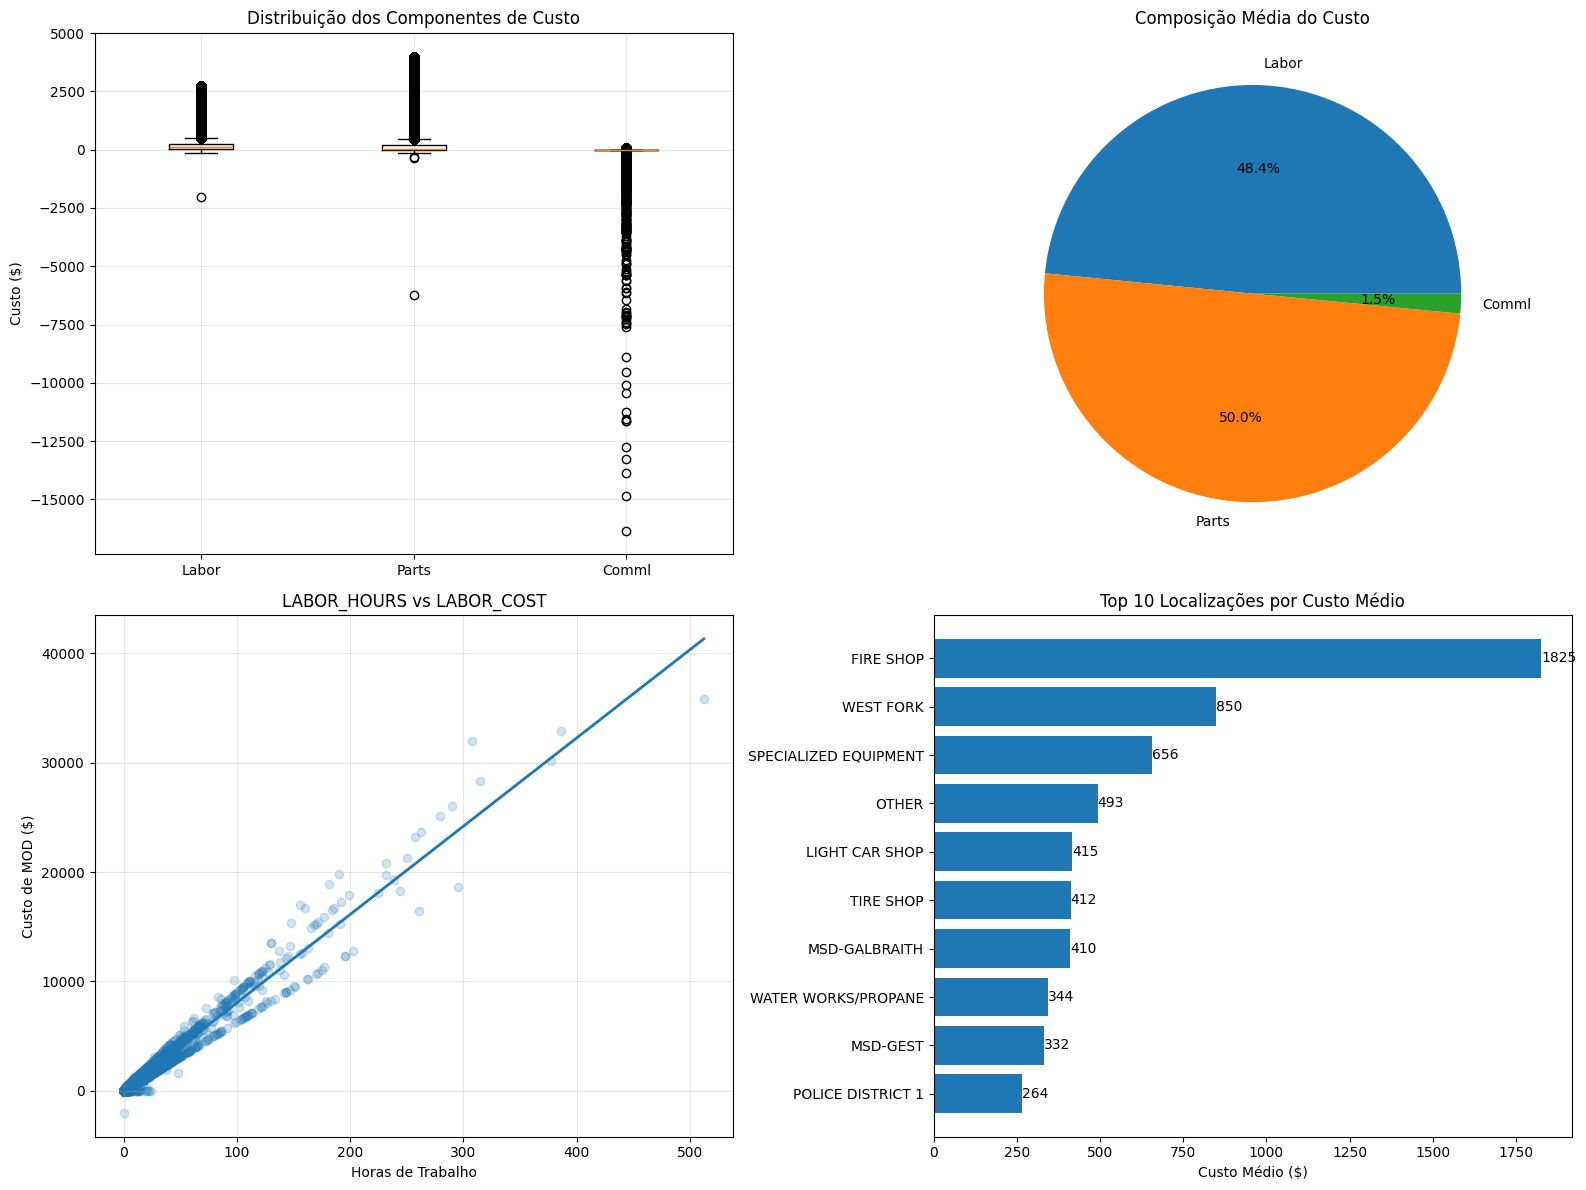

In [138]:
# =====================================================
# EDA - ANÁLISE DE CUSTOS
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# FIGURA COM 4 GRÁFICOS
# =====================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16,12)
)

# =====================================================
# 1. DISTRIBUIÇÃO DOS CUSTOS
# =====================================================

cost_cols = [
    "LABOR_COST",
    "PARTS_COST",
    "COMML_COST"
]

plot_df = df[cost_cols].copy()

for col in cost_cols:

    plot_df[col] = plot_df[col].clip(
        upper=df[col].quantile(0.99)
    )

axes[0,0].boxplot(
    [plot_df[c] for c in cost_cols],
    labels=[
        "Labor",
        "Parts",
        "Comml"
    ]
)

axes[0,0].set_title(
    "Distribuição dos Componentes de Custo"
)

axes[0,0].set_ylabel(
    "Custo ($)"
)

axes[0,0].grid(alpha=0.3)

# =====================================================
# 2. COMPOSIÇÃO MÉDIA DOS CUSTOS
# =====================================================

avg_costs = [

    df["LABOR_COST"].mean(),

    df["PARTS_COST"].mean(),

    df["COMML_COST"].mean()

]

axes[0,1].pie(

    avg_costs,

    labels=[
        "Labor",
        "Parts",
        "Comml"
    ],

    autopct="%1.1f%%"

)

axes[0,1].set_title(
    "Composição Média do Custo"
)

# =====================================================
# 3. LABOR HOURS VS LABOR COST
# =====================================================

sample = df.sample(
    min(50000, len(df)),
    random_state=42
)

axes[1,0].scatter(

    sample["LABOR_HOURS"],

    sample["LABOR_COST"],

    alpha=0.2

)

# Linha tendência

z = np.polyfit(

    sample["LABOR_HOURS"],

    sample["LABOR_COST"],

    1

)

p = np.poly1d(z)

x_sorted = np.sort(
    sample["LABOR_HOURS"]
)

axes[1,0].plot(

    x_sorted,

    p(x_sorted),

    linewidth=2

)

axes[1,0].set_title(
    "LABOR_HOURS vs LABOR_COST"
)

axes[1,0].set_xlabel(
    "Horas de Trabalho"
)

axes[1,0].set_ylabel(
    "Custo de MOD ($)"
)

axes[1,0].grid(alpha=0.3)

# =====================================================
# 4. TOP 10 LOCALIZAÇÕES MAIS CARAS
# =====================================================

top_locations = (

    df.groupby(
        "LOC_WORK_ORDER_LOC_NAME"
    )["TOTAL_COST"]

    .mean()

    .sort_values(
        ascending=True
    )

    .head(10)

)

axes[1,1].barh(

    top_locations.index,

    top_locations.values

)

axes[1,1].set_title(
    "Top 10 Localizações por Custo Médio"
)

axes[1,1].set_xlabel(
    "Custo Médio ($)"
)

for i, v in enumerate(
    top_locations.values
):

    axes[1,1].text(

        v,

        i,

        f"{v:.0f}",

        va="center"

    )

plt.tight_layout()

plt.show()

#5 Feature Engineering

In [139]:
print("Total de registos no df:", len(df))
print("Total de registos no master_df:", len(master_df))

Total de registos no df: 331040
Total de registos no master_df: 331040


Determinação dos intervalos de treino teste e exame final

In [140]:
print("TREINO (2008-2021):",
      df[
          df["WORK_ORDER_YR"].between(2008, 2021)
      ].shape[0])

print("TESTE (2022-2023):",
      df[
          df["WORK_ORDER_YR"].between(2022, 2023)
      ].shape[0])


TREINO (2008-2021): 302046
TESTE (2022-2023): 28958


Reordenação pós tratamento

In [141]:
df = df.sort_values([
    "EQ_EQUIP_NO",
    "CREATE_DATE"
])

Criação da variável downtime

In [142]:
df["TARGET_DOWNTIME_CALC"] = (
    df["DATETIME_IN_SERVICE"] -
    df["DATETIME_OUT_SERVICE"]
).dt.total_seconds() / 3600

In [143]:
df["TARGET_DOWNTIME_LOG"] = np.log1p(

    df["TARGET_DOWNTIME_CALC"]

)

Criação da variável TOTAL_INTERVENTIONS





In [144]:
df["TOTAL_INTERVENTIONS"] = (
    df.groupby("EQ_EQUIP_NO")
    .cumcount()
)


Criação da variável DAYS_SINCE_LAST_INTERVENTION

In [145]:
df["DAYS_SINCE_LAST_INTERVENTION"] = (
    df.groupby("EQ_EQUIP_NO")["CREATE_DATE"]
    .diff()
    .dt.days
)
df["DAYS_SINCE_LAST_INTERVENTION"] = (
    df["DAYS_SINCE_LAST_INTERVENTION"]
    .fillna(0)
)

Criação da Variável FAILURE_FREQUENCY

In [146]:
df["FAILURE_FREQUENCY"] = (
    df["TOTAL_INTERVENTIONS"] /
    (df["METER_1_LIFE_TOTAL"] + 1)
)

WAIT VS REPAIR

In [147]:
df["WAIT_REPAIR_RATIO"] = (
    df["WAIT_TIME_HOURS"] /
    (df["REPAIR_DURATION_HOURS"] + 1)
)

df["AVG_WAIT_REPAIR_RATIO"] = (
    df.groupby("EQ_EQUIP_NO")["WAIT_REPAIR_RATIO"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)
df["AVG_WAIT_REPAIR_RATIO"] = (
    df["AVG_WAIT_REPAIR_RATIO"]
    .fillna(0)
)

Repair to close ratio

In [148]:
df["REPAIR_TO_CLOSE_RATIO"] = (
    df["REPAIR_DURATION_HOURS"] /
    (df["CLOSE_DURATION_HOURS"] + 1)
)

df["AVG_REPAIR_TO_CLOSE_RATIO"] = (
    df.groupby("EQ_EQUIP_NO")["REPAIR_TO_CLOSE_RATIO"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)
df["AVG_REPAIR_TO_CLOSE_RATIO"] = (
    df["AVG_REPAIR_TO_CLOSE_RATIO"]
    .fillna(0)
)

WAIT_TO_CLOSE_RATIO

In [149]:
df["WAIT_TO_CLOSE_RATIO"] = (
    df["WAIT_TIME_HOURS"] /
    (df["CLOSE_DURATION_HOURS"] + 1)
)

df["AVG_WAIT_TO_CLOSE_RATIO"] = (
    df.groupby("EQ_EQUIP_NO")["WAIT_TO_CLOSE_RATIO"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)
df["AVG_WAIT_TO_CLOSE_RATIO"] = (
    df["AVG_WAIT_TO_CLOSE_RATIO"]
    .fillna(0)
)

DOWNTIME_PER_LABOR_HOUR

In [150]:
df["DOWNTIME_PER_LABOR_HOUR"] = (
    df["TARGET_DOWNTIME_CALC"] /
    (df["LABOR_HOURS"] + 1)
)

df["AVG_DOWNTIME_PER_LABOR_HOUR"] = (
    df.groupby("EQ_EQUIP_NO")["DOWNTIME_PER_LABOR_HOUR"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)
df["AVG_DOWNTIME_PER_LABOR_HOUR"] = (
    df["AVG_DOWNTIME_PER_LABOR_HOUR"]
    .fillna(0)
)

COST_PER_DOWNTIME_HOUR

In [151]:
df["COST_PER_DOWNTIME_HOUR"] = (
    df["TARGET_CALCULATED_TOTAL"] /
    (df["TARGET_DOWNTIME_CALC"] + 1)
)

df["AVG_COST_PER_DOWNTIME_HOUR"] = (
    df.groupby("EQ_EQUIP_NO")["COST_PER_DOWNTIME_HOUR"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)
df["AVG_COST_PER_DOWNTIME_HOUR"] = (
    df["AVG_COST_PER_DOWNTIME_HOUR"]
    .fillna(0)
)

LAST_DOWNTIME

In [152]:
df["LAST_DOWNTIME"] = (
    df.groupby("EQ_EQUIP_NO")["TARGET_DOWNTIME_CALC"]
    .shift(1)
)
df["LAST_DOWNTIME"] = (
    df["LAST_DOWNTIME"]
    .fillna(0)
)

AVG_LAST_3_DOWNTIME

In [153]:
df["AVG_LAST_3_DOWNTIME"] = (
    df.groupby("EQ_EQUIP_NO")["TARGET_DOWNTIME_CALC"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(3, min_periods=1)
        .mean()
    )
)
df["AVG_LAST_3_DOWNTIME"] = (
    df["AVG_LAST_3_DOWNTIME"]
    .fillna(0)
)

DOWNTIME_TREND

In [154]:
df["DOWNTIME_TREND"] = (
    df["LAST_DOWNTIME"] -
    df["AVG_LAST_3_DOWNTIME"]
)

LABOR INTENSITY

In [155]:
df["LABOR_INTENSITY"] = (
    df["LABOR_HOURS"] /
    (df["REPAIR_DURATION_HOURS"] + 1)
)

df["AVG_LABOR_INTENSITY"] = (
    df.groupby("EQ_EQUIP_NO")["LABOR_INTENSITY"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(5, min_periods=1)
        .mean()
    )
)
df["AVG_LABOR_INTENSITY"] = (
    df["AVG_LABOR_INTENSITY"]
    .fillna(0)
)

Criação da variável AVG_DOWNTIME_EQUIP

In [156]:
df["AVG_DOWNTIME_EQUIP"] = (
    df.groupby("EQ_EQUIP_NO")["TARGET_DOWNTIME_CALC"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

Criação da variável AVG_COST_EQUIP

In [157]:
df["AVG_COST_EQUIP"] = (
    df.groupby("EQ_EQUIP_NO")["TOTAL_COST"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

Criação da variável TOTAL_COST_EQUIP

In [158]:
df["TOTAL_COST_EQUIP"] = (
    df.groupby("EQ_EQUIP_NO")["TOTAL_COST"]
    .transform(
        lambda x: x.shift(1).cumsum()
    )
)

Criação da variável REPAIR_COUNT

In [159]:
df["REPAIR_COUNT"] = (
    (df["JOB_TYPE"] == "REPAIR")
    .groupby(df["EQ_EQUIP_NO"])
    .cumsum()
    - (df["JOB_TYPE"] == "REPAIR").astype(int)
)

Criação da variável PM_COUNT

In [160]:
df["PM_COUNT"] = (
    (df["JOB_TYPE"] == "PM")
    .groupby(df["EQ_EQUIP_NO"])
    .cumsum()
    - (df["JOB_TYPE"] == "PM").astype(int)
)

Criação das variáveis "REPAIRS_LAST_12M","PM_LAST_12M"

In [161]:
df["REPAIRS_LAST_12M"] = 0
df["PM_LAST_12M"] = 0

for equip, group in df.groupby("EQ_EQUIP_NO"):

    group = group.sort_values("CREATE_DATE")

    dates = group["CREATE_DATE"]

    repair_dates = group.loc[
        group["JOB_TYPE"] == "REPAIR",
        "CREATE_DATE"
    ]

    pm_dates = group.loc[
        group["JOB_TYPE"] == "PM",
        "CREATE_DATE"
    ]

    repairs_12 = []
    pm_12 = []

    for current_date in dates:

        repairs_12.append(
            ((repair_dates < current_date) &
             (repair_dates >= current_date - pd.DateOffset(months=12))).sum()
        )

        pm_12.append(
            ((pm_dates < current_date) &
             (pm_dates >= current_date - pd.DateOffset(months=12))).sum()
        )

    df.loc[group.index, "REPAIRS_LAST_12M"] = repairs_12
    df.loc[group.index, "PM_LAST_12M"] = pm_12

Criação da variável EQUIP_AGE_DAYS

In [162]:
first_seen = (

    df.groupby("EQ_EQUIP_NO")["CREATE_DATE"]

    .transform("min")

)

df["EQUIP_AGE_DAYS"] = (

    df["CREATE_DATE"] -

    first_seen

).dt.days

Criação da variável TARGET_REPAIR_30D

In [163]:
df["TARGET_REPAIR_30D"] = np.nan

for equip, group in df.groupby("EQ_EQUIP_NO"):

    group = group.sort_values("CREATE_DATE")

    repair_dates = group.loc[
        group["JOB_TYPE"] == "REPAIR",
        "CREATE_DATE"
    ]

    target = []

    for current_date in group["CREATE_DATE"]:

        has_repair = (
            (
                (repair_dates > current_date) &
                (
                    repair_dates <=
                    current_date + pd.Timedelta(days=30)
                )
            ).any()
        )

        target.append(
            int(has_repair)
        )

    df.loc[group.index, "TARGET_REPAIR_30D"] = target

Algumas visualizações que incorporam as features criadas

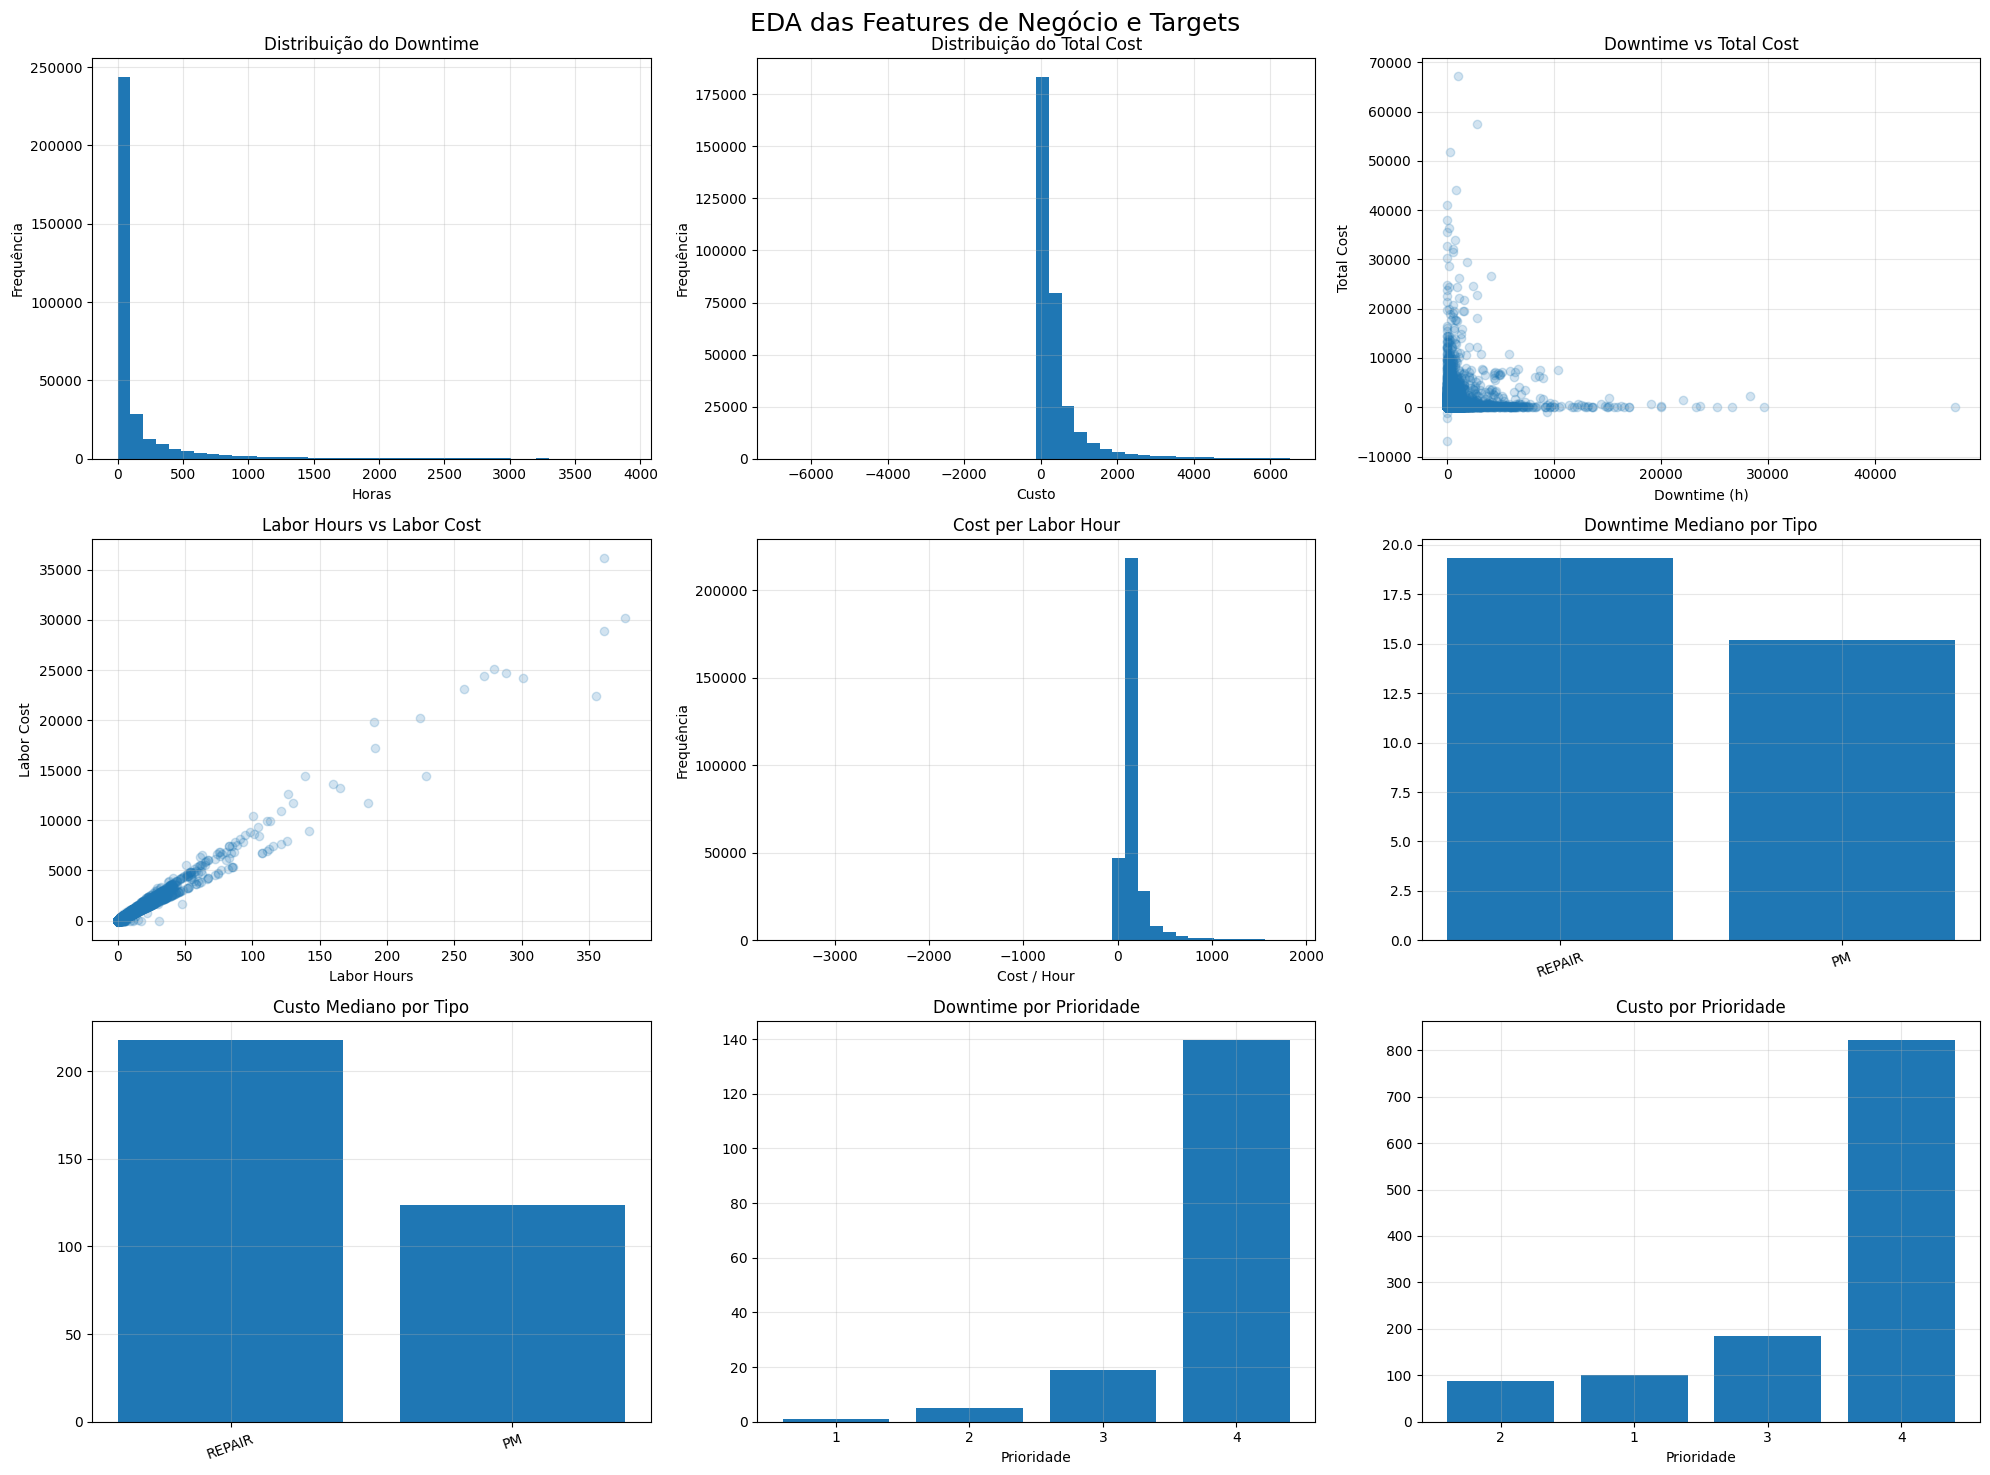

In [164]:
# =====================================================
# FEATURE ADICIONAL
# =====================================================

df["COST_PER_HOUR"] = (

    df["TOTAL_COST"] /

    df["LABOR_HOURS"]

)

df["COST_PER_HOUR"] = df[
    "COST_PER_HOUR"
].replace(
    [np.inf, -np.inf],
    np.nan
)

# =====================================================
# SAMPLE PARA SCATTERS
# =====================================================

sample = df.sample(
    min(20000, len(df)),
    random_state=42
)

# =====================================================
# FIGURA
# =====================================================

fig, axes = plt.subplots(
    3,
    3,
    figsize=(20,15)
)

# =====================================================
# 1. DISTRIBUIÇÃO DOWNTIME
# =====================================================

downtime = df["DOWNTIME_HRS_USER"]

downtime[
    downtime <= downtime.quantile(0.99)
].hist(
    bins=40,
    ax=axes[0,0]
)

axes[0,0].set_title(
    "Distribuição do Downtime"
)

axes[0,0].set_xlabel("Horas")
axes[0,0].set_ylabel("Frequência")

# =====================================================
# 2. DISTRIBUIÇÃO TOTAL COST
# =====================================================

cost = df["TOTAL_COST"]

cost[
    cost <= cost.quantile(0.99)
].hist(
    bins=40,
    ax=axes[0,1]
)

axes[0,1].set_title(
    "Distribuição do Total Cost"
)

axes[0,1].set_xlabel("Custo")
axes[0,1].set_ylabel("Frequência")

# =====================================================
# 3. DOWNTIME VS COST
# =====================================================

axes[0,2].scatter(
    sample["DOWNTIME_HRS_USER"],
    sample["TOTAL_COST"],
    alpha=0.2
)

axes[0,2].set_title(
    "Downtime vs Total Cost"
)

axes[0,2].set_xlabel("Downtime (h)")
axes[0,2].set_ylabel("Total Cost")

# =====================================================
# 4. LABOR HOURS VS LABOR COST
# =====================================================

axes[1,0].scatter(
    sample["LABOR_HOURS"],
    sample["LABOR_COST"],
    alpha=0.2
)

axes[1,0].set_title(
    "Labor Hours vs Labor Cost"
)

axes[1,0].set_xlabel("Labor Hours")
axes[1,0].set_ylabel("Labor Cost")

# =====================================================
# 5. COST PER HOUR
# =====================================================

cost_hour = df["COST_PER_HOUR"].dropna()

cost_hour[
    cost_hour <= cost_hour.quantile(0.99)
].hist(
    bins=40,
    ax=axes[1,1]
)

axes[1,1].set_title(
    "Cost per Labor Hour"
)

axes[1,1].set_xlabel("Cost / Hour")
axes[1,1].set_ylabel("Frequência")

# =====================================================
# 6. DOWNTIME POR JOB TYPE
# =====================================================

job_dt = (

    df.groupby("JOB_TYPE")
    ["DOWNTIME_HRS_USER"]

    .median()

    .sort_values(
        ascending=False
    )

)

axes[1,2].bar(
    job_dt.index,
    job_dt.values
)

axes[1,2].set_title(
    "Downtime Mediano por Tipo"
)

axes[1,2].tick_params(
    axis="x",
    rotation=20
)

# =====================================================
# 7. COST POR JOB TYPE
# =====================================================

job_cost = (

    df.groupby("JOB_TYPE")
    ["TOTAL_COST"]

    .median()

    .sort_values(
        ascending=False
    )

)

axes[2,0].bar(
    job_cost.index,
    job_cost.values
)

axes[2,0].set_title(
    "Custo Mediano por Tipo"
)

axes[2,0].tick_params(
    axis="x",
    rotation=20
)

# =====================================================
# 8. PRIORIDADE VS DOWNTIME
# =====================================================

priority_dt = (

    df.groupby(
        "PRI_PRIORITY_CODE"
    )["DOWNTIME_HRS_USER"]

    .median()

    .sort_values()

)

axes[2,1].bar(
    priority_dt.index.astype(str),
    priority_dt.values
)

axes[2,1].set_title(
    "Downtime por Prioridade"
)

axes[2,1].set_xlabel(
    "Prioridade"
)

# =====================================================
# 9. PRIORIDADE VS COST
# =====================================================

priority_cost = (

    df.groupby(
        "PRI_PRIORITY_CODE"
    )["TOTAL_COST"]

    .median()

    .sort_values()

)

axes[2,2].bar(
    priority_cost.index.astype(str),
    priority_cost.values
)

axes[2,2].set_title(
    "Custo por Prioridade"
)

axes[2,2].set_xlabel(
    "Prioridade"
)

# =====================================================
# LAYOUT
# =====================================================

for ax in axes.flat:
    ax.grid(alpha=0.3)

plt.suptitle(
    "EDA das Features de Negócio e Targets",
    fontsize=18
)

plt.tight_layout()

plt.show()

In [165]:
print("Colunas do df:\n")
print(df.columns.tolist())

print("\n" + "="*80 + "\n")

print("Colunas do master_df:\n")
print(master_df.columns.tolist())

Colunas do df:

['UNIQUE_WORK_ORDER_NO', 'CREATE_DATE', 'LOC_WORK_ORDER_LOC', 'LOC_WORK_ORDER_LOC_NAME', 'WORK_ORDER_YR', 'WORK_ORDER_NO', 'JOB_TYPE', 'EQ_EQUIP_NO', 'WORK_ORDER_STATUS', 'METER_1_READING', 'DATETIME_OUT_SERVICE', 'DATETIME_IN_SERVICE', 'DATETIME_OPEN', 'DATETIME_FIRST_LABOR', 'DATETIME_FINISHED', 'DATETIME_CLOSED', 'DATETIME_UNIT_IN', 'DATETIME_DUE', 'DATETIME_PM_SCHED', 'QTY_EST_HOURS', 'DOWNTIME_HRS_USER', 'DOWNTIME_HRS_SHOP', 'WARRANTY', 'REAS_REAS_FOR_REPAIR', 'REAS_FOR_REPAIR_DESC', 'PRI_PRIORITY_CODE', 'REF_WORK_ORDER_NO', 'DEPT_EQUIP_DEPT', 'DEPT_EQUIP_DEPT_NAME', 'METER_1_LIFE_TOTAL', 'EQ_PARENT_EQUIP_NO', 'DELAY_HOURS', 'LABOR_HOURS', 'LABOR_COST', 'PARTS_COST', 'COMML_COST', 'TOTAL_COST', 'CREATE_MONTH', 'CREATE_DAYOFWEEK', 'EQ_EQUIP_ID', 'HAS_METER_READING', 'WAIT_TIME_HOURS', 'REPAIR_DURATION_HOURS', 'CLOSE_DURATION_HOURS', 'DELAY_TO_DUE_HOURS', 'HAS_PM_SCHEDULE', 'HAS_REF_WORK_ORDER', 'HAS_DIFFERENT_PARENT', 'N_EQUIP_PER_PARENT', 'EQ_PARENT_EQUIP_ID', 'HAS

In [166]:
cols_to_add = [
    "UNIQUE_WORK_ORDER_NO",
    "REPAIR_DURATION_HOURS",
    "DELAY_TO_DUE_HOURS",
    "TOTAL_INTERVENTIONS",
    "DAYS_SINCE_LAST_INTERVENTION",
    "FAILURE_FREQUENCY",
    "LABOR_INTENSITY",
    "AVG_DOWNTIME_EQUIP",
    "AVG_COST_EQUIP",
    "TOTAL_COST_EQUIP",
    "REPAIR_COUNT",
    "PM_COUNT",
    "REPAIRS_LAST_12M",
    "PM_LAST_12M"
]

master_df = master_df.merge(
    df[cols_to_add],
    on="UNIQUE_WORK_ORDER_NO",
    how="left"
)

##5.1 Ajustes Finais

In [167]:
df.head()

,UNIQUE_WORK_ORDER_NO,CREATE_DATE,LOC_WORK_ORDER_LOC,LOC_WORK_ORDER_LOC_NAME,WORK_ORDER_YR,WORK_ORDER_NO,JOB_TYPE,EQ_EQUIP_NO,WORK_ORDER_STATUS,METER_1_READING,DATETIME_OUT_SERVICE,DATETIME_IN_SERVICE,DATETIME_OPEN,DATETIME_FIRST_LABOR,DATETIME_FINISHED,DATETIME_CLOSED,DATETIME_UNIT_IN,DATETIME_DUE,DATETIME_PM_SCHED,QTY_EST_HOURS,DOWNTIME_HRS_USER,DOWNTIME_HRS_SHOP,WARRANTY,REAS_REAS_FOR_REPAIR,REAS_FOR_REPAIR_DESC,PRI_PRIORITY_CODE,REF_WORK_ORDER_NO,DEPT_EQUIP_DEPT,DEPT_EQUIP_DEPT_NAME,METER_1_LIFE_TOTAL,EQ_PARENT_EQUIP_NO,DELAY_HOURS,LABOR_HOURS,LABOR_COST,PARTS_COST,COMML_COST,TOTAL_COST,CREATE_MONTH,CREATE_DAYOFWEEK,EQ_EQUIP_ID,HAS_METER_READING,WAIT_TIME_HOURS,REPAIR_DURATION_HOURS,CLOSE_DURATION_HOURS,DELAY_TO_DUE_HOURS,HAS_PM_SCHEDULE,HAS_REF_WORK_ORDER,HAS_DIFFERENT_PARENT,N_EQUIP_PER_PARENT,EQ_PARENT_EQUIP_ID,HAS_DELAY,TARGET_CALCULATED_TOTAL,TARGET_DOWNTIME_CALC,TARGET_DOWNTIME_LOG,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,WAIT_REPAIR_RATIO,AVG_WAIT_REPAIR_RATIO,REPAIR_TO_CLOSE_RATIO,AVG_REPAIR_TO_CLOSE_RATIO,WAIT_TO_CLOSE_RATIO,AVG_WAIT_TO_CLOSE_RATIO,DOWNTIME_PER_LABOR_HOUR,AVG_DOWNTIME_PER_LABOR_HOUR,COST_PER_DOWNTIME_HOUR,AVG_COST_PER_DOWNTIME_HOUR,LAST_DOWNTIME,AVG_LAST_3_DOWNTIME,DOWNTIME_TREND,LABOR_INTENSITY,AVG_LABOR_INTENSITY,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,EQUIP_AGE_DAYS,TARGET_REPAIR_30D,COST_PER_HOUR
277698,2010-4146-62,2010-04-30,4146,OTHER,2010,62,REPAIR,00175,CLOSED,75,2010-04-30,2010-07-26,2010-04-30,2010-04-30,2010-05-19,2010-07-26,2010-04-30,2010-05-03,NaT,0.00,118.65,118.65,0,J,PIS-GENERAL (TARGET),3,NaN,0400,M.S.D.,75,00175,0.00,2.50,157.50,57.98,0.00,215.48,4,4,0,1,0.00,456.00,2088.00,384.00,0,0,0,1,0.00,0,215.48,2088.00,7.64,0,0.00,0.00,0.00,0.00,0.22,0.00,0.00,0.00,596.57,0.00,0.10,0.00,0.00,0.00,0.00,0.01,0.00,NaN,NaN,NaN,0,0,0,0,0,1.00,86.19
279430,2010-3901-551,2010-05-20,3901,MSD-GEST,2010,551,REPAIR,00175,CLOSED,88,2010-05-20,2010-05-22,2010-05-20,2010-05-20,2010-05-22,2010-05-22,2010-05-20,2010-05-23,NaT,0.00,12.95,12.95,1,N,NORMAL WEAR (TARGET),3,NaN,0400,M.S.D.,88,00175,0.00,0.50,31.50,38.64,0.00,70.14,5,3,0,1,0.00,48.00,48.00,-24.00,0,0,0,1,0.00,0,70.14,48.00,3.89,1,20.00,0.01,0.00,0.00,0.98,0.22,0.00,0.00,32.00,596.57,1.43,0.10,2088.00,2088.00,0.00,0.01,0.01,2088.00,215.48,215.48,1,0,1,0,20,0.00,140.28
263178,2010-3901-1251,2010-12-01,3901,MSD-GEST,2010,1251,PM,00175,CLOSED,1670,2010-12-01,2011-09-29,2010-12-01,2010-12-01,2011-09-29,2011-09-29,2010-12-01,2010-12-04,2010-11-20,0.00,1387.23,5.76,0,NaN,UNKNOWN,3,NaN,0400,M.S.D.,1670,00175,0.00,0.50,31.50,16.50,0.00,48.00,12,2,0,1,0.00,7248.00,7248.00,7176.00,1,0,0,1,0.00,0,48.00,7248.00,8.89,2,195.00,0.00,0.00,0.00,1.00,0.60,0.00,0.00,4832.00,314.29,0.01,0.77,48.00,1068.00,-1020.00,0.00,0.01,1068.00,142.81,285.62,2,0,2,0,215,0.00,96.00
241811,2011-3902-821,2011-07-06,3902,MSD-GALBRAITH,2011,821,PM,00175,CLOSED,2182,2011-07-06,2011-09-16,2011-07-06,2011-07-06,2011-07-08,2011-09-16,2011-07-06,2011-07-09,2011-06-01,0.00,444.90,18.98,0,NaN,UNKNOWN,3,NaN,0400,M.S.D.,2182,00175,0.00,0.50,31.50,14.97,0.00,46.47,7,2,0,1,0.00,48.00,1728.00,-24.00,1,0,0,1,0.00,0,46.47,1728.00,7.46,3,217.00,0.00,0.00,0.00,0.03,0.73,0.00,0.00,1152.00,1820.19,0.03,0.51,7248.00,3128.00,4120.00,0.01,0.01,3128.00,111.21,333.62,2,1,0,1,432,0.00,92.94
223758,2012-3902-383,2012-02-08,3902,MSD-GALBRAITH,2012,383,PM,00175,CLOSED,6121,2012-02-08,2012-02-21,2012-02-08,2012-02-08,2012-02-08,2012-02-21,2012-02-08,2012-02-11,2012-01-06,1.40,4.45,4.45,0,NaN,UNKNOWN,3,NaN,0400,M.S.D.,6121,00175,0.00,1.87,117.81,26.74,0.00,144.55,2,2,0,1,0.00,0.00,312.00,-72.00,1,0,0,1,0.00,0,144.55,312.00,5.75,4,217.00,0.00,0.00,0.00,0.00,0.56,0.00,0.00,108.71,1653.14,0.46,0.39,1728.00,3008.00,-1280.00,1.87,0.01,2778.00,95.02,380.09,2,2,0,1,649,0.00,77.30


reordenar os dataset DF

In [168]:
df = df.sort_index()

In [169]:
master_df.head(5)

,UNIQUE_WORK_ORDER_NO,CREATE_DATE,LOC_WORK_ORDER_LOC,LOC_WORK_ORDER_LOC_NAME,WORK_ORDER_YR,WORK_ORDER_NO,JOB_TYPE,EQ_EQUIP_NO,WORK_ORDER_STATUS,METER_1_READING,DATETIME_OUT_SERVICE,DATETIME_IN_SERVICE,DATETIME_OPEN,DATETIME_FIRST_LABOR,DATETIME_FINISHED,DATETIME_CLOSED,DATETIME_UNIT_IN,DATETIME_DUE,DATETIME_PM_SCHED,QTY_EST_HOURS,DOWNTIME_HRS_USER,DOWNTIME_HRS_SHOP,WARRANTY,REAS_REAS_FOR_REPAIR,REAS_FOR_REPAIR_DESC,PRI_PRIORITY_CODE,REF_WORK_ORDER_NO,DEPT_EQUIP_DEPT,DEPT_EQUIP_DEPT_NAME,METER_1_LIFE_TOTAL,EQ_PARENT_EQUIP_NO,DELAY_HOURS,LABOR_HOURS,LABOR_COST,PARTS_COST,COMML_COST,TOTAL_COST,WAIT_TIME_HOURS,CLOSE_DURATION_HOURS,REPAIR_DURATION_HOURS,DELAY_TO_DUE_HOURS,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,LABOR_INTENSITY,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M
0,2023-2205-312,2023-08-07,2205,POLICE DISTRICT 5,2023,312,REPAIR,21306,WORK FINISHED,15942,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.05,0.05,YES,N,NORMAL WEAR (TARGET),3,NaN,0222,POLICE,15942,21306,0.00,1.00,110.00,0.00,0.00,110.00,0.00,0.00,0.00,-72.00,9,138.00,0.00,1.00,1320.00,920.61,8285.48,7,2,3,1
1,2023-4131-718,2023-08-07,4131,TIRE SHOP,2023,718,REPAIR,92830,CLOSED,398,2023-08-07,2023-08-08,2023-08-07,2023-08-07,2023-08-08,2023-08-08,2023-08-07,2023-08-10,NaT,0.00,23.18,23.18,NO,N,NORMAL WEAR (TARGET),3,NaN,0253,NEIGHBORHOOD OPERATIONS,398,92830,0.00,2.00,220.00,200.48,4.00,424.48,0.00,24.00,24.00,-48.00,61,6.00,0.15,0.08,529.57,306.52,18697.71,57,4,21,0
2,2023-3001-1389,2023-08-07,3001,WATER WORKS/PROPANE,2023,1389,REPAIR,10797,WORK FINISHED,41248,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.03,0.03,NO,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,41248,10797,0.00,0.75,82.50,5.97,0.00,88.47,0.00,0.00,0.00,-72.00,40,25.00,0.00,0.75,622.20,493.42,19736.69,30,10,17,6
3,2023-3001-1388,2023-08-07,3001,WATER WORKS/PROPANE,2023,1388,REPAIR,80800,WORK FINISHED,97671,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.02,0.02,NO,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,97671,80800,0.00,0.50,55.00,0.00,0.00,55.00,0.00,0.00,0.00,-72.00,64,19.00,0.00,0.50,797.25,494.39,31640.81,49,15,16,3
4,2023-3001-1386,2023-08-07,3001,WATER WORKS/PROPANE,2023,1386,REPAIR,11920,WORK FINISHED,10598,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.02,0.02,YES,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,10598,11920,0.00,1.00,110.00,0.00,0.00,110.00,0.00,0.00,0.00,-72.00,22,10.00,0.00,1.00,801.82,426.41,9381.05,17,5,11,2


Após a conclusão das etapas de limpeza, transformação e engenharia de atributos, foi definida a estrutura final do dataset utilizado na modelação. Foram selecionadas variáveis relacionadas com as características dos equipamentos, informação operacional, histórico de intervenções, métricas agregadas de custo e downtime, indicadores temporais e atributos derivados através de feature engineering.

Durante este processo foram também removidas variáveis suscetíveis de introduzir data leakage, ou seja, atributos que continham informação apenas disponível após a ocorrência do evento a prever ou que estavam diretamente relacionados com as variáveis alvo. A sua exclusão foi fundamental para garantir que os modelos fossem treinados apenas com informação que estaria efetivamente disponível no momento da previsão.

O resultado foi um dataset consolidado, composto por variáveis com potencial preditivo e alinhadas com os objetivos do projeto, nomeadamente a previsão de downtime, custo de intervenção e probabilidade de ocorrência de novas reparações num horizonte temporal de 30 dias.

In [170]:
df = df[[

    "EQ_EQUIP_NO",
    "UNIQUE_WORK_ORDER_NO",

    "WORK_ORDER_YR",
    "CREATE_MONTH",
    "CREATE_DAYOFWEEK",

    "EQ_EQUIP_ID",
    "DEPT_EQUIP_DEPT",
    "LOC_WORK_ORDER_LOC_NAME",

    "JOB_TYPE",
    "REAS_FOR_REPAIR_DESC",
    "PRI_PRIORITY_CODE",
    "WARRANTY",

    "METER_1_READING",
    "METER_1_LIFE_TOTAL",
    "HAS_METER_READING",

    "TOTAL_INTERVENTIONS",
    "DAYS_SINCE_LAST_INTERVENTION",
    "FAILURE_FREQUENCY",

    "REPAIR_COUNT",
    "PM_COUNT",

    "REPAIRS_LAST_12M",
    "PM_LAST_12M",

    "AVG_DOWNTIME_EQUIP",
    "AVG_COST_EQUIP",
    "TOTAL_COST_EQUIP",

    "LAST_DOWNTIME",
    "AVG_LAST_3_DOWNTIME",
    "DOWNTIME_TREND",

    "AVG_WAIT_REPAIR_RATIO",
    "AVG_REPAIR_TO_CLOSE_RATIO",
    "AVG_WAIT_TO_CLOSE_RATIO",

    "AVG_DOWNTIME_PER_LABOR_HOUR",
    "AVG_COST_PER_DOWNTIME_HOUR",

    "AVG_LABOR_INTENSITY",

    "EQUIP_AGE_DAYS",

    "HAS_PM_SCHEDULE",
    "HAS_REF_WORK_ORDER",
    "HAS_DIFFERENT_PARENT",
    "N_EQUIP_PER_PARENT",

    "TARGET_DOWNTIME_CALC",
    "TARGET_REPAIR_30D",
    "TARGET_CALCULATED_TOTAL",
    "TARGET_DOWNTIME_LOG"

]]

Os valores nulos das variáveis históricas foram preenchidos com zero, uma vez que correspondem à primeira intervenção registada para cada equipamento, não existindo histórico prévio para o cálculo dessas métricas.

In [171]:
cols_fill_zero = [
    "TOTAL_INTERVENTIONS",
    "REPAIR_COUNT",
    "PM_COUNT",
    "REPAIRS_LAST_12M",
    "PM_LAST_12M",
    "AVG_DOWNTIME_EQUIP",
    "AVG_COST_EQUIP",
    "TOTAL_COST_EQUIP",
    "EQUIP_AGE_DAYS",
    "FAILURE_FREQUENCY"
]

df[cols_fill_zero] = (
    df[cols_fill_zero]
    .fillna(0)
)

verificação de nulos

In [172]:
df.isna().sum()

,0
EQ_EQUIP_NO,0
UNIQUE_WORK_ORDER_NO,0
WORK_ORDER_YR,0
CREATE_MONTH,0
CREATE_DAYOFWEEK,0
EQ_EQUIP_ID,0
DEPT_EQUIP_DEPT,0
LOC_WORK_ORDER_LOC_NAME,0
JOB_TYPE,0
REAS_FOR_REPAIR_DESC,0


Verificação e Tratamento de outliers

In [173]:
cols_outliers = [

    "METER_1_READING",
    "METER_1_LIFE_TOTAL",

    "TOTAL_INTERVENTIONS",
    "DAYS_SINCE_LAST_INTERVENTION",
    "FAILURE_FREQUENCY",

    "REPAIR_COUNT",
    "PM_COUNT",

    "REPAIRS_LAST_12M",
    "PM_LAST_12M",

    "AVG_DOWNTIME_EQUIP",
    "AVG_COST_EQUIP",
    "TOTAL_COST_EQUIP",

    "LAST_DOWNTIME",
    "AVG_LAST_3_DOWNTIME",
    "DOWNTIME_TREND",

    "AVG_WAIT_REPAIR_RATIO",
    "AVG_REPAIR_TO_CLOSE_RATIO",
    "AVG_WAIT_TO_CLOSE_RATIO",

    "AVG_DOWNTIME_PER_LABOR_HOUR",
    "AVG_COST_PER_DOWNTIME_HOUR",

    "AVG_LABOR_INTENSITY",

    "EQUIP_AGE_DAYS",

    "TARGET_DOWNTIME_CALC",
    "TARGET_DOWNTIME_LOG",
    "TARGET_CALCULATED_TOTAL"

]

df[cols_outliers].describe(percentiles=[
    0.90,
    0.95,
    0.99
])

,METER_1_READING,METER_1_LIFE_TOTAL,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,LAST_DOWNTIME,AVG_LAST_3_DOWNTIME,DOWNTIME_TREND,AVG_WAIT_REPAIR_RATIO,AVG_REPAIR_TO_CLOSE_RATIO,AVG_WAIT_TO_CLOSE_RATIO,AVG_DOWNTIME_PER_LABOR_HOUR,AVG_COST_PER_DOWNTIME_HOUR,AVG_LABOR_INTENSITY,EQUIP_AGE_DAYS,TARGET_DOWNTIME_CALC,TARGET_DOWNTIME_LOG,TARGET_CALCULATED_TOTAL
count,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00
mean,55093.63,56273.78,67.38,49.23,2.03,56.40,10.97,12.06,2.35,2467.57,513.60,47688.47,2227.22,2268.70,-41.48,17.34,0.35,0.06,1006.07,10.92,0.52,1670.17,2263.00,5.96,560.39
std,43069.32,63273.26,87.31,116.56,24.83,82.10,10.07,13.03,1.97,2364.31,644.22,113103.35,4347.64,3533.71,2627.13,122.06,0.27,0.11,1915.03,37.97,0.53,1255.77,4364.74,2.39,1731.79
min,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-27.72,-637.58,0.00,0.00,-54912.00,0.00,0.00,0.00,0.00,-675.32,0.00,0.00,0.00,0.00,-6748.44
50%,49450.00,48759.00,39.00,15.00,0.00,29.00,8.00,8.00,2.00,1848.00,358.40,13785.30,504.00,832.00,-32.00,0.02,0.31,0.00,338.30,1.53,0.40,1411.00,528.00,6.27,182.06
90%,114370.00,114849.00,161.00,139.00,0.01,138.00,25.00,28.00,5.00,5248.15,991.02,117831.72,6792.00,6640.00,1528.00,28.80,0.78,0.20,2836.21,29.30,1.18,3527.00,6888.00,8.84,1124.23
95%,132717.05,133504.00,230.00,190.00,0.05,208.00,31.00,34.00,6.00,6722.61,1372.03,225379.98,11064.00,9720.00,3528.00,64.00,0.85,0.28,4340.59,50.46,1.50,4143.00,11112.00,9.32,1999.26
99%,165772.66,169071.05,391.00,400.00,26.00,359.00,44.00,47.00,9.00,10752.00,2452.07,490386.43,20856.00,15688.00,9648.00,321.79,0.99,0.48,7754.54,128.81,2.21,5090.00,20904.00,9.95,6518.47
max,999999.00,5145382.00,1234.00,4291.00,617.00,1234.00,68.00,172.00,14.00,54024.00,72727.20,2030796.19,91728.00,86736.00,57408.00,20952.00,1.00,1.00,86736.00,3523.51,29.09,5694.00,91728.00,11.43,143137.01


In [174]:
cols_clip = [

    "METER_1_READING",
    "METER_1_LIFE_TOTAL",

    "TOTAL_INTERVENTIONS",
    "DAYS_SINCE_LAST_INTERVENTION",
    "FAILURE_FREQUENCY",

    "REPAIR_COUNT",
    "PM_COUNT",

    "REPAIRS_LAST_12M",
    "PM_LAST_12M",

    "AVG_DOWNTIME_EQUIP",
    "AVG_COST_EQUIP",
    "TOTAL_COST_EQUIP",

    "LAST_DOWNTIME",
    "AVG_LAST_3_DOWNTIME",
    "DOWNTIME_TREND",

    "AVG_WAIT_REPAIR_RATIO",
    "AVG_REPAIR_TO_CLOSE_RATIO",
    "AVG_WAIT_TO_CLOSE_RATIO",

    "AVG_DOWNTIME_PER_LABOR_HOUR",
    "AVG_COST_PER_DOWNTIME_HOUR",

    "AVG_LABOR_INTENSITY",

    "EQUIP_AGE_DAYS",

    "TARGET_DOWNTIME_CALC",
    "TARGET_CALCULATED_TOTAL"

]

for col in cols_clip:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    upper = Q3 + 1.5 * IQR

    lower = Q1 - 1.5 * IQR

    df[col] = df[col].clip(

        lower=lower,

        upper=upper

    )

In [175]:
df.describe()

,WORK_ORDER_YR,CREATE_MONTH,CREATE_DAYOFWEEK,EQ_EQUIP_ID,PRI_PRIORITY_CODE,WARRANTY,METER_1_READING,METER_1_LIFE_TOTAL,HAS_METER_READING,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,LAST_DOWNTIME,AVG_LAST_3_DOWNTIME,DOWNTIME_TREND,AVG_WAIT_REPAIR_RATIO,AVG_REPAIR_TO_CLOSE_RATIO,AVG_WAIT_TO_CLOSE_RATIO,AVG_DOWNTIME_PER_LABOR_HOUR,AVG_COST_PER_DOWNTIME_HOUR,AVG_LABOR_INTENSITY,EQUIP_AGE_DAYS,HAS_PM_SCHEDULE,HAS_REF_WORK_ORDER,HAS_DIFFERENT_PARENT,N_EQUIP_PER_PARENT,TARGET_DOWNTIME_CALC,TARGET_REPAIR_30D,TARGET_CALCULATED_TOTAL,TARGET_DOWNTIME_LOG
count,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00,331040.00
mean,2014.90,6.30,2.04,4229.62,2.98,0.16,54827.43,54429.11,1.00,59.44,34.97,0.00,47.62,10.76,11.62,2.24,2309.12,458.19,27034.17,1402.64,1817.37,-99.74,2.72,0.35,0.05,745.33,4.67,0.50,1668.16,0.23,0.00,0.43,1.11,1448.55,0.52,319.24,5.96
std,4.50,3.45,1.50,2326.60,0.20,0.37,41335.60,42161.63,0.00,57.55,42.68,0.00,48.67,9.39,10.72,1.67,1752.45,318.02,30078.70,1791.81,2105.59,793.22,4.55,0.27,0.07,859.34,6.03,0.45,1249.94,0.42,0.03,0.50,0.32,1834.08,0.50,314.31,2.39
min,2007.00,1.00,0.00,0.00,1.00,0.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-27.72,-637.58,0.00,0.00,-1508.00,0.00,0.00,0.00,0.00,-9.13,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,-456.19,0.00
25%,2011.00,3.00,1.00,2318.00,3.00,0.00,20828.00,19006.00,1.00,15.00,2.00,0.00,10.00,3.00,3.00,1.00,996.00,232.02,4549.47,72.00,264.00,-464.00,0.00,0.13,0.00,116.84,0.40,0.13,661.00,0.00,0.00,0.00,1.00,96.00,0.00,85.27,4.57
50%,2015.00,6.00,2.00,4756.00,3.00,0.00,49450.00,48759.00,1.00,39.00,15.00,0.00,29.00,8.00,8.00,2.00,1848.00,358.40,13785.30,504.00,832.00,-32.00,0.02,0.31,0.00,338.30,1.53,0.40,1411.00,0.00,0.00,0.00,1.00,528.00,1.00,182.06,6.27
75%,2019.00,9.00,3.00,6154.00,3.00,0.00,81613.25,81960.00,1.00,87.00,52.00,0.00,70.00,16.00,18.00,3.00,3168.67,619.77,38954.80,2064.00,2704.00,232.00,4.80,0.57,0.08,1101.53,6.75,0.74,2450.00,0.00,0.00,1.00,1.00,2136.00,1.00,446.24,7.67
max,2023.00,12.00,6.00,8245.00,4.00,1.00,172791.12,176391.00,1.00,195.00,127.00,0.00,160.00,35.50,40.50,6.00,6427.67,1201.39,90562.81,5052.00,6364.00,1276.00,12.00,1.00,0.20,2578.57,16.27,1.66,5133.50,1.00,1.00,1.00,4.00,5196.00,1.00,987.70,11.43


Tratamento das variáveis dummies

In [176]:
categorical_cols = [
    "DEPT_EQUIP_DEPT",
    "LOC_WORK_ORDER_LOC_NAME",
    "JOB_TYPE",
    "REAS_FOR_REPAIR_DESC"
]

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [177]:
df.head(5)

,EQ_EQUIP_NO,UNIQUE_WORK_ORDER_NO,WORK_ORDER_YR,CREATE_MONTH,CREATE_DAYOFWEEK,EQ_EQUIP_ID,PRI_PRIORITY_CODE,WARRANTY,METER_1_READING,METER_1_LIFE_TOTAL,HAS_METER_READING,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,LAST_DOWNTIME,AVG_LAST_3_DOWNTIME,DOWNTIME_TREND,AVG_WAIT_REPAIR_RATIO,AVG_REPAIR_TO_CLOSE_RATIO,AVG_WAIT_TO_CLOSE_RATIO,AVG_DOWNTIME_PER_LABOR_HOUR,AVG_COST_PER_DOWNTIME_HOUR,AVG_LABOR_INTENSITY,EQUIP_AGE_DAYS,HAS_PM_SCHEDULE,HAS_REF_WORK_ORDER,HAS_DIFFERENT_PARENT,N_EQUIP_PER_PARENT,TARGET_DOWNTIME_CALC,TARGET_REPAIR_30D,TARGET_CALCULATED_TOTAL,TARGET_DOWNTIME_LOG,DEPT_EQUIP_DEPT_0101,DEPT_EQUIP_DEPT_0103,DEPT_EQUIP_DEPT_0104,DEPT_EQUIP_DEPT_0121,DEPT_EQUIP_DEPT_0135,DEPT_EQUIP_DEPT_0162,DEPT_EQUIP_DEPT_0166,DEPT_EQUIP_DEPT_0167,DEPT_EQUIP_DEPT_0172,DEPT_EQUIP_DEPT_0181,DEPT_EQUIP_DEPT_0190,DEPT_EQUIP_DEPT_0195,DEPT_EQUIP_DEPT_0199,DEPT_EQUIP_DEPT_0200,DEPT_EQUIP_DEPT_0211,DEPT_EQUIP_DEPT_0212,DEPT_EQUIP_DEPT_0213,DEPT_EQUIP_DEPT_0222,DEPT_EQUIP_DEPT_0225,DEPT_EQUIP_DEPT_0226,DEPT_EQUIP_DEPT_0227,DEPT_EQUIP_DEPT_0233,DEPT_EQUIP_DEPT_0234,DEPT_EQUIP_DEPT_0238,DEPT_EQUIP_DEPT_0239,DEPT_EQUIP_DEPT_0243,DEPT_EQUIP_DEPT_0248,DEPT_EQUIP_DEPT_0251,DEPT_EQUIP_DEPT_0252,DEPT_EQUIP_DEPT_0253,DEPT_EQUIP_DEPT_0255,DEPT_EQUIP_DEPT_0260,DEPT_EQUIP_DEPT_0271,DEPT_EQUIP_DEPT_0272,DEPT_EQUIP_DEPT_0281,DEPT_EQUIP_DEPT_0300,DEPT_EQUIP_DEPT_0311,DEPT_EQUIP_DEPT_0400,DEPT_EQUIP_DEPT_0401,DEPT_EQUIP_DEPT_2441,DEPT_EQUIP_DEPT_2444,DEPT_EQUIP_DEPT_2445,DEPT_EQUIP_DEPT_2446,DEPT_EQUIP_DEPT_2449,DEPT_EQUIP_DEPT_3980,DEPT_EQUIP_DEPT_5000,DEPT_EQUIP_DEPT_5200,DEPT_EQUIP_DEPT_5400,DEPT_EQUIP_DEPT_5500,DEPT_EQUIP_DEPT_6100,DEPT_EQUIP_DEPT_6500,DEPT_EQUIP_DEPT_6800,DEPT_EQUIP_DEPT_POOL,LOC_WORK_ORDER_LOC_NAME_LIGHT CAR SHOP,LOC_WORK_ORDER_LOC_NAME_MSD-GALBRAITH,LOC_WORK_ORDER_LOC_NAME_MSD-GEST,LOC_WORK_ORDER_LOC_NAME_OTHER,LOC_WORK_ORDER_LOC_NAME_POLICE DISTRICT 1,LOC_WORK_ORDER_LOC_NAME_SPECIALIZED EQUIPMENT,LOC_WORK_ORDER_LOC_NAME_TIRE SHOP,LOC_WORK_ORDER_LOC_NAME_WATER WORKS/PROPANE,LOC_WORK_ORDER_LOC_NAME_WEST FORK,JOB_TYPE_REPAIR,REAS_FOR_REPAIR_DESC_DAMAGE IN OPERATION (NON TARGE,REAS_FOR_REPAIR_DESC_INSPECTION (TARGET),REAS_FOR_REPAIR_DESC_MANAGEMENT REQUEST-NON TARGET,REAS_FOR_REPAIR_DESC_MANUFACTURERS RECALL (TARGET),REAS_FOR_REPAIR_DESC_NORMAL WEAR (TARGET),REAS_FOR_REPAIR_DESC_OTHER,REAS_FOR_REPAIR_DESC_PIS-GENERAL (TARGET),REAS_FOR_REPAIR_DESC_PIS-RESTRICTED (TARGET),REAS_FOR_REPAIR_DESC_ROAD CALL-NON TARGET,REAS_FOR_REPAIR_DESC_ROAD CALL-TARGET,REAS_FOR_REPAIR_DESC_UNKNOWN,REAS_FOR_REPAIR_DESC_USER CAUSED-NON TARGET,REAS_FOR_REPAIR_DESC_VANDALISM-NON TARGET,REAS_FOR_REPAIR_DESC_WARRANTY (TARGET)
2,21306,2023-2205-312,2023,8,0,1331,3,1,15942.00,15942,1,9,127.00,0.00,7,2.00,3.00,1,1320.00,920.61,8285.48,312.00,312.00,0.00,0.59,0.28,0.09,237.92,0.81,0.01,1013.00,0,0,0,1,0.00,0.00,110.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,92830,2023-4131-718,2023,8,0,3799,3,0,398.00,398,1,61,6.00,0.00,57,4.00,21.00,0,529.57,306.52,18697.71,0.00,56.00,-56.00,0.00,0.27,0.00,46.16,7.95,0.57,1484.00,0,0,0,2,24.00,0.00,424.48,3.22,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,10797,2023-3001-1389,2023,8,0,449,3,0,41248.00,41248,1,40,25.00,0.00,30,10.00,17.00,6,622.20,493.42,19736.69,336.00,536.00,-200.00,0.02,0.36,0.01,325.65,0.77,0.22,938.00,0,0,0,2,0.00,0.00,88.47,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
5,80800,2023-3001-1388,2023,8,0,3233,3,0,97671.00,97671,1,64,19.00,0.00,49,15.00,16.00,3,797.25,494.39,31640.81,216.00,152.00,64.00,4.80,0.19,0.01,106.35,1.19,0.52,2079.00,0,0,0,1,0.00,

In [178]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 331040 entries, 2 to 332419
Columns: 116 entries, EQ_EQUIP_NO to REAS_FOR_REPAIR_DESC_WARRANTY (TARGET)
dtypes: float64(22), int32(2), int64(90), object(2)
memory usage: 293.0+ MB


Foi realizada uma inspeção exploratória das variáveis categóricas através da identificação de valores contendo caracteres alfabéticos. Esta abordagem permitiu validar a consistência dos dados, identificar possíveis categorias relevantes e detetar eventuais anomalias ou erros de preenchimento antes da fase de codificação das variáveis.

In [179]:
for col in df.select_dtypes(include="object").columns:

    mask = df[col].astype(str).str.contains(
        r"[A-Za-z]",
        regex=True,
        na=False
    )

    if mask.any():

        print("\nCOLUNA:", col)

        print(df.loc[mask, col].head())


COLUNA: EQ_EQUIP_NO
254    X0304
363    X0400
584    X0190
610    X0253
701    X0190
Name: EQ_EQUIP_NO, dtype: object


Criação de um ficheiro Pickle backup

In [180]:
with open("fleet_dataset_processed.pkl", "wb") as f:

    pickle.dump(df, f)

print(df.shape)
print("PKL guardado com sucesso.")

(331040, 116)
PKL guardado com sucesso.


#6. Modelação

In [181]:
with open("fleet_dataset_processed.pkl", "rb") as f:

    df = pickle.load(f)

print(df.shape)

(331040, 116)


In [182]:
df.head()

,EQ_EQUIP_NO,UNIQUE_WORK_ORDER_NO,WORK_ORDER_YR,CREATE_MONTH,CREATE_DAYOFWEEK,EQ_EQUIP_ID,PRI_PRIORITY_CODE,WARRANTY,METER_1_READING,METER_1_LIFE_TOTAL,HAS_METER_READING,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,LAST_DOWNTIME,AVG_LAST_3_DOWNTIME,DOWNTIME_TREND,AVG_WAIT_REPAIR_RATIO,AVG_REPAIR_TO_CLOSE_RATIO,AVG_WAIT_TO_CLOSE_RATIO,AVG_DOWNTIME_PER_LABOR_HOUR,AVG_COST_PER_DOWNTIME_HOUR,AVG_LABOR_INTENSITY,EQUIP_AGE_DAYS,HAS_PM_SCHEDULE,HAS_REF_WORK_ORDER,HAS_DIFFERENT_PARENT,N_EQUIP_PER_PARENT,TARGET_DOWNTIME_CALC,TARGET_REPAIR_30D,TARGET_CALCULATED_TOTAL,TARGET_DOWNTIME_LOG,DEPT_EQUIP_DEPT_0101,DEPT_EQUIP_DEPT_0103,DEPT_EQUIP_DEPT_0104,DEPT_EQUIP_DEPT_0121,DEPT_EQUIP_DEPT_0135,DEPT_EQUIP_DEPT_0162,DEPT_EQUIP_DEPT_0166,DEPT_EQUIP_DEPT_0167,DEPT_EQUIP_DEPT_0172,DEPT_EQUIP_DEPT_0181,DEPT_EQUIP_DEPT_0190,DEPT_EQUIP_DEPT_0195,DEPT_EQUIP_DEPT_0199,DEPT_EQUIP_DEPT_0200,DEPT_EQUIP_DEPT_0211,DEPT_EQUIP_DEPT_0212,DEPT_EQUIP_DEPT_0213,DEPT_EQUIP_DEPT_0222,DEPT_EQUIP_DEPT_0225,DEPT_EQUIP_DEPT_0226,DEPT_EQUIP_DEPT_0227,DEPT_EQUIP_DEPT_0233,DEPT_EQUIP_DEPT_0234,DEPT_EQUIP_DEPT_0238,DEPT_EQUIP_DEPT_0239,DEPT_EQUIP_DEPT_0243,DEPT_EQUIP_DEPT_0248,DEPT_EQUIP_DEPT_0251,DEPT_EQUIP_DEPT_0252,DEPT_EQUIP_DEPT_0253,DEPT_EQUIP_DEPT_0255,DEPT_EQUIP_DEPT_0260,DEPT_EQUIP_DEPT_0271,DEPT_EQUIP_DEPT_0272,DEPT_EQUIP_DEPT_0281,DEPT_EQUIP_DEPT_0300,DEPT_EQUIP_DEPT_0311,DEPT_EQUIP_DEPT_0400,DEPT_EQUIP_DEPT_0401,DEPT_EQUIP_DEPT_2441,DEPT_EQUIP_DEPT_2444,DEPT_EQUIP_DEPT_2445,DEPT_EQUIP_DEPT_2446,DEPT_EQUIP_DEPT_2449,DEPT_EQUIP_DEPT_3980,DEPT_EQUIP_DEPT_5000,DEPT_EQUIP_DEPT_5200,DEPT_EQUIP_DEPT_5400,DEPT_EQUIP_DEPT_5500,DEPT_EQUIP_DEPT_6100,DEPT_EQUIP_DEPT_6500,DEPT_EQUIP_DEPT_6800,DEPT_EQUIP_DEPT_POOL,LOC_WORK_ORDER_LOC_NAME_LIGHT CAR SHOP,LOC_WORK_ORDER_LOC_NAME_MSD-GALBRAITH,LOC_WORK_ORDER_LOC_NAME_MSD-GEST,LOC_WORK_ORDER_LOC_NAME_OTHER,LOC_WORK_ORDER_LOC_NAME_POLICE DISTRICT 1,LOC_WORK_ORDER_LOC_NAME_SPECIALIZED EQUIPMENT,LOC_WORK_ORDER_LOC_NAME_TIRE SHOP,LOC_WORK_ORDER_LOC_NAME_WATER WORKS/PROPANE,LOC_WORK_ORDER_LOC_NAME_WEST FORK,JOB_TYPE_REPAIR,REAS_FOR_REPAIR_DESC_DAMAGE IN OPERATION (NON TARGE,REAS_FOR_REPAIR_DESC_INSPECTION (TARGET),REAS_FOR_REPAIR_DESC_MANAGEMENT REQUEST-NON TARGET,REAS_FOR_REPAIR_DESC_MANUFACTURERS RECALL (TARGET),REAS_FOR_REPAIR_DESC_NORMAL WEAR (TARGET),REAS_FOR_REPAIR_DESC_OTHER,REAS_FOR_REPAIR_DESC_PIS-GENERAL (TARGET),REAS_FOR_REPAIR_DESC_PIS-RESTRICTED (TARGET),REAS_FOR_REPAIR_DESC_ROAD CALL-NON TARGET,REAS_FOR_REPAIR_DESC_ROAD CALL-TARGET,REAS_FOR_REPAIR_DESC_UNKNOWN,REAS_FOR_REPAIR_DESC_USER CAUSED-NON TARGET,REAS_FOR_REPAIR_DESC_VANDALISM-NON TARGET,REAS_FOR_REPAIR_DESC_WARRANTY (TARGET)
2,21306,2023-2205-312,2023,8,0,1331,3,1,15942.00,15942,1,9,127.00,0.00,7,2.00,3.00,1,1320.00,920.61,8285.48,312.00,312.00,0.00,0.59,0.28,0.09,237.92,0.81,0.01,1013.00,0,0,0,1,0.00,0.00,110.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
3,92830,2023-4131-718,2023,8,0,3799,3,0,398.00,398,1,61,6.00,0.00,57,4.00,21.00,0,529.57,306.52,18697.71,0.00,56.00,-56.00,0.00,0.27,0.00,46.16,7.95,0.57,1484.00,0,0,0,2,24.00,0.00,424.48,3.22,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,10797,2023-3001-1389,2023,8,0,449,3,0,41248.00,41248,1,40,25.00,0.00,30,10.00,17.00,6,622.20,493.42,19736.69,336.00,536.00,-200.00,0.02,0.36,0.01,325.65,0.77,0.22,938.00,0,0,0,2,0.00,0.00,88.47,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
5,80800,2023-3001-1388,2023,8,0,3233,3,0,97671.00,97671,1,64,19.00,0.00,49,15.00,16.00,3,797.25,494.39,31640.81,216.00,152.00,64.00,4.80,0.19,0.01,106.35,1.19,0.52,2079.00,0,0,0,1,0.00,

Remoção destas duas variáveis por teste ao modelo, levando a uma redução do overfitting


In [183]:
df = df.drop(
    columns=["FAILURE_FREQUENCY"],
    errors="ignore"
)

In [184]:
df = df.drop(
    columns=["EQ_EQUIP_ID"],
    errors="ignore"
)

Criação das Classes de downtime

Com o objetivo de transformar o problema de previsão de downtime numa tarefa de classificação, foi criada a variável DOWNTIME_CLASS, agrupando o tempo de indisponibilidade em três níveis de criticidade: NORMAL (até 168 horas), MODERATE (entre 168 e 720 horas) e CRITICAL (superior a 720 horas).

In [185]:
df["DOWNTIME_CLASS"] = pd.cut(

    df["TARGET_DOWNTIME_CALC"],

    bins = [-1, 168, 720, 999999],

    labels=[

        "NORMAL",
        "MODERATE",
        "CRITICAL"

    ]

)


In [186]:
df["DOWNTIME_CLASS"].value_counts(normalize=True)

,proportion
DOWNTIME_CLASS,
CRITICAL,0.44
NORMAL,0.33
MODERATE,0.23


In [187]:
le = LabelEncoder()

df["DOWNTIME_CLASS"] = le.fit_transform(

    df["DOWNTIME_CLASS"]

)

In [188]:
df.head()

,EQ_EQUIP_NO,UNIQUE_WORK_ORDER_NO,WORK_ORDER_YR,CREATE_MONTH,CREATE_DAYOFWEEK,PRI_PRIORITY_CODE,WARRANTY,METER_1_READING,METER_1_LIFE_TOTAL,HAS_METER_READING,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,LAST_DOWNTIME,AVG_LAST_3_DOWNTIME,DOWNTIME_TREND,AVG_WAIT_REPAIR_RATIO,AVG_REPAIR_TO_CLOSE_RATIO,AVG_WAIT_TO_CLOSE_RATIO,AVG_DOWNTIME_PER_LABOR_HOUR,AVG_COST_PER_DOWNTIME_HOUR,AVG_LABOR_INTENSITY,EQUIP_AGE_DAYS,HAS_PM_SCHEDULE,HAS_REF_WORK_ORDER,HAS_DIFFERENT_PARENT,N_EQUIP_PER_PARENT,TARGET_DOWNTIME_CALC,TARGET_REPAIR_30D,TARGET_CALCULATED_TOTAL,TARGET_DOWNTIME_LOG,DEPT_EQUIP_DEPT_0101,DEPT_EQUIP_DEPT_0103,DEPT_EQUIP_DEPT_0104,DEPT_EQUIP_DEPT_0121,DEPT_EQUIP_DEPT_0135,DEPT_EQUIP_DEPT_0162,DEPT_EQUIP_DEPT_0166,DEPT_EQUIP_DEPT_0167,DEPT_EQUIP_DEPT_0172,DEPT_EQUIP_DEPT_0181,DEPT_EQUIP_DEPT_0190,DEPT_EQUIP_DEPT_0195,DEPT_EQUIP_DEPT_0199,DEPT_EQUIP_DEPT_0200,DEPT_EQUIP_DEPT_0211,DEPT_EQUIP_DEPT_0212,DEPT_EQUIP_DEPT_0213,DEPT_EQUIP_DEPT_0222,DEPT_EQUIP_DEPT_0225,DEPT_EQUIP_DEPT_0226,DEPT_EQUIP_DEPT_0227,DEPT_EQUIP_DEPT_0233,DEPT_EQUIP_DEPT_0234,DEPT_EQUIP_DEPT_0238,DEPT_EQUIP_DEPT_0239,DEPT_EQUIP_DEPT_0243,DEPT_EQUIP_DEPT_0248,DEPT_EQUIP_DEPT_0251,DEPT_EQUIP_DEPT_0252,DEPT_EQUIP_DEPT_0253,DEPT_EQUIP_DEPT_0255,DEPT_EQUIP_DEPT_0260,DEPT_EQUIP_DEPT_0271,DEPT_EQUIP_DEPT_0272,DEPT_EQUIP_DEPT_0281,DEPT_EQUIP_DEPT_0300,DEPT_EQUIP_DEPT_0311,DEPT_EQUIP_DEPT_0400,DEPT_EQUIP_DEPT_0401,DEPT_EQUIP_DEPT_2441,DEPT_EQUIP_DEPT_2444,DEPT_EQUIP_DEPT_2445,DEPT_EQUIP_DEPT_2446,DEPT_EQUIP_DEPT_2449,DEPT_EQUIP_DEPT_3980,DEPT_EQUIP_DEPT_5000,DEPT_EQUIP_DEPT_5200,DEPT_EQUIP_DEPT_5400,DEPT_EQUIP_DEPT_5500,DEPT_EQUIP_DEPT_6100,DEPT_EQUIP_DEPT_6500,DEPT_EQUIP_DEPT_6800,DEPT_EQUIP_DEPT_POOL,LOC_WORK_ORDER_LOC_NAME_LIGHT CAR SHOP,LOC_WORK_ORDER_LOC_NAME_MSD-GALBRAITH,LOC_WORK_ORDER_LOC_NAME_MSD-GEST,LOC_WORK_ORDER_LOC_NAME_OTHER,LOC_WORK_ORDER_LOC_NAME_POLICE DISTRICT 1,LOC_WORK_ORDER_LOC_NAME_SPECIALIZED EQUIPMENT,LOC_WORK_ORDER_LOC_NAME_TIRE SHOP,LOC_WORK_ORDER_LOC_NAME_WATER WORKS/PROPANE,LOC_WORK_ORDER_LOC_NAME_WEST FORK,JOB_TYPE_REPAIR,REAS_FOR_REPAIR_DESC_DAMAGE IN OPERATION (NON TARGE,REAS_FOR_REPAIR_DESC_INSPECTION (TARGET),REAS_FOR_REPAIR_DESC_MANAGEMENT REQUEST-NON TARGET,REAS_FOR_REPAIR_DESC_MANUFACTURERS RECALL (TARGET),REAS_FOR_REPAIR_DESC_NORMAL WEAR (TARGET),REAS_FOR_REPAIR_DESC_OTHER,REAS_FOR_REPAIR_DESC_PIS-GENERAL (TARGET),REAS_FOR_REPAIR_DESC_PIS-RESTRICTED (TARGET),REAS_FOR_REPAIR_DESC_ROAD CALL-NON TARGET,REAS_FOR_REPAIR_DESC_ROAD CALL-TARGET,REAS_FOR_REPAIR_DESC_UNKNOWN,REAS_FOR_REPAIR_DESC_USER CAUSED-NON TARGET,REAS_FOR_REPAIR_DESC_VANDALISM-NON TARGET,REAS_FOR_REPAIR_DESC_WARRANTY (TARGET),DOWNTIME_CLASS
2,21306,2023-2205-312,2023,8,0,3,1,15942.00,15942,1,9,127.00,7,2.00,3.00,1,1320.00,920.61,8285.48,312.00,312.00,0.00,0.59,0.28,0.09,237.92,0.81,0.01,1013.00,0,0,0,1,0.00,0.00,110.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,2
3,92830,2023-4131-718,2023,8,0,3,0,398.00,398,1,61,6.00,57,4.00,21.00,0,529.57,306.52,18697.71,0.00,56.00,-56.00,0.00,0.27,0.00,46.16,7.95,0.57,1484.00,0,0,0,2,24.00,0.00,424.48,3.22,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,2
4,10797,2023-3001-1389,2023,8,0,3,0,41248.00,41248,1,40,25.00,30,10.00,17.00,6,622.20,493.42,19736.69,336.00,536.00,-200.00,0.02,0.36,0.01,325.65,0.77,0.22,938.00,0,0,0,2,0.00,0.00,88.47,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,2
5,80800,2023-3001-1388,2023,8,0,3,0,97671.00,97671,1,64,19.00,49,15.00,16.00,3,797.25,494.39,31640.81,216.00,152.00,64.00,4.80,0.19,0.01,106.35,1.19,0.52,2079.00,0,0,0,1,0.00,0.00,55.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

Definição dos targets

Foram usados diferentes Targets para teste

Targets:

Regressão:
TARGET_CALCULATED_TOTAL

Classificação:
TARGET_REPAIR_30D
DOWNTIME_CLASS

In [189]:
TARGETS = [

    "DOWNTIME_CLASS",
    "TARGET_CALCULATED_TOTAL",
    "TARGET_REPAIR_30D",
    "TARGET_DOWNTIME_LOG",
    'TARGET_DOWNTIME_CALC'

]

Criação de uma lista para os resultados

In [190]:
all_results = []

TARGET "DOWNTIME_CLASS"

Além de XGBOOST foi também utilizado o LightGBM, no entanto o XGBOOST obterve maior performance e foi mais rápido tendo sido exluido o LGBM

XGBOOST

In [191]:
results_downtime = run_pipeline(

    df=df,

    target="DOWNTIME_CLASS",

    target_type="classification",

    model_name="xgb",

    importance_threshold=0.75,

    corr_threshold=0.90,

    n_iter=5,

    cv=3,

    log_target=False

)

all_results.append({

    "target": results_downtime["target"],

    "model": results_downtime["model_name"],

    **results_downtime["metrics"]

})

Fitting 3 folds for each of 5 candidates, totalling 15 fits

BEST PARAMS:
{'subsample': 0.8, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.03}

BEST CV SCORE:
0.5768

RESULTS
train_accuracy: 0.6596
test_accuracy: 0.4627
train_balanced_accuracy: 0.6026
test_balanced_accuracy: 0.4556
train_f1: 0.6453
test_f1: 0.4598
train_auc: 0.8278
test_auc: 0.6362


Criação de ficheiros Pickle para criação do dashboard

In [192]:
downtime_model = results_downtime["best_model"]

In [193]:
joblib.dump(

    results_downtime["best_model"],

    "downtime_model.pkl"

)

['downtime_model.pkl']

In [194]:
joblib.dump(

    results_downtime["selected_features"],

    "downtime_features.pkl"

)

['downtime_features.pkl']

TARGET_CALCULATED_TOTAL

XGBOOST

In [195]:
results_cost = run_pipeline(

    df=df,

    target="TARGET_CALCULATED_TOTAL",

    target_type="regression",

    model_name="xgb",

    importance_threshold=0.75,

    corr_threshold=0.90,

    n_iter=5,

    cv=3,

    log_target=False

)
all_results.append({

    "target": results_cost["target"],

    "model": results_cost["model_name"],

    **results_cost["metrics"]

})

Fitting 3 folds for each of 5 candidates, totalling 15 fits

BEST PARAMS:
{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}

BEST CV SCORE:
0.1977

RESULTS
train_r2: 0.2385
test_r2: 0.1577
train_mae: 206.7737
test_mae: 241.3701
train_rmse: 272.0007
test_rmse: 305.2834


Criação de ficheiros Pickle para criação do dashboard

In [196]:
cost_model = results_cost["best_model"]

In [197]:
joblib.dump(

    results_cost["best_model"],

    "cost_model.pkl"

)

['cost_model.pkl']

In [198]:
joblib.dump(

    results_cost["selected_features"],

    "cost_features.pkl"

)

['cost_features.pkl']

TARGET_REPAIR_30D

XGBOOST

In [199]:
results_repair = run_pipeline(

    df=df,

    target="TARGET_REPAIR_30D",

    target_type="classification",

    model_name="xgb",

    importance_threshold=0.75,

    corr_threshold=0.90,

    n_iter=5,

    cv=3,

    log_target=False

)

all_results.append({

    "target": results_repair["target"],

    "model": results_repair["model_name"],

    **results_repair["metrics"]

})

Fitting 3 folds for each of 5 candidates, totalling 15 fits

BEST PARAMS:
{'subsample': 0.8, 'scale_pos_weight': 1, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.05}

BEST CV SCORE:
0.7209

RESULTS
train_accuracy: 0.7281
test_accuracy: 0.7222
train_balanced_accuracy: 0.7281
test_balanced_accuracy: 0.7201
train_f1: 0.7283
test_f1: 0.7217
train_auc: 0.7977
test_auc: 0.7928


In [200]:
results_repair.keys()

dict_keys(['target', 'model_name', 'target_type', 'best_model', 'best_params', 'best_cv_score', 'metrics', 'importance_df', 'selected_features', 'removed_corr'])

Incorporação dos resultados obtidos nesta ultima target no master df permitindo a cosntrução do dashboard

In [201]:
# =========================================================
# MODELO TREINADO
# =========================================================

model = results_repair["best_model"]

# =========================================================
# FEATURES FINAIS UTILIZADAS PELO MODELO
# =========================================================

selected_features = results_repair["selected_features"]

# =========================================================
# DATASET PARA PREVISÃO
# =========================================================

X_pred = df[selected_features]

# =========================================================
# PREVISÃO DE PROBABILIDADES
# =========================================================

predictions_proba = model.predict_proba(X_pred)[:,1]

# =========================================================
# DATAFRAME DE PREVISÕES
# =========================================================

pred_df = pd.DataFrame({

    "UNIQUE_WORK_ORDER_NO": df["UNIQUE_WORK_ORDER_NO"],

    "PRED_REPAIR_30D_PROBA": predictions_proba

})

# =========================================================
# MERGE NO MASTER DATASET
# =========================================================

master_df = master_df.merge(

    pred_df,

    on="UNIQUE_WORK_ORDER_NO",

    how="left"

)

# =========================================================
# PERCENTAGEM
# =========================================================

master_df["PRED_REPAIR_30D_PCT"] = (
    master_df["PRED_REPAIR_30D_PROBA"] * 100
).round(2)

In [202]:
master_df.head(5)

,UNIQUE_WORK_ORDER_NO,CREATE_DATE,LOC_WORK_ORDER_LOC,LOC_WORK_ORDER_LOC_NAME,WORK_ORDER_YR,WORK_ORDER_NO,JOB_TYPE,EQ_EQUIP_NO,WORK_ORDER_STATUS,METER_1_READING,DATETIME_OUT_SERVICE,DATETIME_IN_SERVICE,DATETIME_OPEN,DATETIME_FIRST_LABOR,DATETIME_FINISHED,DATETIME_CLOSED,DATETIME_UNIT_IN,DATETIME_DUE,DATETIME_PM_SCHED,QTY_EST_HOURS,DOWNTIME_HRS_USER,DOWNTIME_HRS_SHOP,WARRANTY,REAS_REAS_FOR_REPAIR,REAS_FOR_REPAIR_DESC,PRI_PRIORITY_CODE,REF_WORK_ORDER_NO,DEPT_EQUIP_DEPT,DEPT_EQUIP_DEPT_NAME,METER_1_LIFE_TOTAL,EQ_PARENT_EQUIP_NO,DELAY_HOURS,LABOR_HOURS,LABOR_COST,PARTS_COST,COMML_COST,TOTAL_COST,WAIT_TIME_HOURS,CLOSE_DURATION_HOURS,REPAIR_DURATION_HOURS,DELAY_TO_DUE_HOURS,TOTAL_INTERVENTIONS,DAYS_SINCE_LAST_INTERVENTION,FAILURE_FREQUENCY,LABOR_INTENSITY,AVG_DOWNTIME_EQUIP,AVG_COST_EQUIP,TOTAL_COST_EQUIP,REPAIR_COUNT,PM_COUNT,REPAIRS_LAST_12M,PM_LAST_12M,PRED_REPAIR_30D_PROBA,PRED_REPAIR_30D_PCT
0,2023-2205-312,2023-08-07,2205,POLICE DISTRICT 5,2023,312,REPAIR,21306,WORK FINISHED,15942,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.05,0.05,YES,N,NORMAL WEAR (TARGET),3,NaN,0222,POLICE,15942,21306,0.00,1.00,110.00,0.00,0.00,110.00,0.00,0.00,0.00,-72.00,9,138.00,0.00,1.00,1320.00,920.61,8285.48,7,2,3,1,0.29,29.48
1,2023-4131-718,2023-08-07,4131,TIRE SHOP,2023,718,REPAIR,92830,CLOSED,398,2023-08-07,2023-08-08,2023-08-07,2023-08-07,2023-08-08,2023-08-08,2023-08-07,2023-08-10,NaT,0.00,23.18,23.18,NO,N,NORMAL WEAR (TARGET),3,NaN,0253,NEIGHBORHOOD OPERATIONS,398,92830,0.00,2.00,220.00,200.48,4.00,424.48,0.00,24.00,24.00,-48.00,61,6.00,0.15,0.08,529.57,306.52,18697.71,57,4,21,0,0.83,83.37
2,2023-3001-1389,2023-08-07,3001,WATER WORKS/PROPANE,2023,1389,REPAIR,10797,WORK FINISHED,41248,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.03,0.03,NO,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,41248,10797,0.00,0.75,82.50,5.97,0.00,88.47,0.00,0.00,0.00,-72.00,40,25.00,0.00,0.75,622.20,493.42,19736.69,30,10,17,6,0.68,67.85
3,2023-3001-1388,2023-08-07,3001,WATER WORKS/PROPANE,2023,1388,REPAIR,80800,WORK FINISHED,97671,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.02,0.02,NO,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,97671,80800,0.00,0.50,55.00,0.00,0.00,55.00,0.00,0.00,0.00,-72.00,64,19.00,0.00,0.50,797.25,494.39,31640.81,49,15,16,3,0.64,63.59
4,2023-3001-1386,2023-08-07,3001,WATER WORKS/PROPANE,2023,1386,REPAIR,11920,WORK FINISHED,10598,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-07,2023-08-10,NaT,0.00,0.02,0.02,YES,N,NORMAL WEAR (TARGET),3,NaN,0300,WATER WORKS,10598,11920,0.00,1.00,110.00,0.00,0.00,110.00,0.00,0.00,0.00,-72.00,22,10.00,0.00,1.00,801.82,426.41,9381.05,17,5,11,2,0.53,52.51


Resultados obtidos nos modelos


In [203]:
results_table = pd.DataFrame(all_results)
results_table

,target,model,train_accuracy,test_accuracy,train_balanced_accuracy,test_balanced_accuracy,train_f1,test_f1,train_auc,test_auc,train_r2,test_r2,train_mae,test_mae,train_rmse,test_rmse
0,DOWNTIME_CLASS,xgb,0.66,0.46,0.60,0.46,0.65,0.46,0.83,0.64,NaN,NaN,NaN,NaN,NaN,NaN
1,TARGET_CALCULATED_TOTAL,xgb,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.24,0.16,206.77,241.37,272.00,305.28
2,TARGET_REPAIR_30D,xgb,0.73,0.72,0.73,0.72,0.73,0.72,0.80,0.79,NaN,NaN,NaN,NaN,NaN,NaN


Verificação das Features que contribuiram para o modelo, isto permite descobrir que features são de circunstância e que features devem ser inseridas pelo utilizador

In [204]:
results_downtime["selected_features"]


['LAST_DOWNTIME',
 'JOB_TYPE_REPAIR',
 'LOC_WORK_ORDER_LOC_NAME_TIRE SHOP',
 'LOC_WORK_ORDER_LOC_NAME_OTHER',
 'WORK_ORDER_YR',
 'DEPT_EQUIP_DEPT_0252',
 'HAS_PM_SCHEDULE',
 'REAS_FOR_REPAIR_DESC_PIS-GENERAL (TARGET)',
 'LOC_WORK_ORDER_LOC_NAME_POLICE DISTRICT 1',
 'AVG_LAST_3_DOWNTIME',
 'DEPT_EQUIP_DEPT_0400',
 'LOC_WORK_ORDER_LOC_NAME_SPECIALIZED EQUIPMENT',
 'AVG_COST_PER_DOWNTIME_HOUR',
 'DEPT_EQUIP_DEPT_0222',
 'LOC_WORK_ORDER_LOC_NAME_LIGHT CAR SHOP',
 'REAS_FOR_REPAIR_DESC_ROAD CALL-NON TARGET',
 'LOC_WORK_ORDER_LOC_NAME_WEST FORK',
 'REAS_FOR_REPAIR_DESC_NORMAL WEAR (TARGET)',
 'REAS_FOR_REPAIR_DESC_ROAD CALL-TARGET',
 'CREATE_MONTH',
 'LOC_WORK_ORDER_LOC_NAME_WATER WORKS/PROPANE',
 'REAS_FOR_REPAIR_DESC_UNKNOWN',
 'PRI_PRIORITY_CODE',
 'REAS_FOR_REPAIR_DESC_DAMAGE IN OPERATION (NON TARGE',
 'REAS_FOR_REPAIR_DESC_WARRANTY (TARGET)',
 'DAYS_SINCE_LAST_INTERVENTION',
 'LOC_WORK_ORDER_LOC_NAME_MSD-GEST']

In [205]:
results_cost["selected_features"]


['JOB_TYPE_REPAIR',
 'TOTAL_COST_EQUIP',
 'REAS_FOR_REPAIR_DESC_ROAD CALL-TARGET',
 'REAS_FOR_REPAIR_DESC_PIS-GENERAL (TARGET)',
 'DEPT_EQUIP_DEPT_2444',
 'PRI_PRIORITY_CODE',
 'AVG_COST_EQUIP',
 'LOC_WORK_ORDER_LOC_NAME_WEST FORK',
 'LOC_WORK_ORDER_LOC_NAME_LIGHT CAR SHOP',
 'DEPT_EQUIP_DEPT_0222',
 'LOC_WORK_ORDER_LOC_NAME_SPECIALIZED EQUIPMENT',
 'LOC_WORK_ORDER_LOC_NAME_OTHER',
 'HAS_PM_SCHEDULE',
 'REAS_FOR_REPAIR_DESC_NORMAL WEAR (TARGET)',
 'DEPT_EQUIP_DEPT_0400',
 'REAS_FOR_REPAIR_DESC_ROAD CALL-NON TARGET',
 'DEPT_EQUIP_DEPT_0271',
 'REAS_FOR_REPAIR_DESC_USER CAUSED-NON TARGET',
 'LOC_WORK_ORDER_LOC_NAME_MSD-GALBRAITH',
 'REAS_FOR_REPAIR_DESC_UNKNOWN',
 'REAS_FOR_REPAIR_DESC_MANUFACTURERS RECALL (TARGET)',
 'DEPT_EQUIP_DEPT_0300',
 'DEPT_EQUIP_DEPT_0190',
 'METER_1_READING',
 'REAS_FOR_REPAIR_DESC_MANAGEMENT REQUEST-NON TARGET',
 'REAS_FOR_REPAIR_DESC_PIS-RESTRICTED (TARGET)',
 'LOC_WORK_ORDER_LOC_NAME_TIRE SHOP']

In [206]:
results_repair["selected_features"]

['REPAIRS_LAST_12M',
 'LOC_WORK_ORDER_LOC_NAME_WEST FORK',
 'DEPT_EQUIP_DEPT_0253',
 'REAS_FOR_REPAIR_DESC_ROAD CALL-TARGET',
 'LOC_WORK_ORDER_LOC_NAME_LIGHT CAR SHOP',
 'WORK_ORDER_YR',
 'JOB_TYPE_REPAIR',
 'DEPT_EQUIP_DEPT_0252',
 'REAS_FOR_REPAIR_DESC_OTHER',
 'EQUIP_AGE_DAYS',
 'LOC_WORK_ORDER_LOC_NAME_SPECIALIZED EQUIPMENT',
 'REAS_FOR_REPAIR_DESC_ROAD CALL-NON TARGET',
 'REAS_FOR_REPAIR_DESC_PIS-GENERAL (TARGET)',
 'CREATE_MONTH',
 'DEPT_EQUIP_DEPT_0271',
 'LOC_WORK_ORDER_LOC_NAME_POLICE DISTRICT 1',
 'DEPT_EQUIP_DEPT_0190',
 'TOTAL_COST_EQUIP',
 'DEPT_EQUIP_DEPT_0200',
 'PM_LAST_12M',
 'LOC_WORK_ORDER_LOC_NAME_WATER WORKS/PROPANE',
 'DEPT_EQUIP_DEPT_0300',
 'HAS_DIFFERENT_PARENT',
 'METER_1_LIFE_TOTAL',
 'HAS_PM_SCHEDULE',
 'AVG_COST_EQUIP']

In [207]:
print(
    "DOWNTIME -> antes:",
    len(results_downtime["importance_df"]),
    "| depois:",
    len(results_downtime["selected_features"])
)

print(
    "COST -> antes:",
    len(results_cost["importance_df"]),
    "| depois:",
    len(results_cost["selected_features"])
)

print(
    "REPAIR -> antes:",
    len(results_repair["importance_df"]),
    "| depois:",
    len(results_repair["selected_features"])
)

DOWNTIME -> antes: 108 | depois: 27
COST -> antes: 108 | depois: 27
REPAIR -> antes: 108 | depois: 26


Criação de datasets Pkl para criação do dashboard

In [208]:
master_df.to_parquet(
    "master_df.parquet",
    index=False
)

In [209]:
df.to_parquet(
    "df_processed.parquet",
    index=False
)

#Teste

In [210]:
downtime_features = results_downtime["selected_features"]

cost_features = results_cost["selected_features"]

In [211]:
X_downtime, X_cost = prepare_prediction_inputs(

    df=df,

    equip_no="92830",

    priority_code=2,

    job_type_repair=1,

    work_order_year=2025,

    create_month=7

)

downtime_pred = downtime_model.predict(
    X_downtime
)

cost_pred = cost_model.predict(
    X_cost
)

print("Downtime previsto:", downtime_pred)

print("Custo previsto:", cost_pred)

Downtime previsto: [2]
Custo previsto: [372.47443]


##Conclusão


Após a fase de treino, avaliação e seleção dos modelos finais, foram gerados diversos ficheiros no formato Pickle (`.pkl`) e Parquet (`.parquet`) contendo os modelos treinados, as listas de variáveis selecionadas e os datasets processados. Estes ficheiros permitem preservar os artefactos produzidos durante a modelação, evitando a necessidade de repetir todo o processo de treino sempre que seja necessário efetuar novas previsões.

Em particular, foram armazenados os modelos destinados à previsão de downtime e custo de intervenção, bem como as respetivas variáveis utilizadas por cada modelo. Adicionalmente, foram guardados os datasets processados e o dataset consolidado (`master_df`), enriquecido com as probabilidades de ocorrência de novas reparações nos 30 dias seguintes.

A disponibilização destes ficheiros constitui a ponte entre a fase analítica e a fase de operacionalização da solução. Como passo seguinte, os modelos e datasets armazenados serão integrados num dashboard interativo, permitindo ao utilizador selecionar um equipamento e introduzir parâmetros operacionais relevantes, obtendo de forma automática previsões de downtime, custo esperado de intervenção e risco de ocorrência de novas reparações. Desta forma, os resultados produzidos pelos modelos podem ser utilizados como suporte à tomada de decisão em contexto de gestão e planeamento da manutenção.
